# ỨNG DỤNG THUẬT TOÁN PHÂN CỤM DỰA TRÊN LƯỚI STING ĐỂ PHÂN TÍCH ĐẶC ĐIỂM VÀ SỰ BIẾN ĐỘNG CỦA CÁC CHỈ SỐ QUẢN TRỊ, HÀNH CHÍNH CÔNG TẠI 63 TỈNH, THÀNH PHỐ VIỆT NAM DỰA TRÊN DỮ LIỆU PAPI GIAI ĐOẠN 2011–2024

*APPLICATION OF STING GRID-BASED CLUSTERING TO ANALYZE GOVERNANCE AND PUBLIC ADMINISTRATION PERFORMANCE PATTERNS AND TEMPORAL CHANGES ACROSS 63 VIETNAMESE PROVINCES USING PAPI DATA (2011–2024)*

**Đồ án môn Học máy · Nhóm 15 · Chủ đề 6 — Grid-based clustering (STING)**<br>
Nguyễn Tiến Sơn (24110054) · Trần Thị Ngọc Quyên (24110051) · GVHD: ThS. Lê Minh Tân

**Hướng dẫn chạy lại.** Giải nén toàn bộ gói nộp (hoặc mở trong thư mục gốc repo) tại thư mục chứa `src/`, `data/`, `scripts/`, `models/`, `results/`, chọn **Restart Kernel → Run All** để thực thi từ đầu đến cuối (toàn bộ bảng và hình được tái lập tất định; notebook đi kèm về 6 bước làm sạch từ 14 Excel gốc là `Nhom15_TienXuLy_PAPI.ipynb`).

In [1]:
import json
import sys
from collections import Counter
from pathlib import Path

_PROJECT_MARKERS = (
    "src/sting.py",
    "src/preprocessing.py",
    "scripts/common/midterm_clustering.py",
    "data/processed/papi_panel_63_2011_2024.csv",
    "models/predict_config.json",
)


def _find_project_root() -> Path:
    cwd = Path.cwd().resolve()
    for candidate in (cwd, *cwd.parents):
        if all((candidate / marker).is_file() for marker in _PROJECT_MARKERS):
            return candidate
    raise FileNotFoundError(
        "Không tìm thấy thư mục chứa mã nguồn và dữ liệu PAPI. "
        "Hãy mở notebook tại thư mục gốc đồ án hoặc thư mục gói đã giải nén."
    )


ROOT = _find_project_root()
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from matplotlib.patches import FancyArrowPatch, Rectangle
from sklearn.cluster import DBSCAN, KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

from preprocessing import (
    ALLOWLIST_FEATURES,
    FEATURE_LABELS,
    PREPROCESSING_PIPELINE,
    check_external_integration,
    feature_selection_summary,
    run_preprocessing_pipeline,
    run_sting_preprocessing_experiments,
    scale_audit,
)
from scripts.common.fig_style import CLUSTER_COLORS, PALETTE, apply_style, style_context
from scripts.common.midterm_clustering import (
    CELL_Z_EXAMPLE,
    DBSCAN_OPTIONS,
    FEATURES,
    GRID,
    K_CANDIDATES,
    KMEANS_OPTIONS,
    THRESHOLDS,
    clustered_silhouette,
    comparison_figure,
    fit_grid,
    hierarchy_levels_figure,
    kmeans_elbow_figure,
    noise_and_trap_figure,
    raw_dbscan_radius,
    reference_grid_assignments,
    scaling_comparison_figure,
    sensitivity_grid_figure,
    sting_steps_figure,
)
from scripts.common.papi_pred_common import load_panel
from sting import STING

apply_style()


def show_md(text: str) -> None:
    display(Markdown(text))


panel = load_panel()
assert panel.shape == (882, 41)
assert not panel.duplicated(["province_code", "year"]).any()
print(f"Bảng PAPI có {len(panel)} quan sát tỉnh–năm và {panel.shape[1]} cột.")
print(
    f"Phạm vi gồm {panel.province_code.nunique()} tỉnh, thành phố giai đoạn "
    f"{panel.year.min()}–{panel.year.max()}."
)

Bảng PAPI có 882 quan sát tỉnh–năm và 41 cột.
Phạm vi gồm 63 tỉnh, thành phố giai đoạn 2011–2024.


## Phần 1. Lý thuyết STING, cài đặt từ đầu và kiểm chứng giả lập

### 1.1 Phương pháp STING và ví dụ lưới 3 × 3

STING gốc ([Wang, Yang & Muntz, VLDB 1997](https://www.vldb.org/conf/1997/P186.PDF)) chia không gian nhiều chiều thành hệ lưới phân cấp, lưu số đếm và thống kê phân phối trong từng ô rồi truy vấn từ tầng thô xuống tầng mịn. Trong biến thể cài đặt của nhóm (`src/sting.py`):

1. `fit(X)` đưa từng điểm vào hệ ô lưới phân cấp và tính `count`, `mean`, `std`, `min`, `max` cho mỗi ô.
2. `cluster(level, connectivity=1)` giữ các ô đạt ngưỡng `min_count` rồi dùng duyệt sâu (DFS) theo kề 4 hướng chung cạnh để gán nhãn cụm; điểm thuộc ô thưa hoặc ngoài biên mang nhãn `−1`.
3. `predict(X_moi)` ánh xạ dữ liệu mới vào cùng khung lưới đã khóa.

Ví dụ tối thiểu 15 điểm trên lưới `3 × 3` với ngưỡng `min_count = 3` minh họa cơ chế: các ô dày của hai nhóm `7` điểm chỉ kề góc nên tách thành **2 cụm riêng**, còn `1` điểm lẻ ở `(0, 1)` mang nhãn nhiễu `−1`.

Số điểm trong từng ô lưới 3×3:
[[4 3 0]
 [1 0 4]
 [0 0 3]]
2 cụm, mỗi cụm 7 điểm. 1 điểm nhiễu.


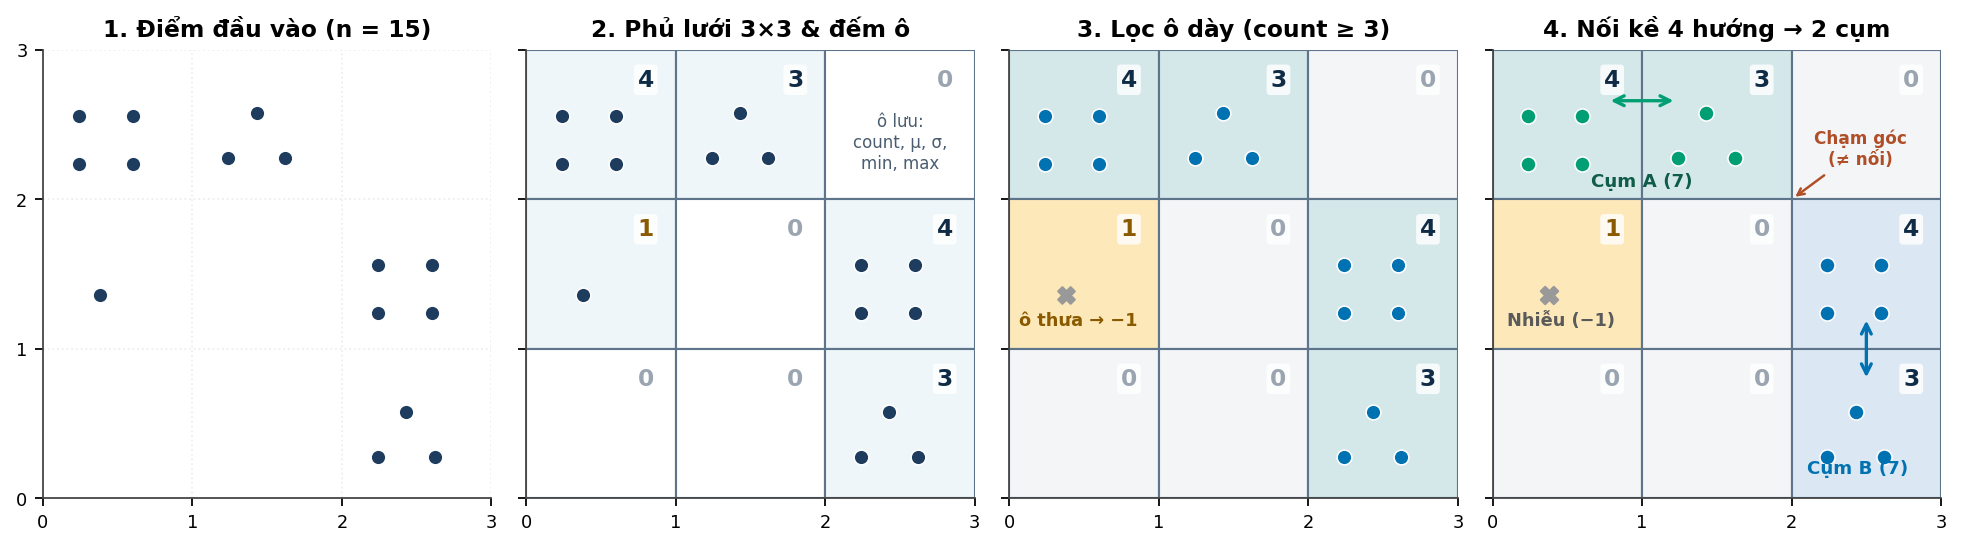

In [2]:
counts_3x3 = np.array([[4, 3, 0], [1, 0, 4], [0, 0, 3]])
positions_3x3 = [(col, 2 - row) for row in range(3) for col in range(3)]
points_3x3 = np.repeat(positions_3x3, counts_3x3.ravel(), axis=0)
model_3x3 = STING(n_levels=2, factor=3, min_count=3).fit(points_3x3)
labels_3x3 = model_3x3.cluster(level=1, connectivity=1)

cell_counts = np.zeros_like(counts_3x3)
for (x_idx, y_idx), cell in model_3x3.cells_[1].items():
    cell_counts[2 - y_idx, x_idx] = cell.count
print("Số điểm trong từng ô lưới 3×3:")
print(cell_counts)
assert np.array_equal(cell_counts, counts_3x3)

group_sizes = sorted(np.bincount(labels_3x3[labels_3x3 >= 0]).tolist())
noise_count_3x3 = int((labels_3x3 == -1).sum())
assert group_sizes == [7, 7] and noise_count_3x3 == 1
print(f"{model_3x3.n_clusters_} cụm, mỗi cụm {group_sizes[0]} điểm. {noise_count_3x3} điểm nhiễu.")
fig_steps = sting_steps_figure()
plt.show()

### 1.2 Kiểm chứng trên dữ liệu giả lập (240 điểm Gauss)

Nhóm sinh 240 điểm từ 2 cụm Gauss (`make_blobs`) để kiểm chứng bảo toàn số điểm qua mọi tầng lưới và đo mức khớp `ARI` (Adjusted Rand Index) với nhãn tham chiếu.

Dữ liệu giả lập 240 điểm: ARI = 0.950 | 2 cụm | Tỷ lệ nhiễu 2.5% (bảo toàn 240 điểm qua mọi mức lưới).


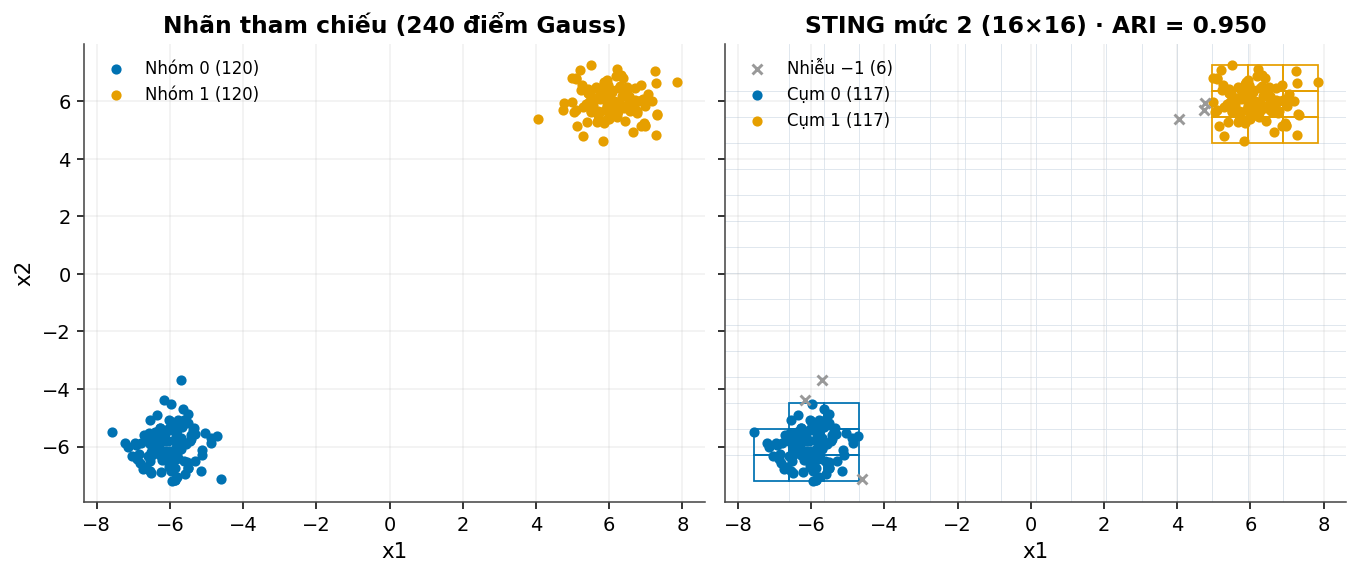

In [3]:
X_syn, y_syn_true = make_blobs(
    n_samples=240, centers=[(-6, -6), (6, 6)], cluster_std=0.6, random_state=42
)
m_syn = STING(n_levels=3, factor=4, min_count=3).fit(X_syn)
lab_syn = m_syn.cluster(level=2, connectivity=1)
for cells_at_level in m_syn.cells_.values():
    assert sum(cell.count for cell in cells_at_level.values()) == len(y_syn_true)
ari_syn = adjusted_rand_score(y_syn_true, lab_syn)
assert ari_syn >= 0.9
print(
    f"Dữ liệu giả lập 240 điểm: ARI = {ari_syn:.3f} | {m_syn.n_clusters_} cụm | "
    f"Tỷ lệ nhiễu {(lab_syn == -1).mean():.1%} (bảo toàn 240 điểm qua mọi mức lưới)."
)

res_syn = m_syn.factor ** 2
lo_s, hi_s = m_syn.bounds_min_, m_syn.bounds_max_
step_s = (hi_s - lo_s) / res_syn
with style_context():
    fig_s, axes_s = plt.subplots(1, 2, figsize=(9.6, 4.0), dpi=140, sharex=True, sharey=True, layout="constrained")
    for gid in sorted(set(y_syn_true)):
        mk = y_syn_true == gid
        axes_s[0].scatter(X_syn[mk, 0], X_syn[mk, 1], s=18, color=CLUSTER_COLORS[gid], label=f"Nhóm {gid} ({int(mk.sum())})")
    axes_s[0].set_title("Nhãn tham chiếu (240 điểm Gauss)")
    axes_s[0].set_xlabel("x1")
    axes_s[0].set_ylabel("x2")
    axes_s[0].grid(alpha=0.18)
    axes_s[0].legend(loc="upper left", fontsize=8.5)

    for i in range(1, res_syn):
        axes_s[1].axvline(lo_s[0] + i * step_s[0], color="#DCE4EC", linewidth=0.45, zorder=0.5)
        axes_s[1].axhline(lo_s[1] + i * step_s[1], color="#DCE4EC", linewidth=0.45, zorder=0.5)
    for idx_cell, cid in m_syn.label_of_.items():
        cell = m_syn.cells_[2][idx_cell]
        axes_s[1].add_patch(Rectangle(cell.bounds_min, *(cell.bounds_max - cell.bounds_min),
                                      facecolor="none", edgecolor=CLUSTER_COLORS[cid], linewidth=0.9, zorder=1.5))
    ns_s = lab_syn == -1
    axes_s[1].scatter(X_syn[ns_s, 0], X_syn[ns_s, 1], s=26, color=PALETTE["gray"], marker="x",
                      label=f"Nhiễu −1 ({int(ns_s.sum())})", zorder=3)
    for cid in sorted(set(lab_syn[lab_syn >= 0])):
        mk = lab_syn == cid
        axes_s[1].scatter(X_syn[mk, 0], X_syn[mk, 1], s=18, color=CLUSTER_COLORS[cid],
                          label=f"Cụm {cid} ({int(mk.sum())})", zorder=2.5)
    axes_s[1].set_title(f"STING mức 2 (16×16) · ARI = {ari_syn:.3f}")
    axes_s[1].set_xlabel("x1")
    axes_s[1].grid(alpha=0.18)
    axes_s[1].legend(loc="upper left", fontsize=8.5)
    plt.show()

## Phần 2. Dữ liệu PAPI 2011–2024, tiền xử lý và chuẩn hóa z-score

### 2.1 Chuỗi tiền xử lý 6 bước và sàng lọc thang đo

- **Bảng PAPI 2011–2024** (`papi_panel_63_2011_2024.csv`): **882 quan sát** (`63 tỉnh × 14 năm`) và **41 cột** (`39` cột số — đạt yêu cầu tối thiểu `≥ 500 × 10`).
- **Chuỗi `PREPROCESSING_PIPELINE` (`src/preprocessing.py`)**:
  1. **Làm sạch:** khử trùng khóa `(province_code, year)` (`0` trùng), quy `109` ô `0.0 → NaN` khớp quy ước Mendeley, tách `4.284` ô thiếu cấu trúc (`d7/d8` từ 2018) khỏi `365` ô thiếu trong cửa sổ (`13` dòng thiếu `sd_4_2` hoặc `sd_6_1`), giữ `869` quan sát đủ cả hai chỉ tiêu (gồm `61/63` tỉnh năm 2024); kiểm tra miền `[0, 10]` và `scale_audit` (`23/37` cột có bước nhảy cần đối chiếu workbook); đánh dấu ngoại lai `|z| > 3` nhưng **giữ nguyên điểm thật** vì xóa làm co biên lưới.
  2. **Tích hợp & chống rò rỉ:** khớp `1–1` với `external_master_63_2011_2024.csv` (`882 × 59`); học `StandardScaler` duy nhất trên `2011–2023` khi dựng lưới dự báo/gán 2024.

In [4]:
cfg = json.loads((ROOT / "models/predict_config.json").read_text(encoding="utf-8"))
feats = list(FEATURES)
assert feats == list(cfg["features"])
print("Hai chỉ tiêu PAPI dùng cho STING:")
for feature in feats:
    print(f"  • {cfg['feature_labels'][feature]} ({feature})")
print("Cấu hình STING:", cfg["sting"])

prep_state = run_preprocessing_pipeline(ROOT, features=feats)
pd.testing.assert_frame_equal(
    prep_state["panel"],
    panel.sort_values(["province_code", "year"]).reset_index(drop=True),
    check_dtype=False, check_exact=False, rtol=1e-12, atol=1e-12,
)
print(f"Đã chạy lại {len(PREPROCESSING_PIPELINE)} bước PREPROCESSING_PIPELINE từ 14 Excel gốc — khớp 100% bảng 882×41.")
display(pd.DataFrame(prep_state["log"], columns=["Bước trong PREPROCESSING_PIPELINE", "Kết quả thực thi"]))

audit = pd.read_csv(ROOT / "results/preprocessing_audit.csv")
display(audit[["stage", "test", "result", "decision"]].rename(columns={
    "stage": "Giai đoạn", "test": "Kiểm tra", "result": "Kết quả", "decision": "Quyết định",
}))

scale_meta = pd.read_csv(ROOT / "data/processed/papi_panel_scale_metadata.csv")
scale_flags = scale_audit(panel)
assert len(scale_meta) == 37 and len(scale_flags) == 23
chosen_meta = scale_meta.loc[scale_meta["cot"].isin(feats)]
assert (chosen_meta["thang_2011_2020"] == chosen_meta["thang_2021_2024"]).all()

ext_info = check_external_integration(panel, ROOT / "data/processed/external_master_63_2011_2024.csv")
assert ext_info["shape"] == (882, 59) and ext_info["cardinality"] == "one_to_one" and ext_info["same_keys"]

fs_summary, _ = feature_selection_summary(
    panel, prep_state["score_cols"], candidate_features=ALLOWLIST_FEATURES,
    flagged_names=prep_state["training_flagged_names"],
)
display(fs_summary[["Tên chỉ tiêu", "Min (≤cutoff)", "Max (≤cutoff)", "Phương sai (ddof=0)", "|r| max với biến khác", "Bị cờ scale_audit"]].round(4))
exp_df, _ = run_sting_preprocessing_experiments(panel, sting_cfg=cfg["sting"], features=feats)
display(exp_df)

Hai chỉ tiêu PAPI dùng cho STING:
  • 4.2 Kiểm soát tham nhũng trong cung ứng dịch vụ công (sd_4_2)
  • 6.1 Y tế công lập (sd_6_1)
Cấu hình STING: {'n_levels': 3, 'factor': 4, 'min_count': 5, 'cluster_level': 2, 'connectivity': 1}


Đã chạy lại 6 bước PREPROCESSING_PIPELINE từ 14 Excel gốc — khớp 100% bảng 882×41.


,Bước trong PREPROCESSING_PIPELINE,Kết quả thực thi
0,1. Cleaning — Deduplicate (đầu tiên),882 dòng (trùng toàn dòng: 0; trùng khóa tỉnh–...
1,2. Cleaning — Missing & 0.0→NaN,109 ô 0.0 → NaN; tổng 4649 ô NaN (4284 ngoài c...
2,3. Cleaning — Consistency & Scale Audit,"0 xung đột mã, 0 vi phạm miền. Toàn kỳ có 23/3..."
3,4. Cleaning — Flag outliers (cuối Cleaning),toàn panel: 122 ô/98 dòng/29 cột; train 2 biến...
4,5. Integration — Merge & Sort,"882 dòng × 41 cột, 63 tỉnh, 0 xung đột khóa"
5,6. Transformation — StandardScaler (≤2023),"train=(808, 2), holdout=(61, 2) (fit chỉ trên ..."


,Giai đoạn,Kiểm tra,Kết quả,Quyết định
0,1. Cleaning — (a) trùng khóa,"Trùng khóa (province_code, year), dedup chạy Đ...",0 dòng trùng / 882 dòng (882 khóa duy nhất); t...,Giữ đúng 1 dòng/khóa. Pipeline chặn cứng nếu p...
1,1. Cleaning — (b) giá trị thiếu,Ô thiếu trong 37 cột chỉ tiêu (8 chiều + tiểu ...,4649/32634 ô (14.2%). Có 4284 ô ngoài giai đoạ...,"KHÔNG nội suy, không điền: giữ NaN. Chỉ loại d..."
2,1. Cleaning — (b) giá trị thiếu,Dữ liệu thiếu ở hai chỉ tiêu phân cụm,13/882 dòng thiếu ít nhất một chỉ tiêu (22 ô)....,Giữ NaN trong bảng gốc. Dùng 869 dòng đủ hai c...
3,1. Cleaning — (c) nhất quán,Tên tỉnh vs crosswalk 63 tỉnh,0 xung đột; 63/63 mã khớp crosswalk,Tên/mã lấy từ crosswalk; mã không map được là ...
4,1. Cleaning — (c) nhất quán,Khoảng giá trị vs metadata thang đo,0 ô ngoài khoảng / 32634 ô (37 cột × 882 dòng),"Giữ nguyên giá trị; không cắt, không sửa theo ..."
5,1. Cleaning — (c) nhất quán,Giá trị ngoài cửa sổ thu thập của từng cột,0 ô,"Giữ; cửa sổ năm là metadata kiểm chứng, không ..."
6,1. Cleaning — (c) nhất quán,Điểm 0.0 (quy ước 'tỉnh không được xếp hạng'),0 ô điểm = 0.0 còn lại,0.0 → NaN ngay khi dựng panel để không lẫn với...
7,1. Cleaning — (d) ngoại lai (CUỐI CÙNG),Đánh dấu ngoại lai z-score > 3 (trị tuyệt đối),"122 ô (0.4%), 98 dòng, 29 cột","GIỮ toàn bộ — chỉ đánh dấu, không xóa. Cờ z-sc..."
8,2. Integration — khóa nối,Khóa nối duy nhất hai phía + quan hệ bản ghi,panel 0 trùng; master 0 trùng; quan hệ one_to_...,"Nối one-to-one theo (province_code, year); khô..."
9,2. Integration — số dòng,Số dòng trước/sau khi nối panel × master,882 → 882; 63 tỉnh; lưới khóa giống nhau: True,LEFT join giữ đúng lưới panel; ô dữ liệu bên n...


,Tên chỉ tiêu,Min (≤cutoff),Max (≤cutoff),Phương sai (ddof=0),|r| max với biến khác,Bị cờ scale_audit
sd_1_3,1.3 Chất lượng bầu cử,1.0186,1.8971,0.0255,0.2408,False
sd_1_4,1.4 Đóng góp tự nguyện,0.4248,1.7958,0.0544,0.4400,False
sd_4_1,4.1 Kiểm soát tham nhũng trong chính quyền địa...,0.7040,2.1993,0.0525,0.8412,False
sd_4_2,4.2 Kiểm soát tham nhũng trong cung ứng dịch v...,1.1753,2.3557,0.0332,0.8412,False
sd_4_3,4.3 Công bằng trong tuyển dụng vào khu vực công,0.4630,1.7242,0.0485,0.8151,False
sd_4_4,4.4 Quyết tâm chống tham nhũng của chính quyền...,0.9754,2.1496,0.0268,0.5036,False
sd_6_1,6.1 Y tế công lập,1.4348,2.2153,0.0193,0.5089,False
sd_6_3,6.3 Cơ sở hạ tầng căn bản,1.1978,2.4639,0.0676,0.4453,False


,Số dòng,Số cụm,Số ô dày,Điểm nhiễu (−1),Tỷ lệ nhiễu,Giữ nguyên ô vs z-score
1. Pipeline chọn (dropna + giữ |z|>3 + StandardScaler),808,3,56,158,19.6%,808/808 (chuẩn)
2. Cleaning: Xóa 7 điểm |z|>3 (co biên lưới),801,4,59,197,24.6%,n/a (đổi mẫu)
3. Cleaning: Điền SimpleImputer(median) cho 11 dòng thiếu,819,3,56,160,19.5%,n/a (đổi mẫu)
4. Transform: Điểm gốc (không scale),808,3,56,158,19.6%,808/808
"5. Transform: MinMaxScaler [0, 1] (affine)",808,3,56,158,19.6%,808/808
6. Transform: QuantileTransformer (phi tuyến),808,24,62,403,49.9%,9/808


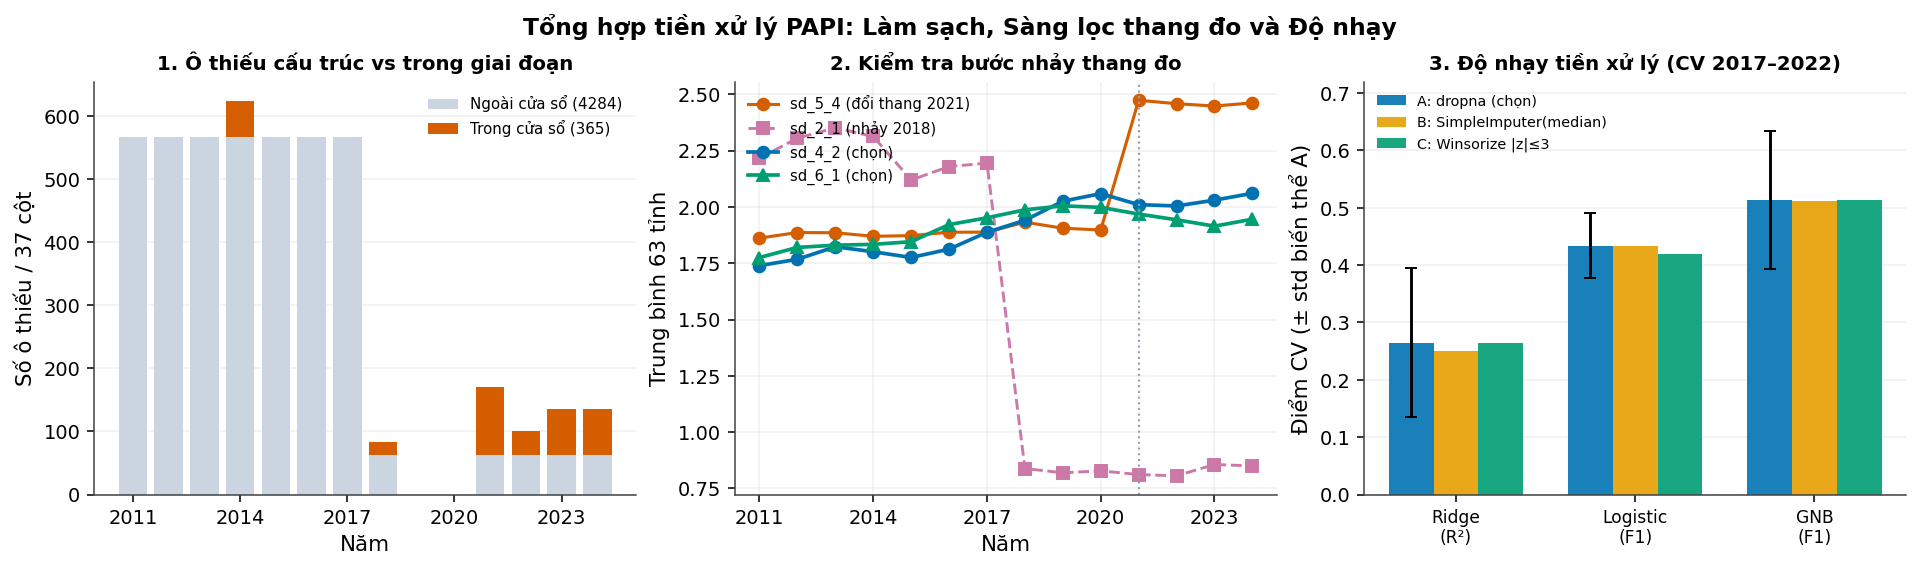

In [5]:
sens = pd.read_csv(ROOT / "results/preprocessing_sensitivity.csv")
by_year = prep_state["missing_summary"]["by_year"]
yearly_means = panel.groupby("year")[["sd_5_4", "sd_2_1", "sd_4_2", "sd_6_1"]].mean()

with style_context():
    fig, (ax_m, ax_s, ax_cv) = plt.subplots(1, 3, figsize=(13.6, 3.95), dpi=140, layout="constrained")
    yrs = by_year["Năm"].to_numpy()
    s_miss = by_year["Thiếu cấu trúc (ngoài cửa sổ)"].to_numpy()
    w_miss = by_year["Thiếu trong cửa sổ"].to_numpy()
    ax_m.bar(yrs, s_miss, color="#CBD5E1", label=f"Ngoài cửa sổ ({int(s_miss.sum())})")
    ax_m.bar(yrs, w_miss, bottom=s_miss, color="#D55E00", label=f"Trong cửa sổ ({int(w_miss.sum())})")
    ax_m.set_title("1. Ô thiếu cấu trúc vs trong giai đoạn", fontsize=10.2)
    ax_m.set_xlabel("Năm")
    ax_m.set_ylabel("Số ô thiếu / 37 cột")
    ax_m.set_xticks(yrs[::3])
    ax_m.grid(axis="y", alpha=0.18)
    ax_m.legend(loc="upper right", fontsize=7.8, framealpha=0.92)

    ax_s.plot(yearly_means.index, yearly_means["sd_5_4"], "o-", color="#D55E00", lw=1.6, label="sd_5_4 (đổi thang 2021)")
    ax_s.plot(yearly_means.index, yearly_means["sd_2_1"], "s--", color=PALETTE["purple"], lw=1.5, label="sd_2_1 (nhảy 2018)")
    ax_s.plot(yearly_means.index, yearly_means["sd_4_2"], "o-", color=PALETTE["blue"], lw=1.9, label="sd_4_2 (chọn)")
    ax_s.plot(yearly_means.index, yearly_means["sd_6_1"], "^-", color=PALETTE["green"], lw=1.9, label="sd_6_1 (chọn)")
    ax_s.axvline(2021, color="#94A3B8", linestyle=":", lw=1.1)
    ax_s.set_title("2. Kiểm tra bước nhảy thang đo", fontsize=10.2)
    ax_s.set_xlabel("Năm")
    ax_s.set_ylabel("Trung bình 63 tỉnh")
    ax_s.set_xticks(yrs[::3])
    ax_s.grid(alpha=0.18)
    ax_s.legend(loc="upper left", fontsize=7.6, framealpha=0.92)

    models_order = [("regression", "ridge", "Ridge\n(R²)"), ("classification", "logistic regression", "Logistic\n(F1)"), ("classification", "gaussian naive bayes", "GNB\n(F1)")]
    x_m = np.arange(len(models_order))
    w_m = 0.25
    colors_v = {"A": PALETTE["blue"], "B": PALETTE["orange"], "C": PALETTE["green"]}
    labels_v = {"A": "A: dropna (chọn)", "B": "B: SimpleImputer(median)", "C": "C: Winsorize |z|≤3"}
    for idx_v, var in enumerate(("A", "B", "C")):
        vals = [float(sens.loc[(sens.task == t) & (sens.model == m) & (sens.variant == var), "value_cv"].iat[0]) for t, m, _ in models_order]
        errs = [float(sens.loc[(sens.task == t) & (sens.model == m) & (sens.variant == var), "cv_std"].iat[0]) for t, m, _ in models_order]
        ax_cv.bar(x_m + (idx_v - 1) * w_m, vals, width=w_m, color=colors_v[var], yerr=errs if var == "A" else None,
                  capsize=3, label=labels_v[var], alpha=0.9)
    ax_cv.set_xticks(x_m, [lbl for _, _, lbl in models_order], fontsize=8.8)
    ax_cv.set_ylim(0.0, 0.72)
    ax_cv.set_ylabel("Điểm CV (± std biến thể A)")
    ax_cv.set_title("3. Độ nhạy tiền xử lý (CV 2017–2022)", fontsize=10.2)
    ax_cv.grid(axis="y", alpha=0.18)
    ax_cv.legend(loc="upper left", fontsize=7.4, framealpha=0.92)
    fig.suptitle("Tổng hợp tiền xử lý PAPI: Làm sạch, Sàng lọc thang đo và Độ nhạy", fontsize=12.0)
    plt.show()

### 2.2 Chuẩn hóa z-score từ số liệu thật (ví dụ Lạng Sơn 2024)

Trên `869` quan sát đủ hai chỉ tiêu giai đoạn 2011–2024 (trong đó năm 2024 đóng góp `61/63` tỉnh), mỗi trục được chuẩn hóa bằng **z = (x − μ) / σ** (`StandardScaler`, chia `n` tức `ddof=0`). Ví dụ **Lạng Sơn năm 2024** đạt `z_4.2 = 0,9005` và `z_6.1 = 0,3737`.

In [6]:
complete = panel.dropna(subset=feats).copy()
Xraw = complete[feats].to_numpy(dtype=float)
full_scaler = StandardScaler().fit(complete[feats])
Xz = full_scaler.transform(complete[feats])

total_2024 = int(panel.year.eq(2024).sum())
eligible_2024_cnt = int(complete.year.eq(2024).sum())
missing_cells = int(panel[feats].isna().sum().sum())
print(f"869 quan sát đủ hai chỉ tiêu ({len(complete)}/882); năm 2024 đóng góp {eligible_2024_cnt}/{total_2024} quan sát.")
print(f"Hai chỉ tiêu có {missing_cells} ô thiếu trên {len(panel) - len(complete)} dòng tỉnh–năm.")

example_mask = complete.province_vi.eq("Lạng Sơn") & complete.year.eq(2024)
example_raw = complete.loc[example_mask, feats].iloc[0].to_numpy()
means_full = complete[feats].mean().to_numpy()
stds_full = complete[feats].std(ddof=0).to_numpy()
z_example = (example_raw - means_full) / stds_full
np.testing.assert_allclose(z_example, full_scaler.transform(complete.loc[example_mask, feats])[0])
for feature, x_v, mu_v, sig_v, z_v in zip(feats, example_raw, means_full, stds_full, z_example, strict=True):
    print(f"Lạng Sơn 2024 · {feature}: ({x_v:.6f} − {mu_v:.6f}) / {sig_v:.6f} = {z_v:.4f}")
display(pd.DataFrame({
    "Chỉ tiêu": [FEATURE_LABELS[f] for f in feats],
    "Điểm gốc x": example_raw,
    "Trung bình μ": means_full,
    "Độ lệch chuẩn σ": stds_full,
    "z-score": z_example,
}).round(4))

869 quan sát đủ hai chỉ tiêu (869/882); năm 2024 đóng góp 61/63 quan sát.
Hai chỉ tiêu có 22 ô thiếu trên 13 dòng tỉnh–năm.
Lạng Sơn 2024 · sd_4_2: (2.072702 − 1.908406) / 0.182448 = 0.9005
Lạng Sơn 2024 · sd_6_1: (1.959565 − 1.908428) / 0.136835 = 0.3737


,Chỉ tiêu,Điểm gốc x,Trung bình μ,Độ lệch chuẩn σ,z-score
0,4.2 Kiểm soát tham nhũng trong cung ứng dịch v...,2.0727,1.9084,0.1824,0.9005
1,6.1 Y tế công lập,1.9596,1.9084,0.1368,0.3737


## Phần 3. Phân cụm STING trên PAPI, đối chiếu K-Means/DBSCAN & độ nhạy

### 3.1 STING trên toàn kỳ 869 quan sát vs lưới tham chiếu 2011–2023 (808 quan sát)

- Trên toàn mẫu **869 quan sát (2011–2024)**, lưới `16 × 16` (`min_count = 5`, kề 4 hướng) tạo **56 ô dày thành 3 vùng liên thông**: cụm lớn **677 quan sát (52 ô dày)**, hai cụm nhỏ **16 (3 ô)** và **5 (1 ô)**, còn lại **171/869 điểm nhiễu (19,7%)**. Trong `171` điểm `−1`, có tới **`162/171` điểm nằm trong khung `|z| ≤ 3`** (nhiễu là ô thưa hợp lệ chứ không phải ngoại lai `|z| > 3`!). Nếu xóa `9` điểm `|z| > 3` rồi dựng lại lưới trên `860` điểm, biên co lại khiến số cụm thành `4` và nhiễu tăng lên `173/860 (20,1%)`.
- Để kiểm tra ngoài mẫu cho năm 2024, nhánh chính của đồ án tách rạch ròi: **fit `StandardScaler` và lưới STING duy nhất trên 808 quan sát giai đoạn 2011–2023** (tạo `629 + 16 + 5` điểm vào cụm, `158` điểm nhiễu `19,6%`) và khớp 100% nhãn đã khóa trong `results/predict_all_years.csv`.

In [7]:
grid_model, lab = fit_grid(Xz)
points_per_cluster = Counter(lab)
cells_per_cluster = Counter(grid_model.label_of_.values())
cell_stats = grid_model.cells_[grid_model.cluster_level_]
grid_width = GRID["factor"] ** GRID["cluster_level"]

print(f"{len(grid_model.label_of_)} ô dày tạo thành {grid_model.n_clusters_} vùng liên thông.")
for grp in sorted(cells_per_cluster):
    print(f"Cụm {grp}: {cells_per_cluster[grp]} ô dày, {points_per_cluster[grp]} quan sát.")
noise_all = points_per_cluster[-1]
print(f"Nhiễu: {noise_all}/{len(lab)} quan sát ({noise_all / len(lab):.1%}).")

z_flag = (np.abs(Xz) > 3).any(axis=1)
sparse_no_flag = int(((lab == -1) & ~z_flag).sum())
print(f"{sparse_no_flag}/{noise_all} điểm nhãn −1 có |z| ≤ 3 trên cả hai trục.")
trimmed_all, trimmed_all_lab = fit_grid(Xz[~z_flag])
trimmed_all_noise = int((trimmed_all_lab == -1).sum())
print(
    f"Nếu loại {z_flag.sum()} điểm |z| > 3 rồi dựng lại lưới trên {len(trimmed_all_lab)} điểm: "
    f"{trimmed_all.n_clusters_} cụm, {trimmed_all_noise}/{len(trimmed_all_lab)} điểm nhiễu "
    f"({trimmed_all_noise / len(trimmed_all_lab):.1%})."
)

step_grid = (grid_model.bounds_max_ - grid_model.bounds_min_) / grid_width
rel_pos = (z_example - grid_model.bounds_min_) / step_grid
example_cell = tuple(np.clip(np.floor(rel_pos).astype(int), 0, grid_width - 1).tolist())
example_label = grid_model.label_of_.get(example_cell, -1)
print(f"Lạng Sơn 2024 vào ô {example_cell} (đếm từ 0), ô có {cell_stats[example_cell].count} quan sát, nhãn cụm {example_label}.")

# Dựng lưới đóng băng 2011-2023 và kiểm tra tái lập artifact predict_all_years.csv
params = cfg["sting"]
train = panel[panel.year <= 2023].dropna(subset=feats)
scaler = StandardScaler().fit(train[feats])
train_scaled = scaler.transform(train[feats])
sting = STING(n_levels=params["n_levels"], factor=params["factor"], min_count=params["min_count"]).fit(train_scaled)
train_labels = sting.cluster(level=params["cluster_level"], connectivity=params["connectivity"])

eligible = panel.dropna(subset=feats)
rebuilt = eligible[["province_code", "year"]].assign(pred_cluster=sting.predict(scaler.transform(eligible[feats])))
saved = pd.read_csv(ROOT / "results/predict_all_years.csv")
comparison = rebuilt.merge(saved, on=["province_code", "year"], suffixes=("_rebuilt", "_saved"), validate="one_to_one")
assert len(comparison) == len(saved) == len(eligible)
np.testing.assert_array_equal(comparison.pred_cluster_rebuilt, comparison.pred_cluster_saved)
loaded_sting = STING.load(ROOT / "models/sting_predict_model.pkl")
scale_info = json.loads((ROOT / "models/sting_predict_scaler.json").read_text(encoding="utf-8"))
loaded_scaled = (eligible[feats].to_numpy() - np.array(scale_info["mean"])) / np.array(scale_info["scale"])
np.testing.assert_array_equal(loaded_sting.predict(loaded_scaled), rebuilt.pred_cluster.to_numpy())
print(f"Tái lập lưới 2011–2023: {len(comparison)}/{len(saved)} nhãn khớp tuyệt đối với results/predict_all_years.csv.")

56 ô dày tạo thành 3 vùng liên thông.
Cụm 0: 1 ô dày, 5 quan sát.
Cụm 1: 3 ô dày, 16 quan sát.
Cụm 2: 52 ô dày, 677 quan sát.
Nhiễu: 171/869 quan sát (19.7%).
162/171 điểm nhãn −1 có |z| ≤ 3 trên cả hai trục.
Nếu loại 9 điểm |z| > 3 rồi dựng lại lưới trên 860 điểm: 4 cụm, 173/860 điểm nhiễu (20.1%).
Lạng Sơn 2024 vào ô (12, 10) (đếm từ 0), ô có 17 quan sát, nhãn cụm 2.
Tái lập lưới 2011–2023: 869/869 nhãn khớp tuyệt đối với results/predict_all_years.csv.


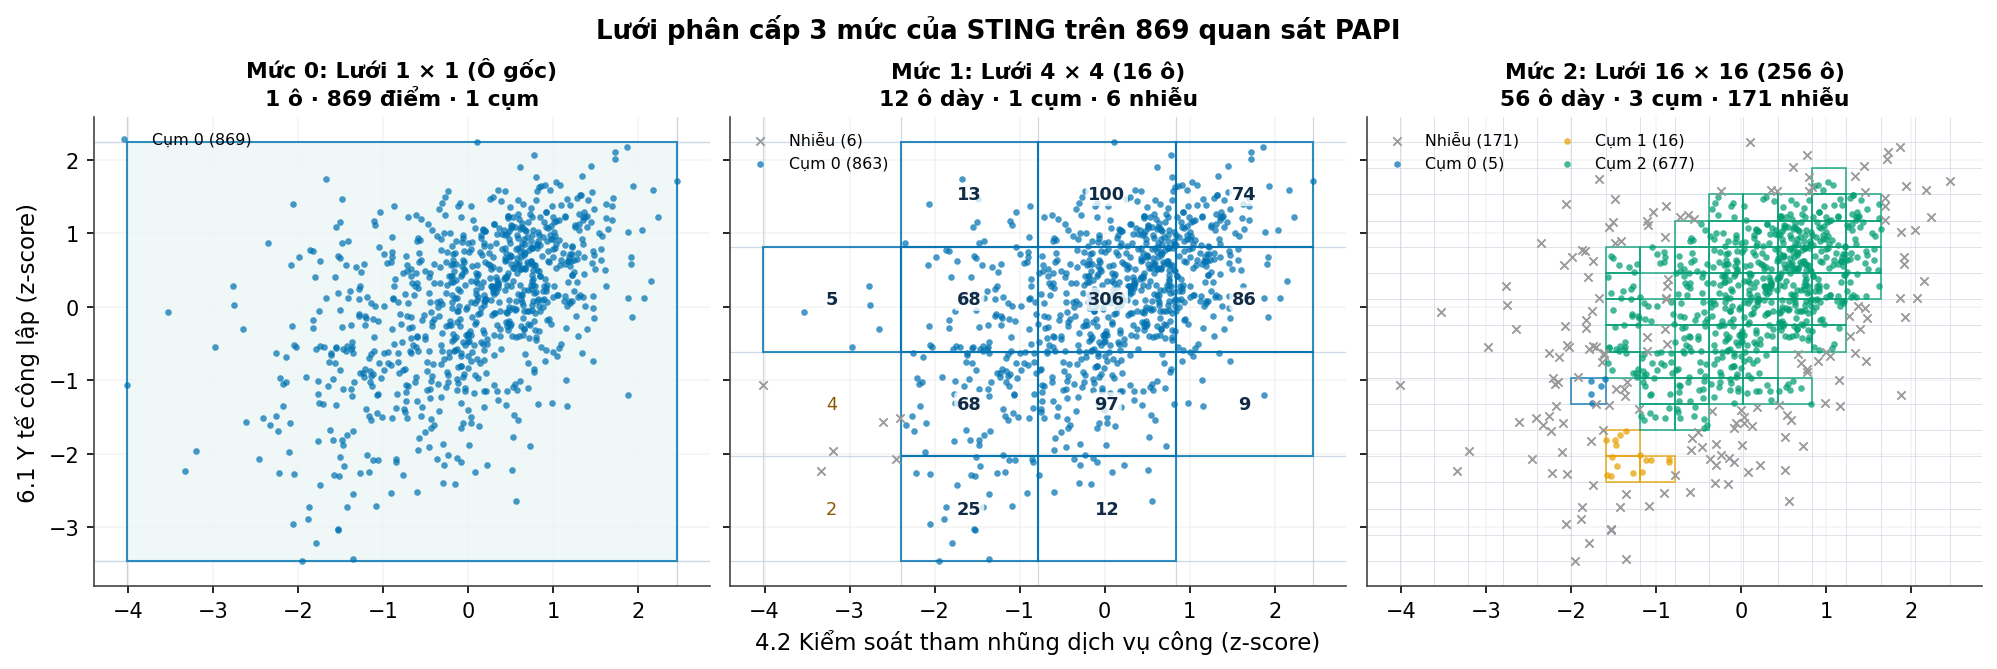

Truy vấn từ trên xuống tổng hợp 322 điểm trong các ô nằm trọn vùng [0; 2,5]².
Đếm trực tiếp từng điểm trong vùng: 348 điểm.


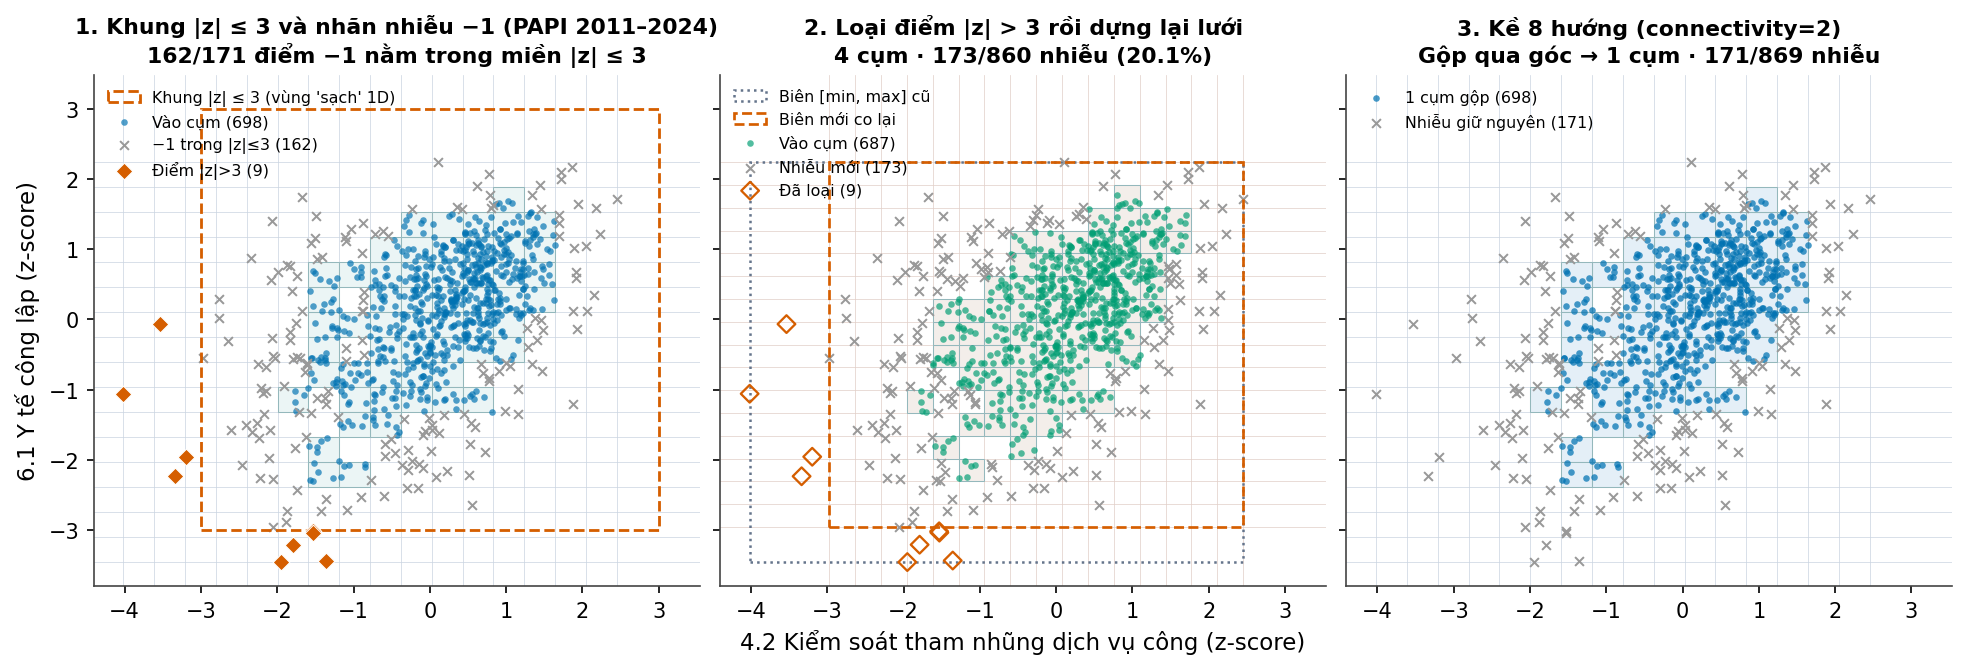

In [8]:
fig_h = hierarchy_levels_figure(Xz)
plt.show()

q_box = [(0.0, 2.5), (0.0, 2.5)]
res_full = grid_model.query_rect(q_box, level=grid_model.cluster_level_)
res_td = grid_model.query_top_down(q_box, confidence=0.95, level=grid_model.cluster_level_)
assert res_td["count"] == res_full["count"]
np.testing.assert_allclose(res_td["mean"], res_full["mean"])
exact_q = int(((Xz >= [0.0, 0.0]) & (Xz <= [2.5, 2.5])).all(axis=1).sum())
print(f"Truy vấn từ trên xuống tổng hợp {res_td['count']} điểm trong các ô nằm trọn vùng [0; 2,5]².")
print(f"Đếm trực tiếp từng điểm trong vùng: {exact_q} điểm.")

fig_n = noise_and_trap_figure(Xz, grid_model, lab, title_prefix="PAPI 2011–2024")
plt.show()

### 3.2 Đối chiếu K-Means, DBSCAN, bất biến chuẩn hóa z-score và độ nhạy tham số

1. **Chọn `k = 2` cho K-Means** qua cực đại silhouette (`k = 2: 0,4472` trên 869 điểm; `0,445` trên 808 điểm train).
2. **So sánh công bằng trên cùng tập giao không nhiễu** (cả mẫu toàn kỳ `680/869` lẫn mẫu train `631/808`): đọc silhouette kèm tỉ lệ nhiễu và số cụm.
3. **Vai trò z-score (`StandardScaler`):** Vì lưới chia đều theo biên `[min, max]` từng trục, biến đổi tuyến tính giữ nguyên **869/869 chỉ số ô** của STING, trong khi K-Means `k = 2` làm **68/869 điểm đổi nhóm** (`ARI = 0,7103`) và DBSCAN có bán kính tương đương làm **8/869 điểm đổi trạng thái nhiễu**.
4. **Độ nhạy cấu hình STING** theo ngưỡng `min_count` (3 / 5 / 8), mức lưới (0 / 1 / 2), quy tắc kề 8 hướng (`connectivity = 2`) và bộ lọc heuristic ô con–ô cha `significance_z = 2,0`. Bộ lọc này không phải kiểm định z độc lập ở mức tin cậy 95%, vì ô con nằm trong ô cha; cấu hình chính không bật bộ lọc.

k=2  |  Silhouette = 0.4472
k=3  |  Silhouette = 0.3354
k=4  |  Silhouette = 0.3649


k=5  |  Silhouette = 0.3311
K-means chọn k=2 trong các giá trị đã thử và gán đủ 869 điểm.
Silhouette trên cùng 680/869 điểm (toàn kỳ 869):
  STING | silhouette cùng tập = 0.3802
  K-means k=2 | silhouette cùng tập = 0.4605
  DBSCAN | silhouette cùng tập = 0.2740
  K-means k=3 | silhouette cùng tập = 0.3499


,Phương pháp (869),Số cụm,Điểm nhiễu,Silhouette riêng,Silhouette trên 680 điểm
0,STING,3,171,0.3759,0.3802
1,K-means k=2,2,0,0.4472,0.4605
2,DBSCAN,6,120,0.1682,0.2740
3,K-means k=3,3,0,0.3354,0.3499


K-means k=2 chia 677 điểm Cụm lớn STING thành 482 + 195.
K-means k=3 chia 677 điểm Cụm lớn STING thành 306 + 303 + 68.


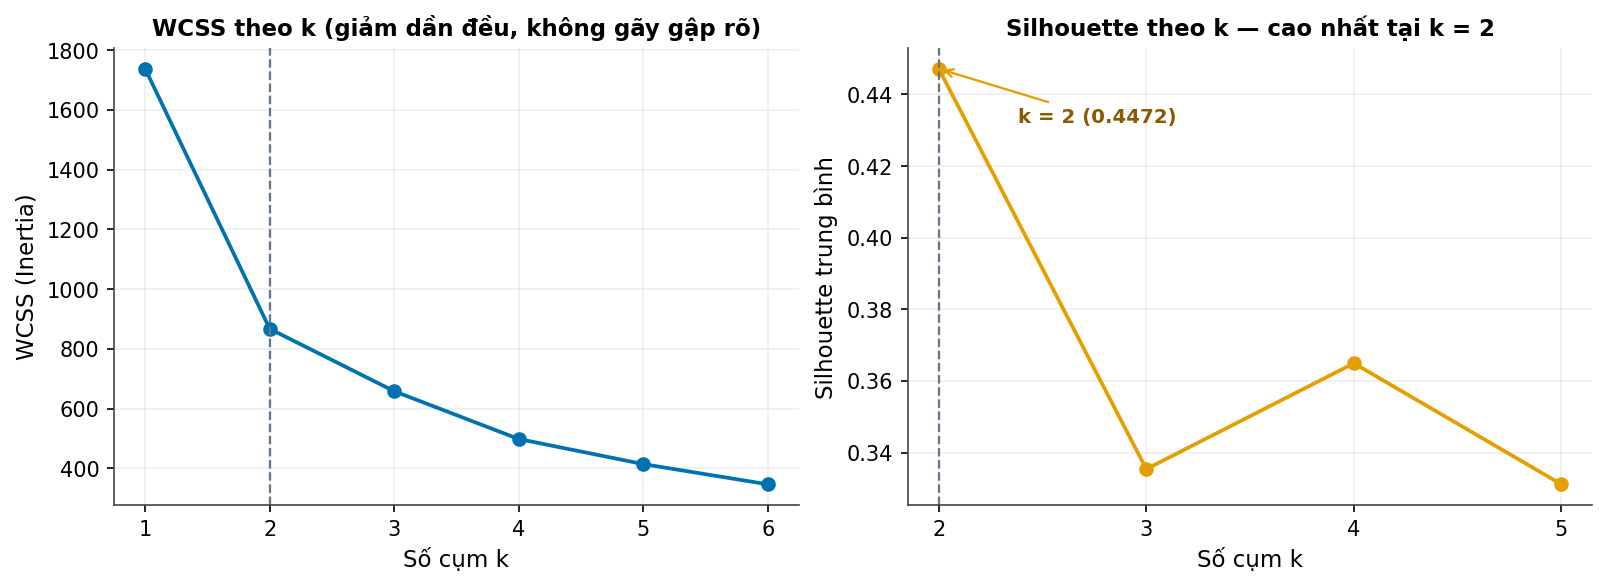

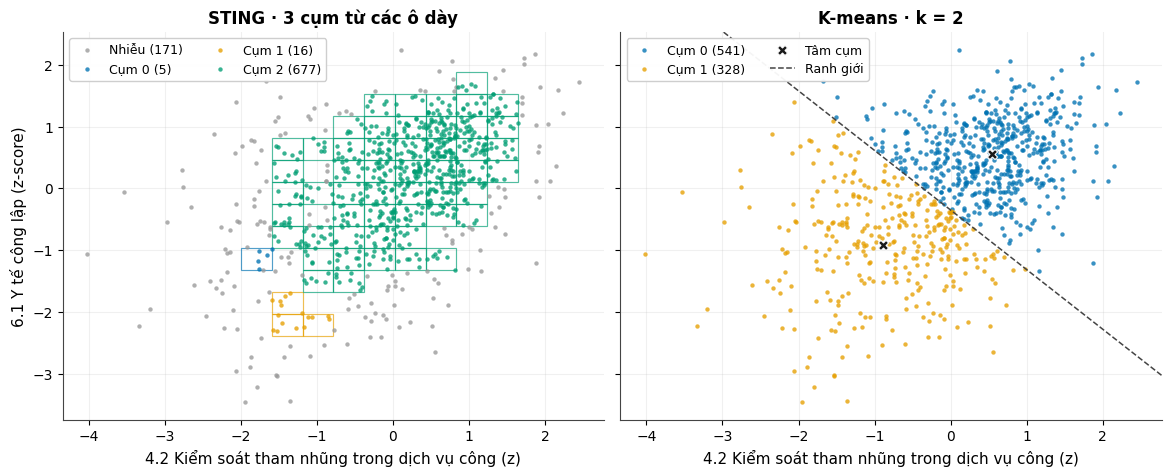

In [9]:
models_km = {}
sil_by_k = {}
for k_val in K_CANDIDATES:
    fit_k = KMeans(n_clusters=k_val, **KMEANS_OPTIONS).fit(Xz)
    models_km[k_val] = fit_k
    sil_by_k[k_val] = silhouette_score(Xz, fit_k.labels_)
    print(f"k={k_val}  |  Silhouette = {sil_by_k[k_val]:.4f}")

best_k = max(sil_by_k, key=sil_by_k.get)
km_all = models_km[best_k]
print(f"K-means chọn k={best_k} trong các giá trị đã thử và gán đủ {len(km_all.labels_)} điểm.")

db_all = DBSCAN(**DBSCAN_OPTIONS).fit(Xz)
assign_869 = {"STING": lab, f"K-means k={best_k}": km_all.labels_, "DBSCAN": db_all.labels_, "K-means k=3": models_km[3].labels_}
common_680 = (lab >= 0) & (db_all.labels_ >= 0)
print(f"Silhouette trên cùng {common_680.sum()}/{len(lab)} điểm (toàn kỳ 869):")
rows_cmp = []
for mname, lbls in assign_869.items():
    sil_c = silhouette_score(Xz[common_680], lbls[common_680])
    print(f"  {mname} | silhouette cùng tập = {sil_c:.4f}")
    rows_cmp.append((mname, len(set(lbls[lbls >= 0])), int((lbls == -1).sum()), clustered_silhouette(Xz, lbls), sil_c))
display(pd.DataFrame(rows_cmp, columns=["Phương pháp (869)", "Số cụm", "Điểm nhiễu", "Silhouette riêng", "Silhouette trên 680 điểm"]).round(4))

biggest_cid = max(cells_per_cluster, key=points_per_cluster.get)
for k_val in (2, 3):
    ct = pd.crosstab(lab, models_km[k_val].labels_)
    sizes = sorted(ct.loc[biggest_cid].tolist(), reverse=True)
    print(f"K-means k={k_val} chia {points_per_cluster[biggest_cid]} điểm Cụm lớn STING thành {' + '.join(map(str, sizes))}.")

fig_elb = kmeans_elbow_figure(Xz)
plt.show()
fig_cmp_mid = comparison_figure(Xz, grid_model, lab, km_all)
plt.show()

STING: 869/869 điểm cùng chỉ số ô, 869/869 nhãn trùng.
K-means k=2: 68/869 điểm đổi nhóm sau ghép tên cụm. ARI = 0.7103.
DBSCAN: ε gốc = 0.0316, 5 cụm, 116 nhiễu → sau chuẩn hóa 6 cụm, 120 nhiễu, 8/869 điểm đổi trạng thái nhiễu (6 sang nhiễu, 2 vào cụm).


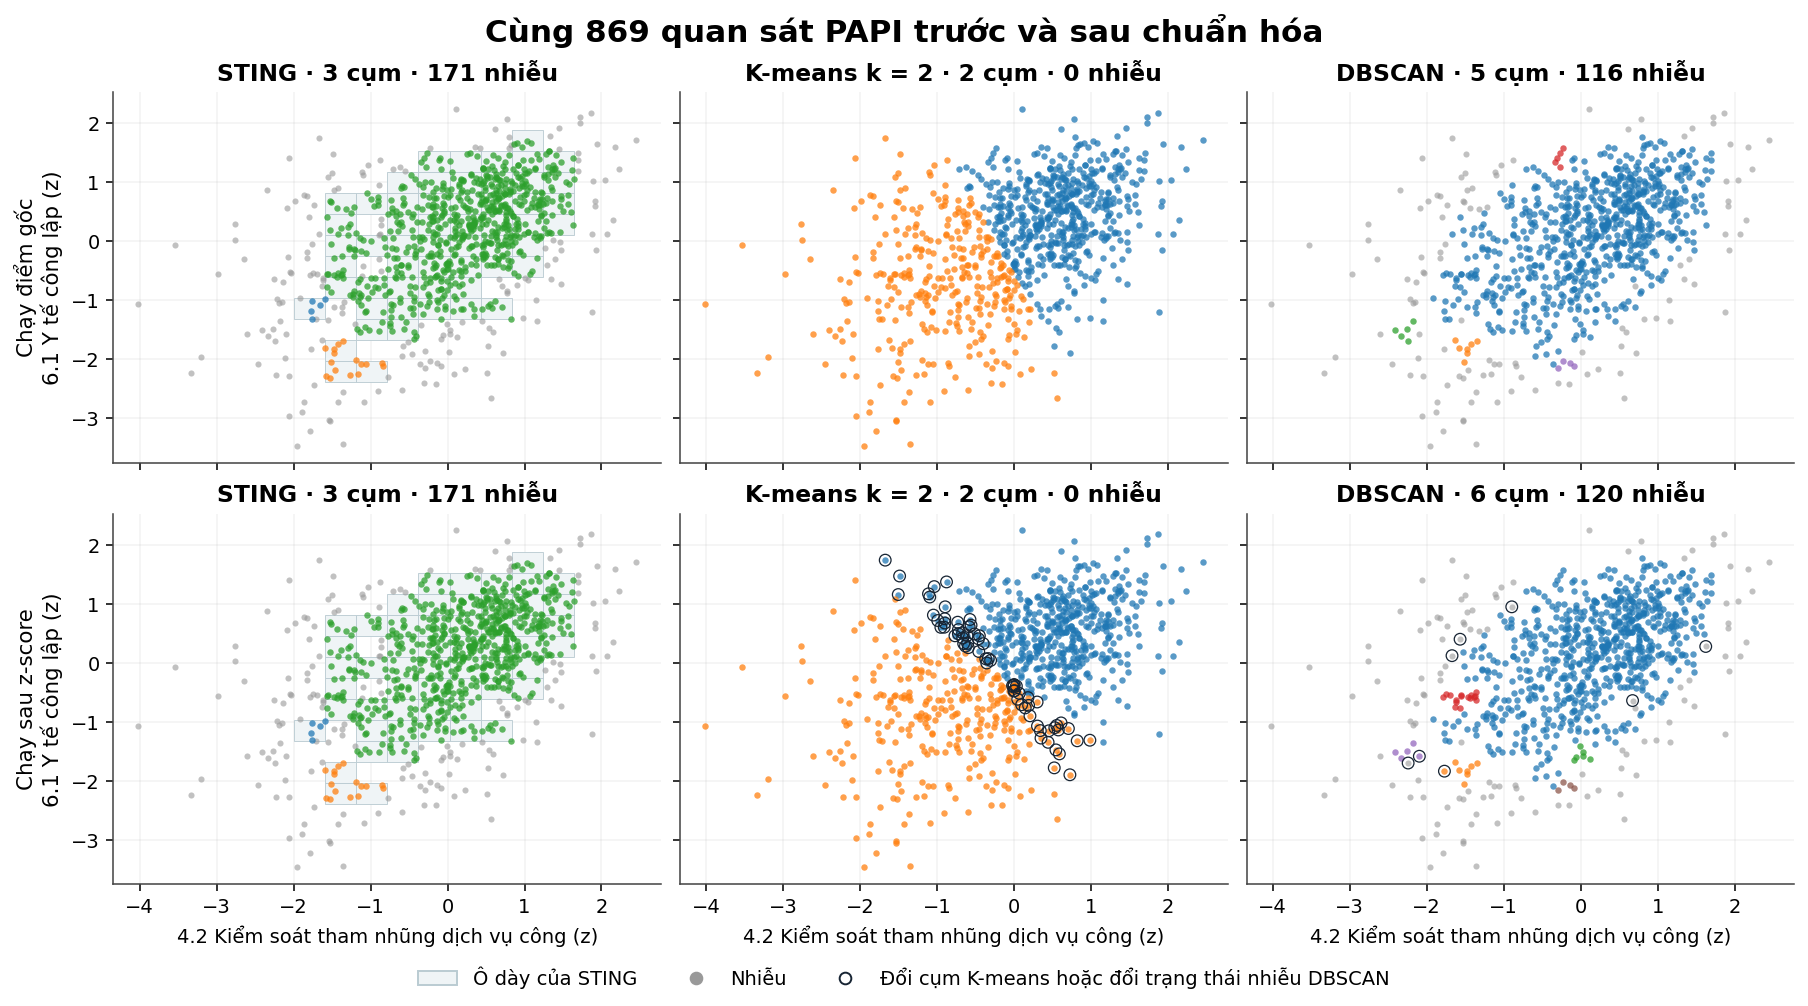

In [10]:
raw_grid, raw_labels = fit_grid(Xraw)
idx_raw = raw_grid.point_cell_index(grid_model.cluster_level_)
idx_z = grid_model.point_cell_index(grid_model.cluster_level_)
print(f"STING: {int((idx_raw == idx_z).all(axis=1).sum())}/{len(lab)} điểm cùng chỉ số ô, {int((raw_labels == lab).sum())}/{len(lab)} nhãn trùng.")

km2_raw = KMeans(n_clusters=2, **KMEANS_OPTIONS).fit_predict(Xraw)
km2_z = models_km[2].labels_
same_ids = int((km2_raw == km2_z).sum())
km2_disp = km2_z if same_ids >= len(km2_z) - same_ids else 1 - km2_z
km_changed = km2_raw != km2_disp
print(f"K-means k=2: {int(km_changed.sum())}/{len(km2_z)} điểm đổi nhóm sau ghép tên cụm. ARI = {adjusted_rand_score(km2_raw, km2_z):.4f}.")

eps_raw = raw_dbscan_radius(full_scaler.scale_)
db_raw = DBSCAN(eps=eps_raw, min_samples=DBSCAN_OPTIONS["min_samples"]).fit_predict(Xraw)
db_changed = (db_raw == -1) != (db_all.labels_ == -1)
print(
    f"DBSCAN: ε gốc = {eps_raw:.4f}, {len(set(db_raw[db_raw >= 0]))} cụm, {(db_raw == -1).sum()} nhiễu → "
    f"sau chuẩn hóa {len(set(db_all.labels_[db_all.labels_ >= 0]))} cụm, {(db_all.labels_ == -1).sum()} nhiễu, "
    f"{int(db_changed.sum())}/{len(db_raw)} điểm đổi trạng thái nhiễu "
    f"({int(((db_raw >= 0) & (db_all.labels_ == -1)).sum())} sang nhiễu, {int(((db_raw == -1) & (db_all.labels_ >= 0)).sum())} vào cụm)."
)

fig_scale = scaling_comparison_figure(Xz, grid_model, (
    ("STING", raw_labels, lab, raw_labels != lab),
    ("K-means k = 2", km2_raw, km2_disp, km_changed),
    ("DBSCAN", db_raw, db_all.labels_, db_changed),
))
plt.show()

Ngưỡng 3  |  3 cụm  |  85/869 nhiễu (9.8%)
Ngưỡng 5  |  3 cụm  |  171/869 nhiễu (19.7%)
Ngưỡng 8  |  1 cụm  |  271/869 nhiễu (31.2%)
Lưới 1 × 1 | 1 ô dày | 1 cụm | 0/869 nhiễu
Lưới 4 × 4 | 12 ô dày | 1 cụm | 6/869 nhiễu
Lưới 16 × 16 | 56 ô dày | 3 cụm | 171/869 nhiễu
Kề 8 hướng (connectivity=2) | 56 ô dày | 1 cụm | 171/869 nhiễu
Thêm significance_z=2.0: 46 ô đạt, 4 cụm, 270/869 điểm nhiễu.


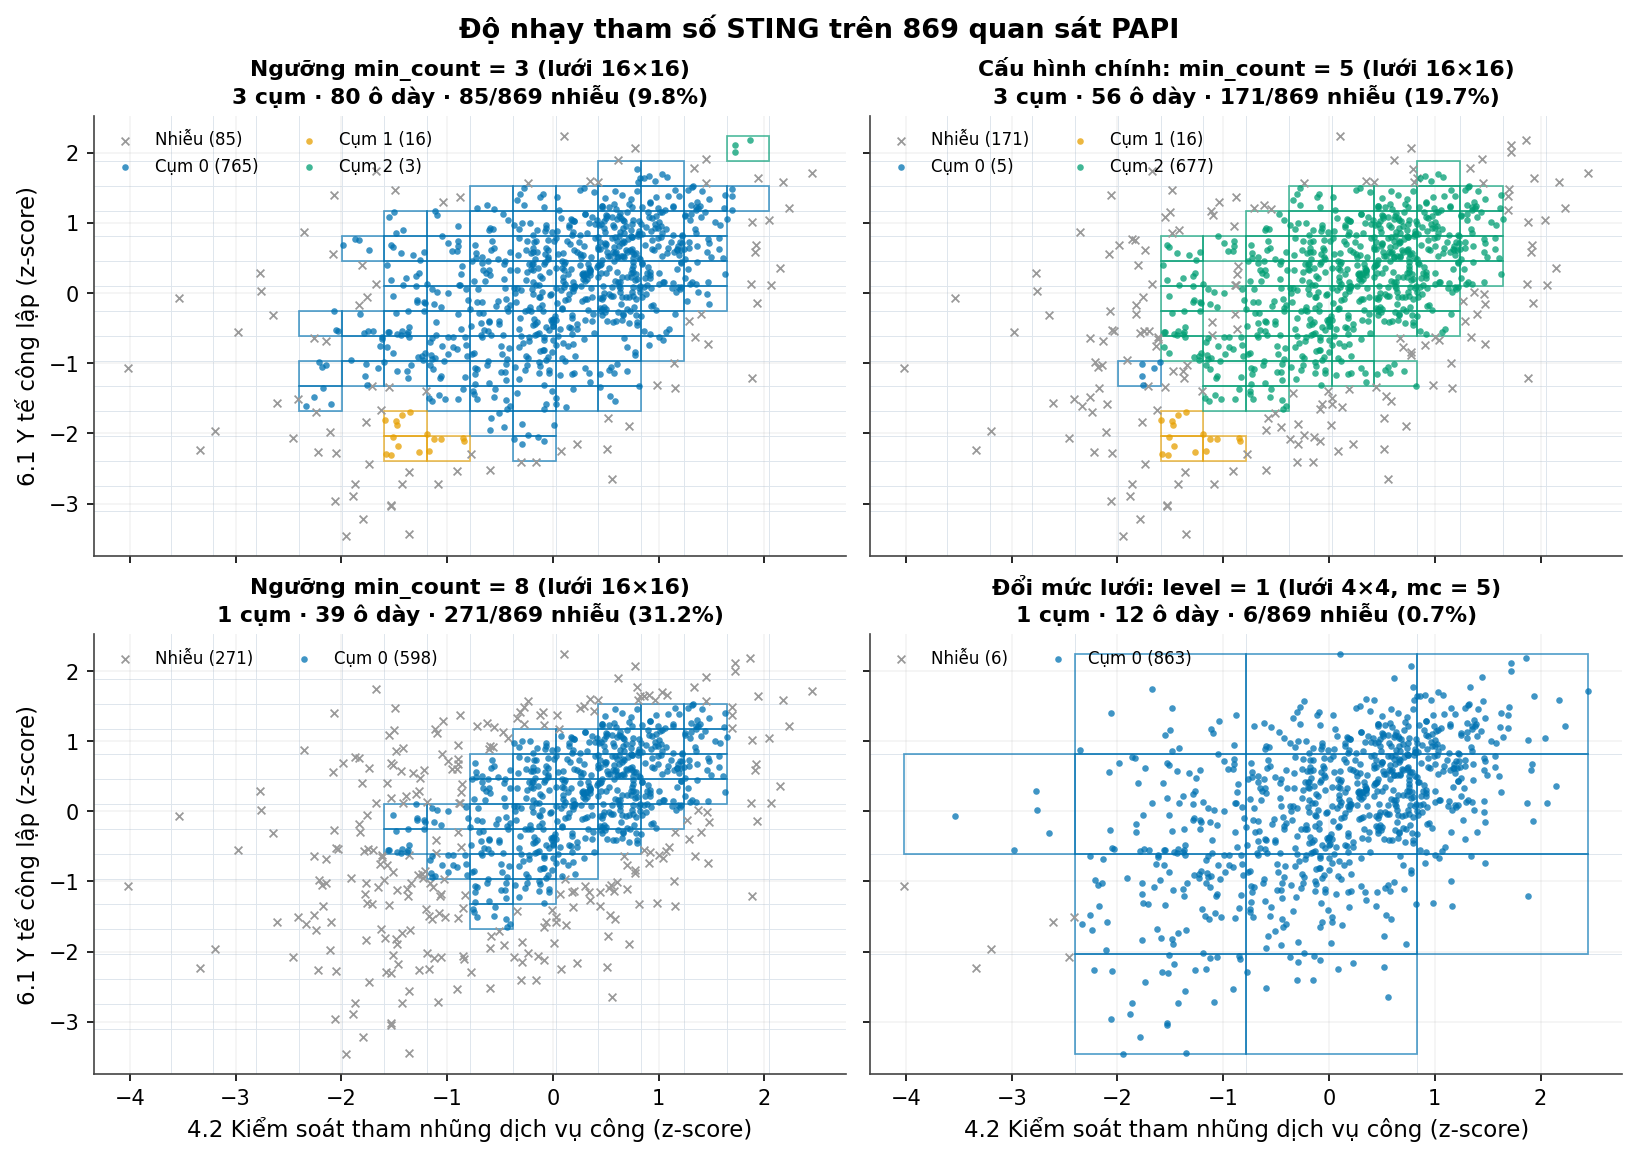

| scope            | method         |   k |   noise_ratio |   silhouette |   davies_bouldin |   calinski_harabasz |   ari_vs_sting | note                                             |
|:-----------------|:---------------|----:|--------------:|-------------:|-----------------:|--------------------:|---------------:|:-------------------------------------------------|
| pooled 2011-2023 | STING (frozen) |   3 |         0.196 |        0.361 |            0.472 |                62   |        nan     | k=3: [629,16,5]; noise tách khỏi metric hình học |
| pooled 2011-2023 | k-means k=2    |   2 |         0     |        0.445 |            0.876 |               812.3 |          0.166 | tất cả điểm được gán cụm                         |
| pooled 2011-2023 | k-means k=3    |   3 |         0     |        0.336 |            1.05  |               665.7 |          0.139 | tất cả điểm được gán cụm                         |
| pooled 2011-2023 | k-means k=4    |   4 |         0     |        0.364 |            0.879 |               669.1 |          0.082 | tất cả điểm được gán cụm                         |
| pooled 2011-2023 | k-means k=5    |   5 |         0     |        0.334 |            0.945 |               647.9 |          0.07  | tất cả điểm được gán cụm                         |
| pooled 2011-2023 | DBSCAN eps=0.2 |   5 |         0.142 |        0.218 |            0.505 |                35.3 |          0.647 | nan                                              |
| pooled 2011-2023 | DBSCAN eps=0.4 |   1 |         0.027 |      nan     |          nan     |               nan   |          0.135 | metric n/a khi <2 cụm                            |
| pooled 2011-2023 | DBSCAN eps=0.6 |   1 |         0.009 |      nan     |          nan     |               nan   |          0.043 | metric n/a khi <2 cụm                            |
| pooled 2011-2023 | DBSCAN eps=0.8 |   1 |         0.002 |      nan     |          nan     |               nan   |          0.012 | metric n/a khi <2 cụm                            |
| pooled 2011-2023 | DBSCAN eps=1.0 |   1 |         0.001 |      nan     |          nan     |               nan   |          0.006 | metric n/a khi <2 cụm                            |

In [11]:
for th in THRESHOLDS:
    t_m, t_l = fit_grid(Xz, min_count=th)
    t_n = int((t_l == -1).sum())
    print(f"Ngưỡng {th}  |  {t_m.n_clusters_} cụm  |  {t_n}/{len(t_l)} nhiễu ({t_n / len(t_l):.1%})")
lv_m = STING(n_levels=GRID["n_levels"], factor=GRID["factor"], min_count=GRID["min_count"]).fit(Xz)
for gl in range(lv_m.n_levels):
    gl_l = lv_m.cluster(level=gl, connectivity=GRID["connectivity"])
    w_g = lv_m.factor ** gl
    print(f"Lưới {w_g} × {w_g} | {len(lv_m.label_of_)} ô dày | {lv_m.n_clusters_} cụm | {int((gl_l == -1).sum())}/{len(gl_l)} nhiễu")
c8_l = lv_m.cluster(level=GRID["cluster_level"], connectivity=2)
print(f"Kề 8 hướng (connectivity=2) | {len(lv_m.label_of_)} ô dày | {lv_m.n_clusters_} cụm | {int((c8_l == -1).sum())}/{len(c8_l)} nhiễu")
flt_m, flt_l = fit_grid(Xz, significance_z=CELL_Z_EXAMPLE)
print(f"Thêm significance_z={CELL_Z_EXAMPLE:.1f}: {len(flt_m.label_of_)} ô đạt, {flt_m.n_clusters_} cụm, {int((flt_l == -1).sum())}/{len(lab)} điểm nhiễu.")
fig_sens = sensitivity_grid_figure(Xz)
plt.show()

# Đối chiếu trên 808 điểm huấn luyện (2011–2023)
metrics_csv = pd.read_csv(ROOT / "results/metrics.csv")
show_md(metrics_csv[metrics_csv.scope == "pooled 2011-2023"].to_markdown(index=False))

## Phần 4. STING theo từng năm (2011–2024) & Dịch chuyển trên lưới cố định

Phân cụm độc lập từng năm (`61–63` điểm/năm trên lưới `3 × 3`, `min_count = 3`) và theo dõi các tỉnh qua 14 năm cũng như chuyển dịch 2023 → 2024 trên cùng lưới cố định 2011–2023 (`808` quan sát).

|   year |   n |   k |   noise_ratio | cluster_sizes   |
|-------:|----:|----:|--------------:|:----------------|
|   2011 |  63 |   1 |         0.063 | [59]            |
|   2012 |  63 |   1 |         0     | [63]            |
|   2013 |  63 |   1 |         0.048 | [60]            |
|   2014 |  61 |   1 |         0.016 | [60]            |
|   2015 |  63 |   1 |         0.032 | [61]            |
|   2016 |  63 |   1 |         0.032 | [61]            |
|   2017 |  63 |   1 |         0.063 | [59]            |
|   2018 |  61 |   1 |         0.049 | [58]            |
|   2019 |  63 |   1 |         0.016 | [62]            |
|   2020 |  63 |   1 |         0.063 | [59]            |
|   2021 |  60 |   1 |         0.067 | [56]            |
|   2022 |  61 |   1 |         0.033 | [59]            |
|   2023 |  61 |   1 |         0     | [61]            |
|   2024 |  61 |   1 |         0.049 | [58]            |

14/14 năm có một cụm với lưới 3 × 3 và min_count=3.


,Số tỉnh
Kết quả gán 2024,
Thuộc cụm,48
Ô thưa,13
Thiếu chỉ tiêu,2


Đối chiếu 59 tỉnh ghép cặp 2023→2024: 7 tỉnh sang ô thưa, 5 tỉnh vào cụm.


Năm 2024,Nhiễu,Cụm lớn
Năm 2023,,
Nhiễu,4,5
Cụm lớn,7,43


Quỹ đạo Lạng Sơn 2023→2024 trên cùng lưới cố định: {2023: -1, 2024: 2}


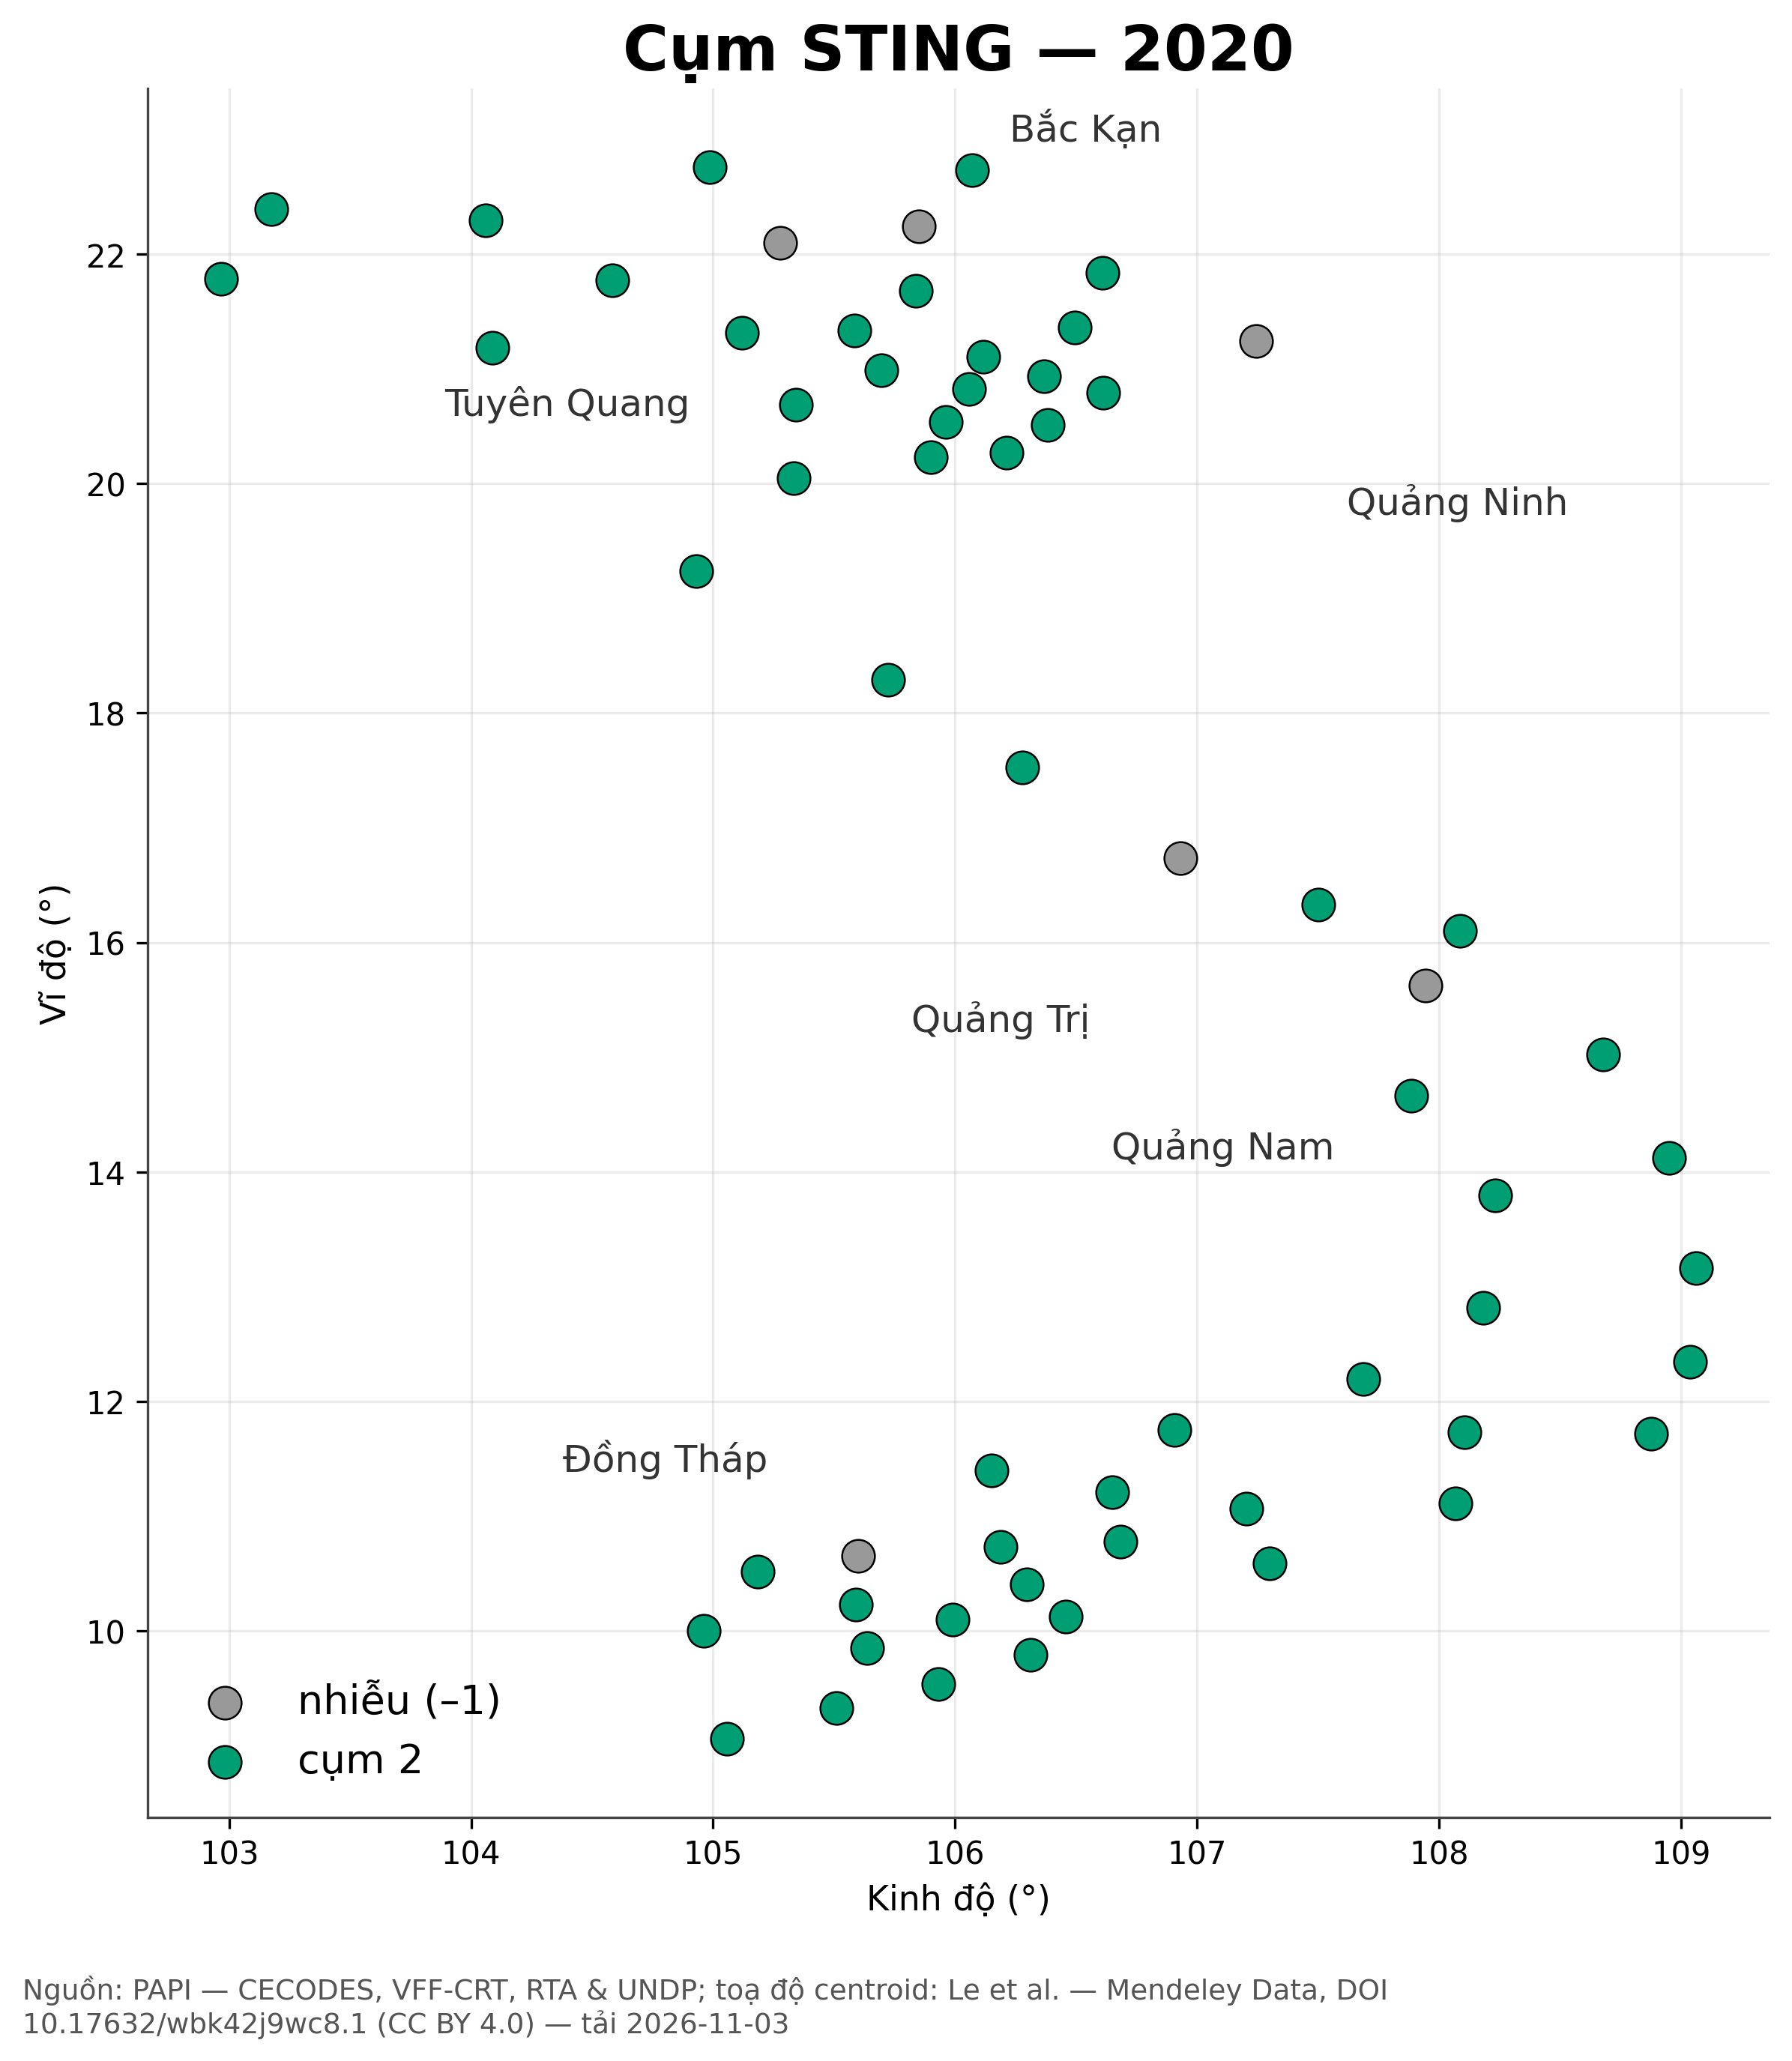

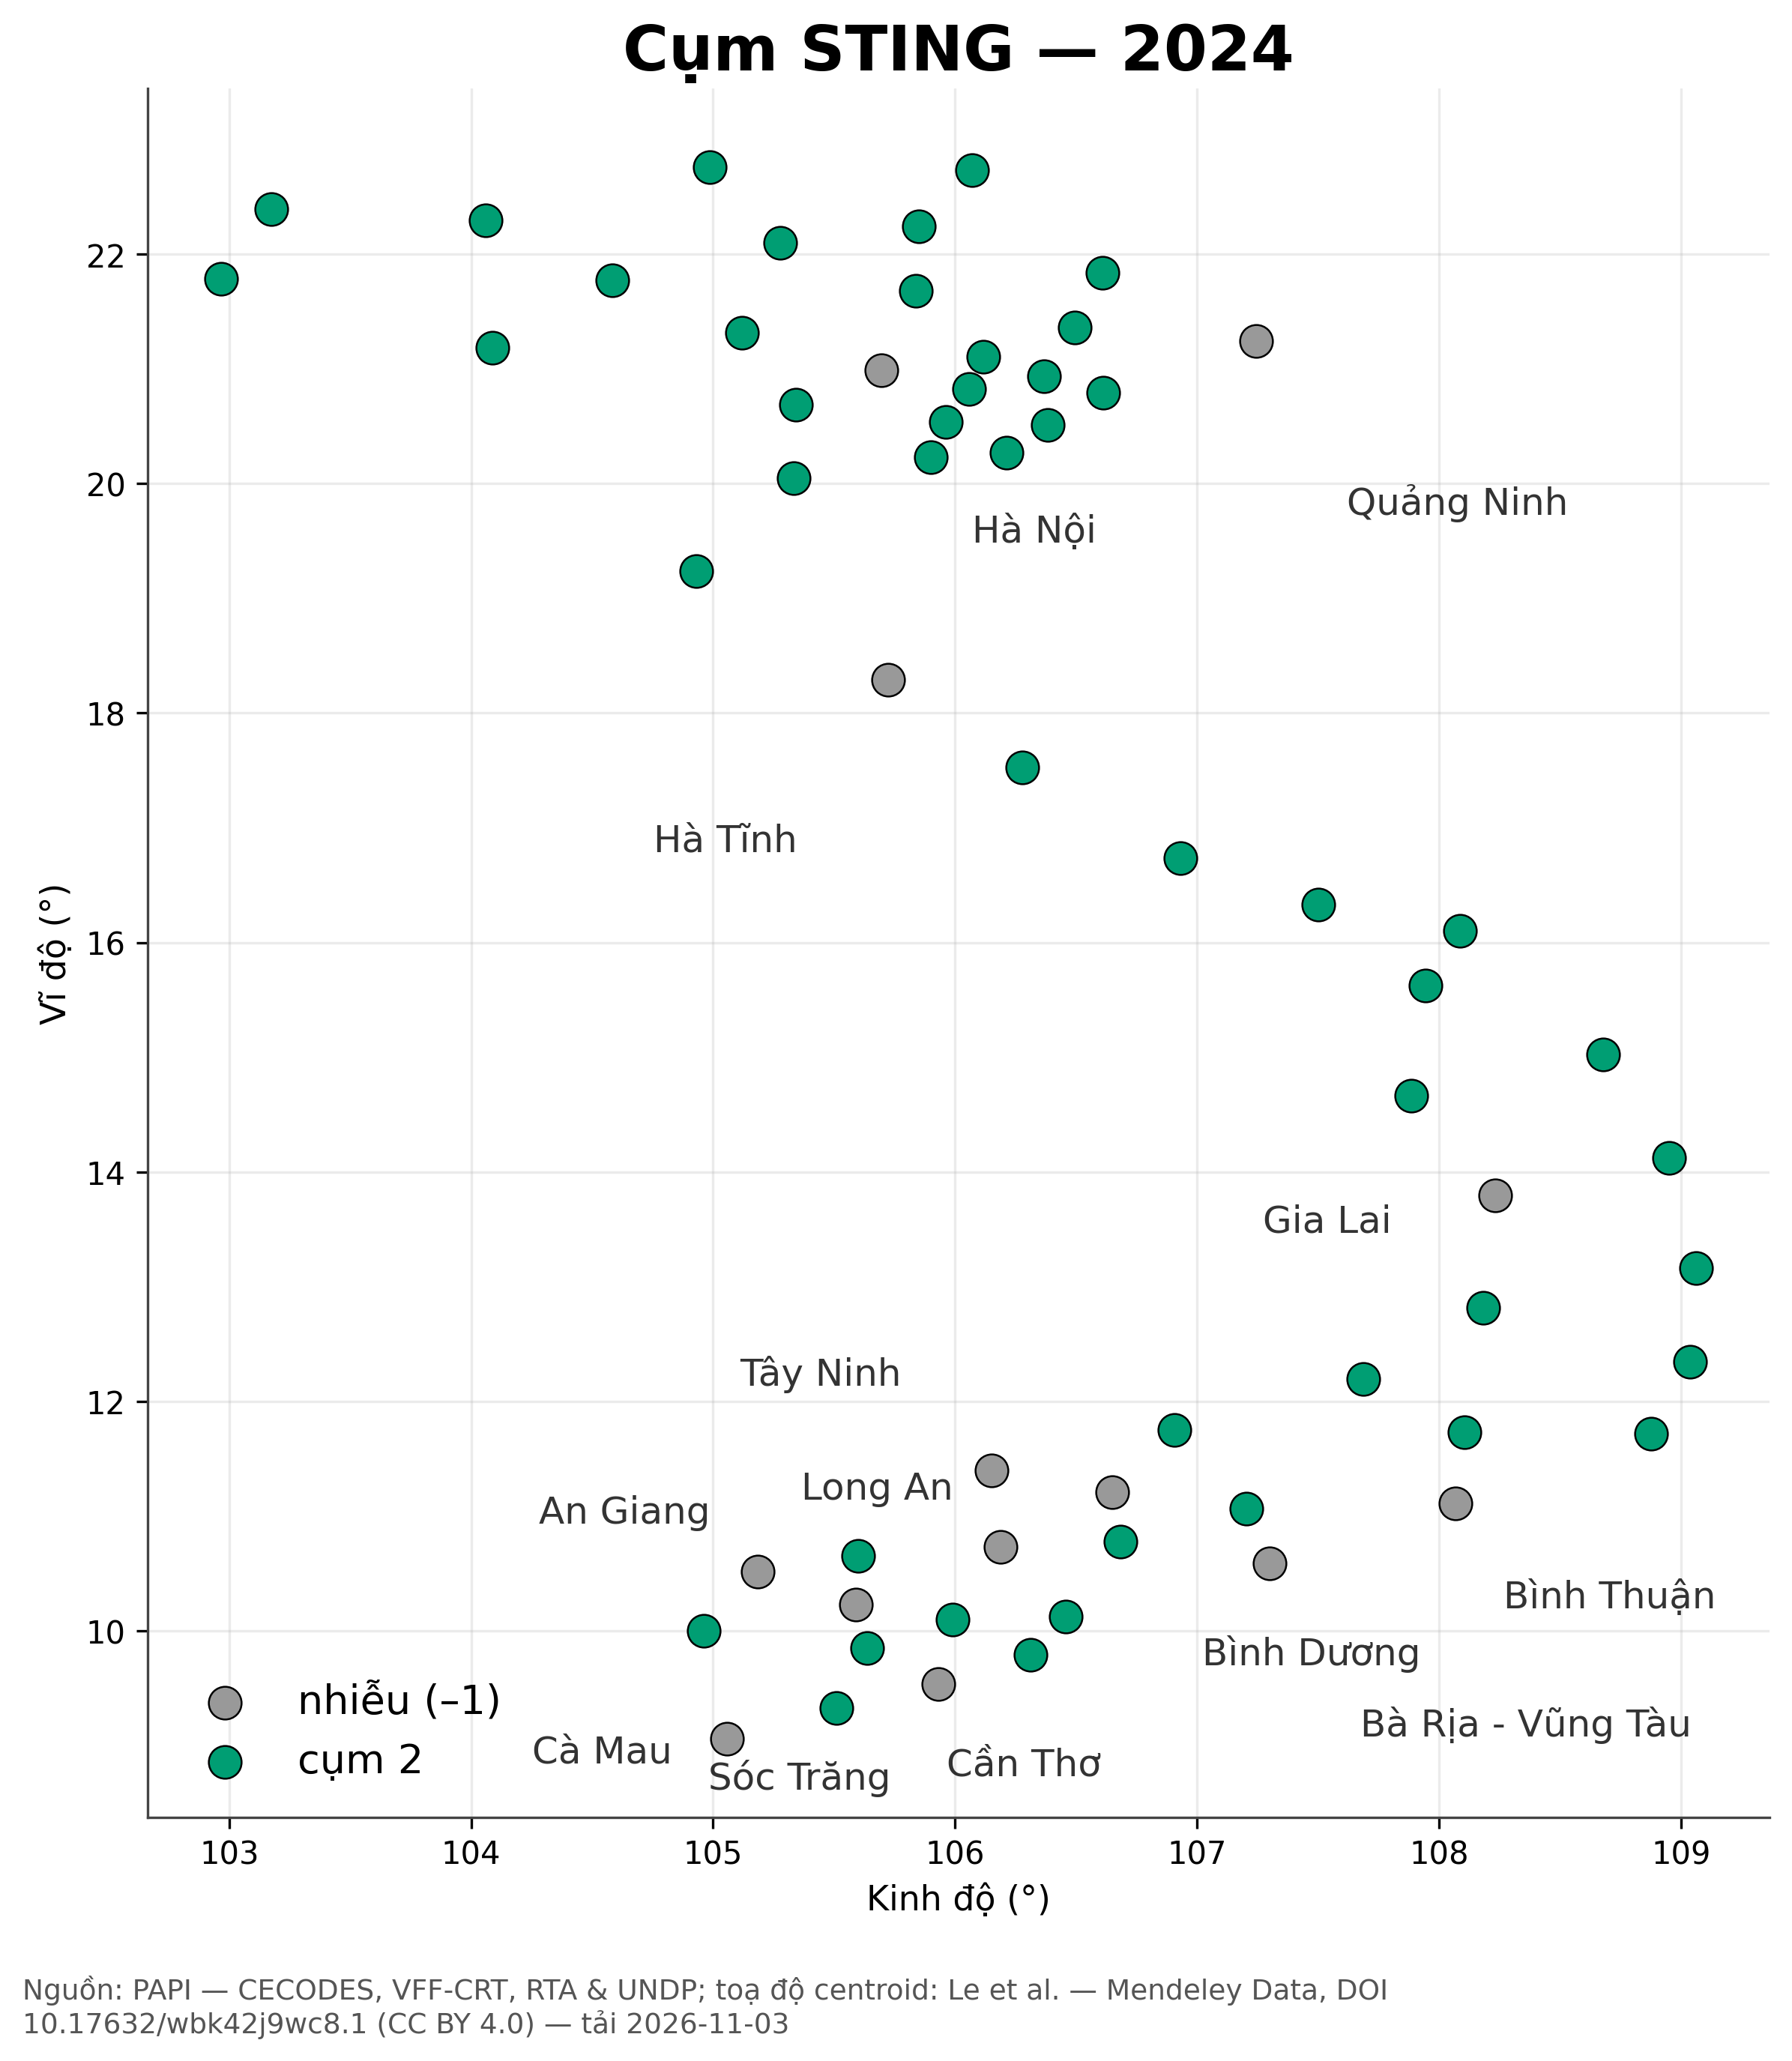

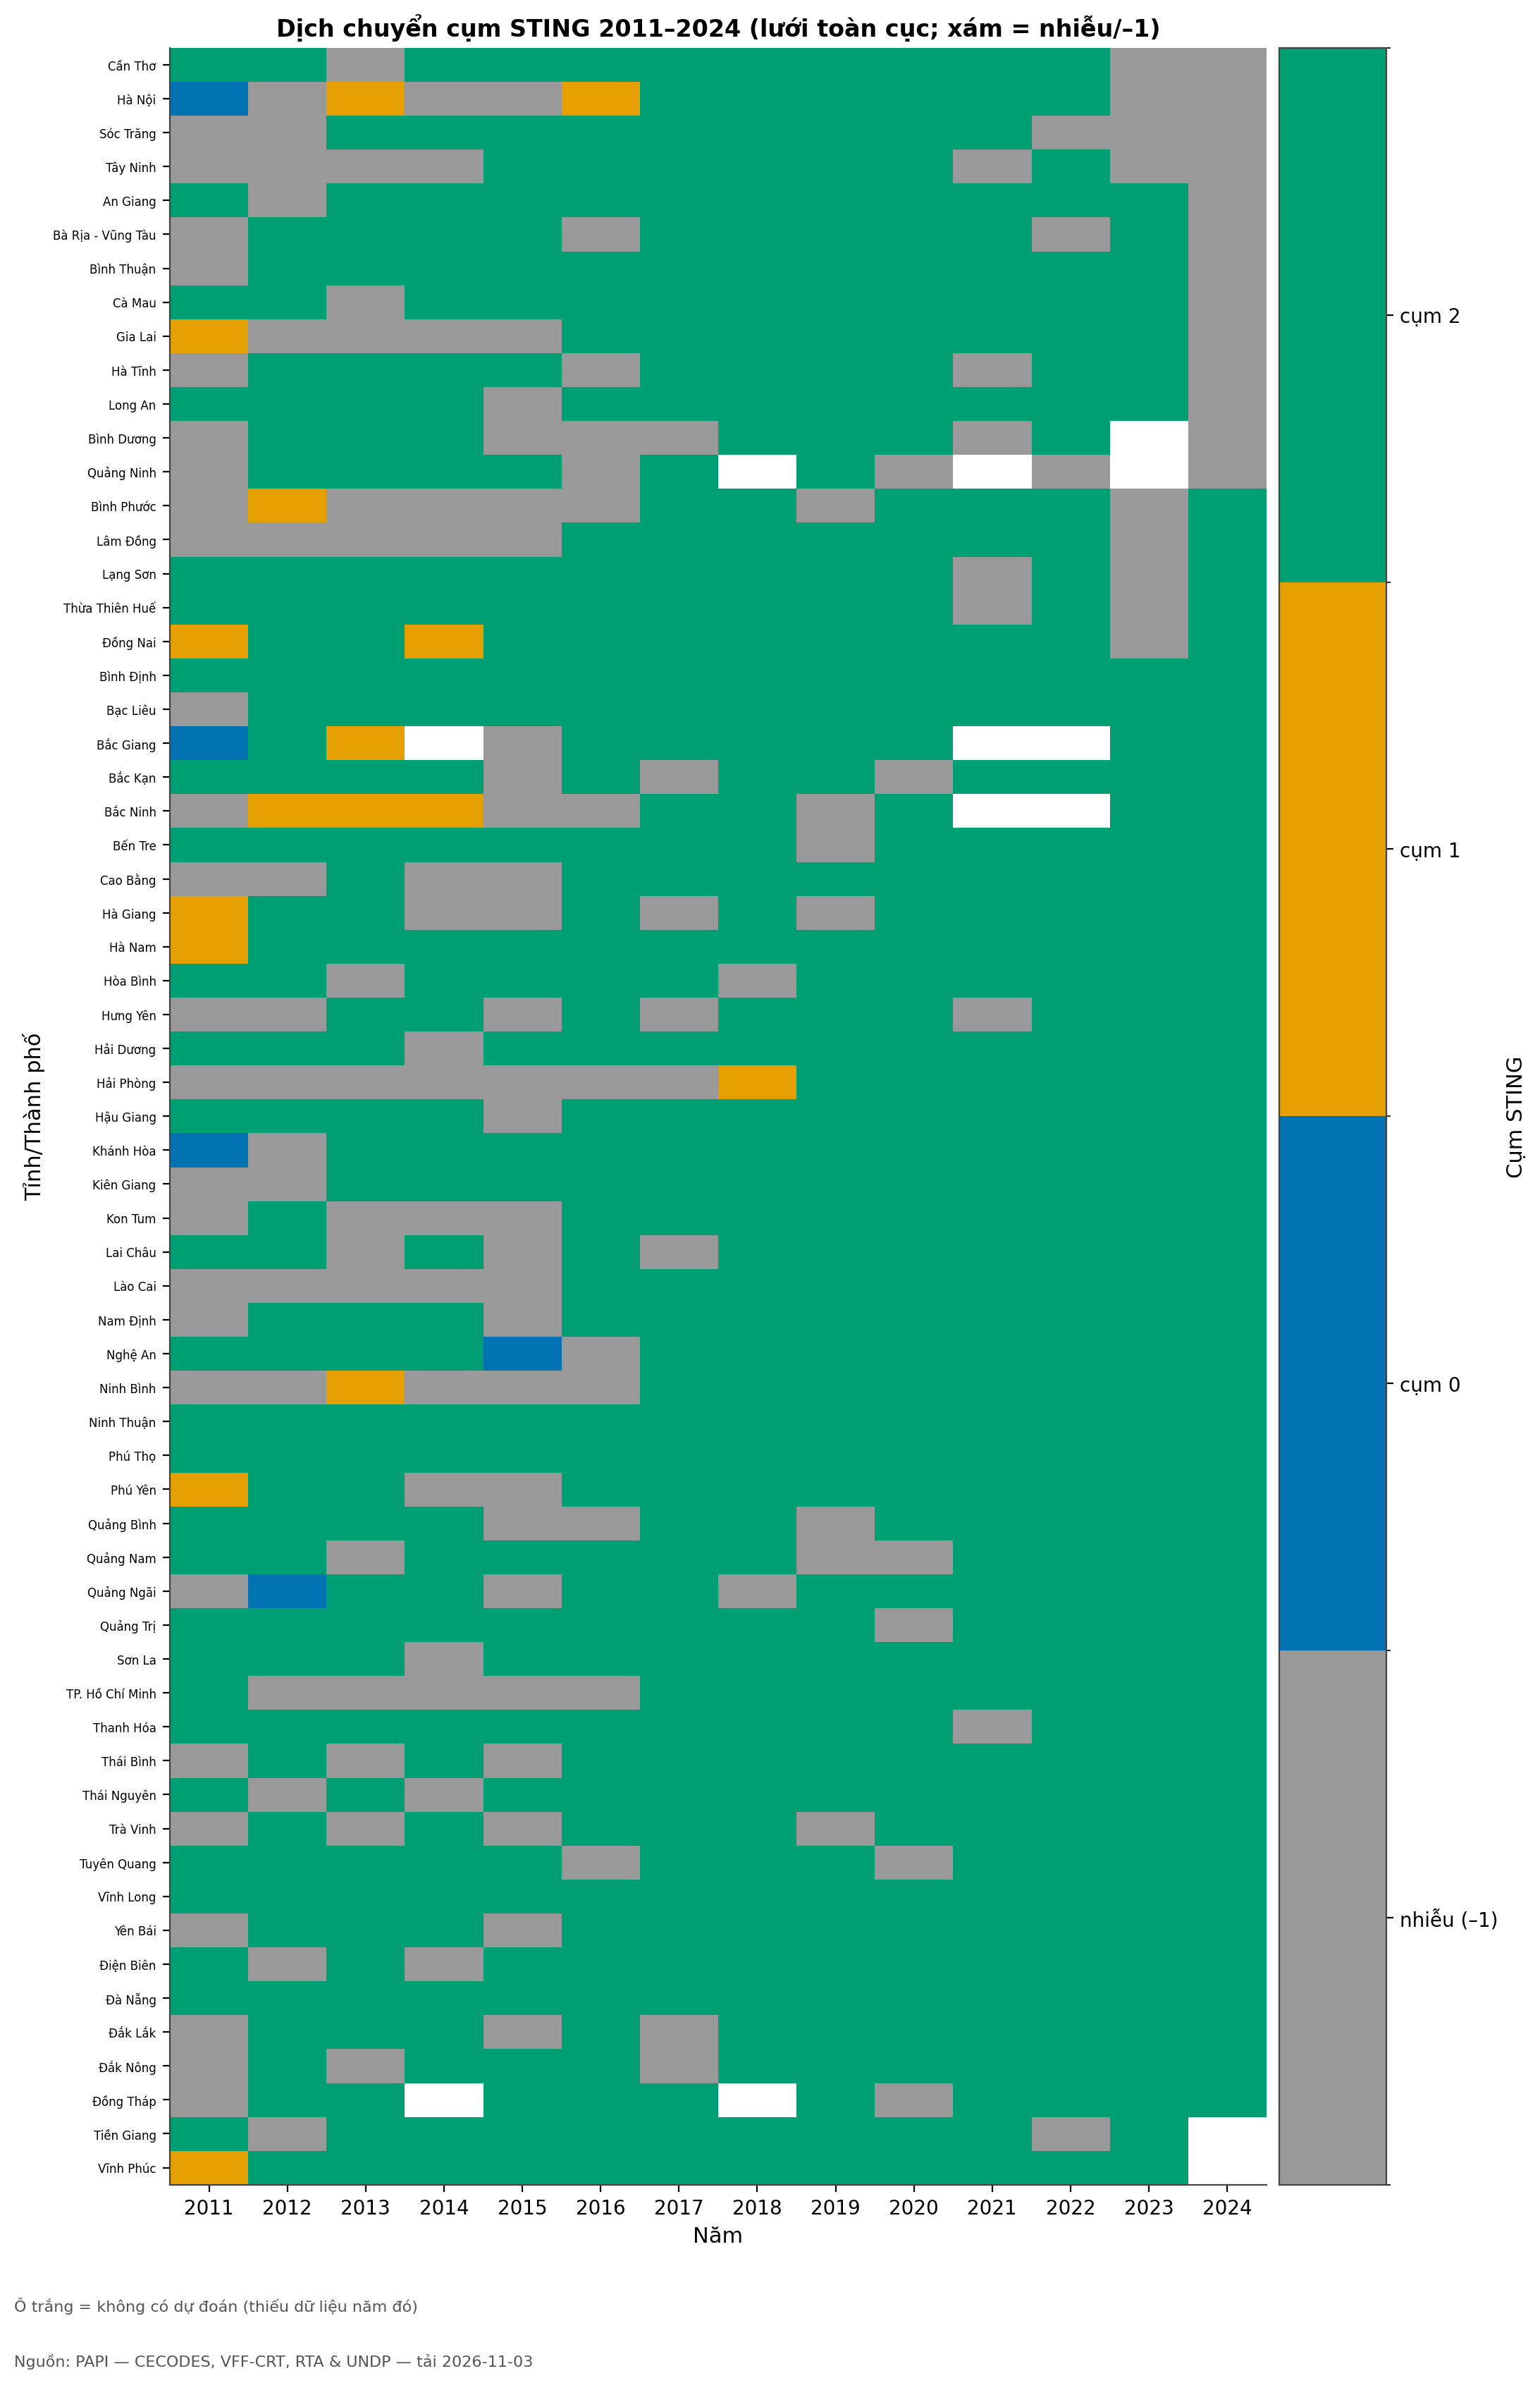

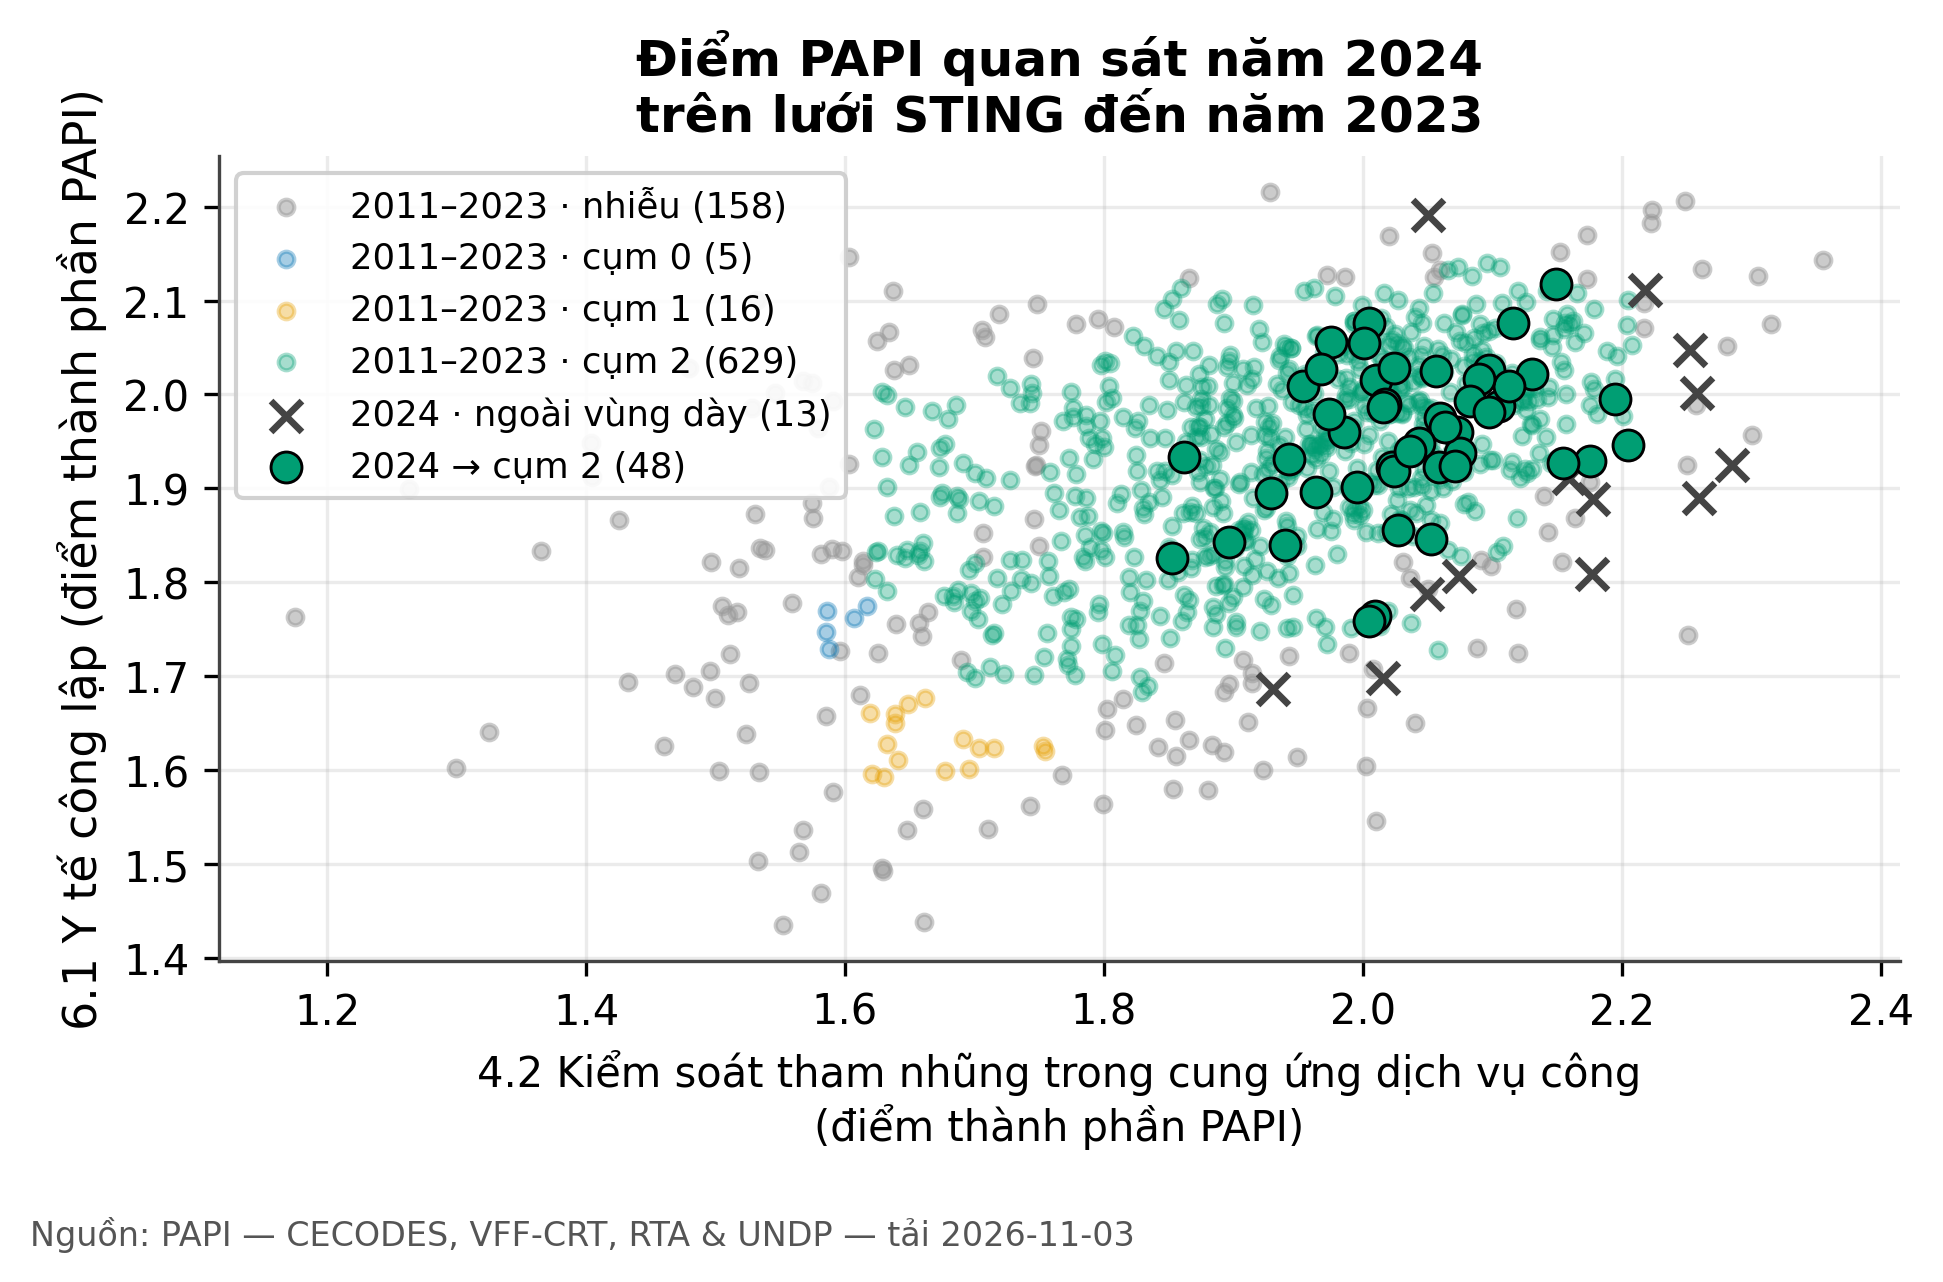

In [12]:
per_year = pd.read_csv(ROOT / "results/per_year.csv")
show_md(per_year.to_markdown(index=False))
single_cluster_years = int(per_year["k"].eq(1).sum())
print(f"{single_cluster_years}/{len(per_year)} năm có một cụm với lưới 3 × 3 và min_count=3.")

from scripts.common.papi_pred_common import GRID_ASSIGNMENT_LABELS, describe_grid_assignment

observed_grid = describe_grid_assignment(panel.loc[panel.year.eq(2024)], feats, scaler, sting)
status_counts = observed_grid.grid_status.value_counts().rename(index=GRID_ASSIGNMENT_LABELS)
display(status_counts.rename("Số tỉnh").rename_axis("Kết quả gán 2024").to_frame())

paired = (
    rebuilt[rebuilt.year.isin([2023, 2024])]
    .pivot(index="province_code", columns="year", values="pred_cluster")
    .dropna()
    .astype(int)
)
transition = pd.crosstab(paired[2023], paired[2024], rownames=["Năm 2023"], colnames=["Năm 2024"])
transition = transition.rename(index={2: "Cụm lớn", -1: "Nhiễu"}, columns={2: "Cụm lớn", -1: "Nhiễu"})
print(f"Đối chiếu {len(paired)} tỉnh ghép cặp 2023→2024: {transition.loc['Cụm lớn', 'Nhiễu']} tỉnh sang ô thưa, {transition.loc['Nhiễu', 'Cụm lớn']} tỉnh vào cụm.")
display(transition)

lang_son_code = panel.loc[panel.province_vi.eq("Lạng Sơn"), "province_code"].iat[0]
print("Quỹ đạo Lạng Sơn 2023→2024 trên cùng lưới cố định:", paired.loc[lang_son_code].to_dict())

for fig_name in ("map_2020.png", "map_2024.png", "evolution.png", "predict_2024.png"):
    display(Image(filename=str(ROOT / "results/figs" / fig_name)))

## Phần 5. Thống kê bàn giao cho khách hàng trên 63 tỉnh năm 2024

Trả lời trực tiếp yêu cầu thực tiễn từ phía giảng viên và khách hàng sử dụng báo cáo: **sau khi chạy phân cụm ra các nhãn kỹ thuật (`-1, 0, 1, 2`) và ô lưới `(i, j)`, nhóm thống kê và bàn giao những giá trị gì cụ thể cho cơ quan quản lý địa phương?**

1. **Mô tả 63 tỉnh bằng bốn nhóm:** 48 tỉnh trong vùng dày, 8 tỉnh ngoài vùng dày về phía điểm cao, 5 tỉnh ngoài vùng dày có điểm `6.1` thấp và 2 tỉnh thiếu dữ liệu. Ngưỡng `6.1 = Q25 − 0,5 × IQR = 1,8791` tính từ 48 tỉnh trong Cụm 2 năm 2024, nên là quy tắc mô tả hồi cứu, không phải chuẩn chất lượng hay bốn cụm học được.
2. **Theo dõi việc giữ nhãn:** 5 tỉnh thuộc Cụm 2 ở cả 14 năm (`Phú Thọ, Đà Nẵng, Bình Định, Ninh Thuận, Vĩnh Long`) trên cùng lưới tham chiếu. Giữ nhãn không chứng minh chất lượng dịch vụ ổn định. Có 7 tỉnh trong Cụm 2 cũng thấp hơn ngưỡng `6.1` trên.
3. **Mô tả dịch chuyển 2023 → 2024:** trong 59 tỉnh đủ dữ liệu cả hai năm, 7 tỉnh rời vùng dày và 5 tỉnh đi vào. Trong 7 tỉnh rời vùng dày, 5 thuộc phía điểm cao và 2 có `6.1` thấp theo quy tắc 2024; nhãn không xác định nguyên nhân thay đổi.
4. **Kịch bản ngoài vùng năm 2024** (`outside_scenario_share`) là chỉ số xếp hạng hồi kiểm 2023→2024, chưa phải xác suất hiệu chỉnh hoặc bằng chứng dự báo tiền cứu. Chênh lệch GRDP/người và điểm `6.1` chỉ mang tính mô tả.

Các khóa nhóm cũ được giữ trong CSV để tương thích mã nguồn; bảng hiển thị dưới đây dùng tên mô tả thống nhất với Word và slide.

Tổng hợp 63 tỉnh năm 2024 | Trung vị Cụm 2: 4.2 = 2.0317, 6.1 = 1.9629 | Ngưỡng tách dưới 6.1 = 1.8791.


| action_group                  |   n_provinces |   share_63_pct |   median_sd_4_2 |   median_sd_6_1 |   median_years_c2 |   median_risk_outside_pct |   median_grdp_2024_mil |   median_pci_2022 |
|:------------------------------|--------------:|---------------:|----------------:|----------------:|------------------:|--------------------------:|-----------------------:|------------------:|
| Ngoài vùng dày, phía điểm cao |             8 |           12.7 |          2.2353 |          1.9631 |              10   |                      39.8 |                  87.38 |             64.78 |
| Trong vùng dày (Cụm 2)        |            48 |           76.2 |          2.0317 |          1.9629 |              11.5 |                      18.5 |                  80.97 |             65.25 |
| Ngoài vùng dày, điểm 6.1 thấp |             5 |            7.9 |          2.0496 |          1.7875 |               8   |                      31.3 |                 104.26 |             66.74 |
| Thiếu dữ liệu 2024            |             2 |            3.2 |        nan      |        nan      |              11.5 |                      22.3 |                 108.94 |             66.04 |

5 tỉnh giữ nhãn Cụm 2 ở 14/14 năm: Phú Thọ, Đà Nẵng, Bình Định, Ninh Thuận, Vĩnh Long


,province_vi,action_group,sd_4_2,sd_6_1,grid_cell,grdp_2024_mil_vnd
0,Cà Mau,"Ngoài vùng dày, phía điểm cao",2.1781,1.8881,"(13, 9)",71.36
1,Quảng Ninh,"Ngoài vùng dày, phía điểm cao",2.2598,1.8891,"(14, 9)",234.10
2,An Giang,"Ngoài vùng dày, phía điểm cao",2.1593,1.9106,"(13, 9)",65.98
3,Tây Ninh,"Ngoài vùng dày, phía điểm cao",2.2852,1.9245,"(15, 10)",103.56
4,Bà Rịa - Vũng Tàu,"Ngoài vùng dày, phía điểm cao",2.2581,2.0017,"(14, 11)",338.97
5,Sóc Trăng,"Ngoài vùng dày, phía điểm cao",2.2524,2.0477,"(14, 12)",65.58
6,Bình Thuận,"Ngoài vùng dày, phía điểm cao",2.2182,2.1117,"(14, 13)",91.96
7,Hà Tĩnh,"Ngoài vùng dày, phía điểm cao",2.0502,2.1914,"(11, 15)",82.81
8,Hà Nội,"Ngoài vùng dày, điểm 6.1 thấp",1.9308,1.6863,"(10, 5)",162.92
9,Cần Thơ,"Ngoài vùng dày, điểm 6.1 thấp",2.0157,1.6979,"(11, 5)",104.26


| transition_2023_2024        |   n_provinces |
|:----------------------------|--------------:|
| Giữ nhãn Cụm 2              |            43 |
| Vào Cụm 2 từ ngoài lõi      |             5 |
| Rời vùng dày, phía điểm cao |             5 |
| Duy trì ngoài lõi (−1)      |             4 |
| Thiếu dữ liệu 2023          |             2 |
| Rời vùng dày, điểm 6.1 thấp |             2 |
| Thiếu dữ liệu 2024          |             2 |

|   province_code | province_vi    | action_group                  |   sd_4_2 |   sd_6_1 |   risk_outside_scenario_share |
|----------------:|:---------------|:------------------------------|---------:|---------:|------------------------------:|
|              94 | Sóc Trăng      | Ngoài vùng dày, phía điểm cao |   2.2524 |   2.0477 |                        0.7143 |
|              72 | Tây Ninh       | Ngoài vùng dày, phía điểm cao |   2.2852 |   1.9245 |                        0.6044 |
|              95 | Bạc Liêu       | Trong vùng dày (Cụm 2)        |   2.1546 |   1.927  |                        0.4753 |
|              46 | Thừa Thiên Huế | Trong vùng dày (Cụm 2)        |   2.1495 |   2.1177 |                        0.4615 |
|              75 | Đồng Nai       | Trong vùng dày (Cụm 2)        |   2.0094 |   1.7638 |                        0.4258 |
|              96 | Cà Mau         | Ngoài vùng dày, phía điểm cao |   2.1781 |   1.8881 |                        0.4258 |
|               1 | Hà Nội         | Ngoài vùng dày, điểm 6.1 thấp |   1.9308 |   1.6863 |                        0.4066 |
|              89 | An Giang       | Ngoài vùng dày, phía điểm cao |   2.1593 |   1.9106 |                        0.3984 |
|              87 | Đồng Tháp      | Trong vùng dày (Cụm 2)        |   2.0364 |   1.9401 |                        0.3874 |
|              42 | Hà Tĩnh        | Ngoài vùng dày, phía điểm cao |   2.0502 |   2.1914 |                        0.3764 |

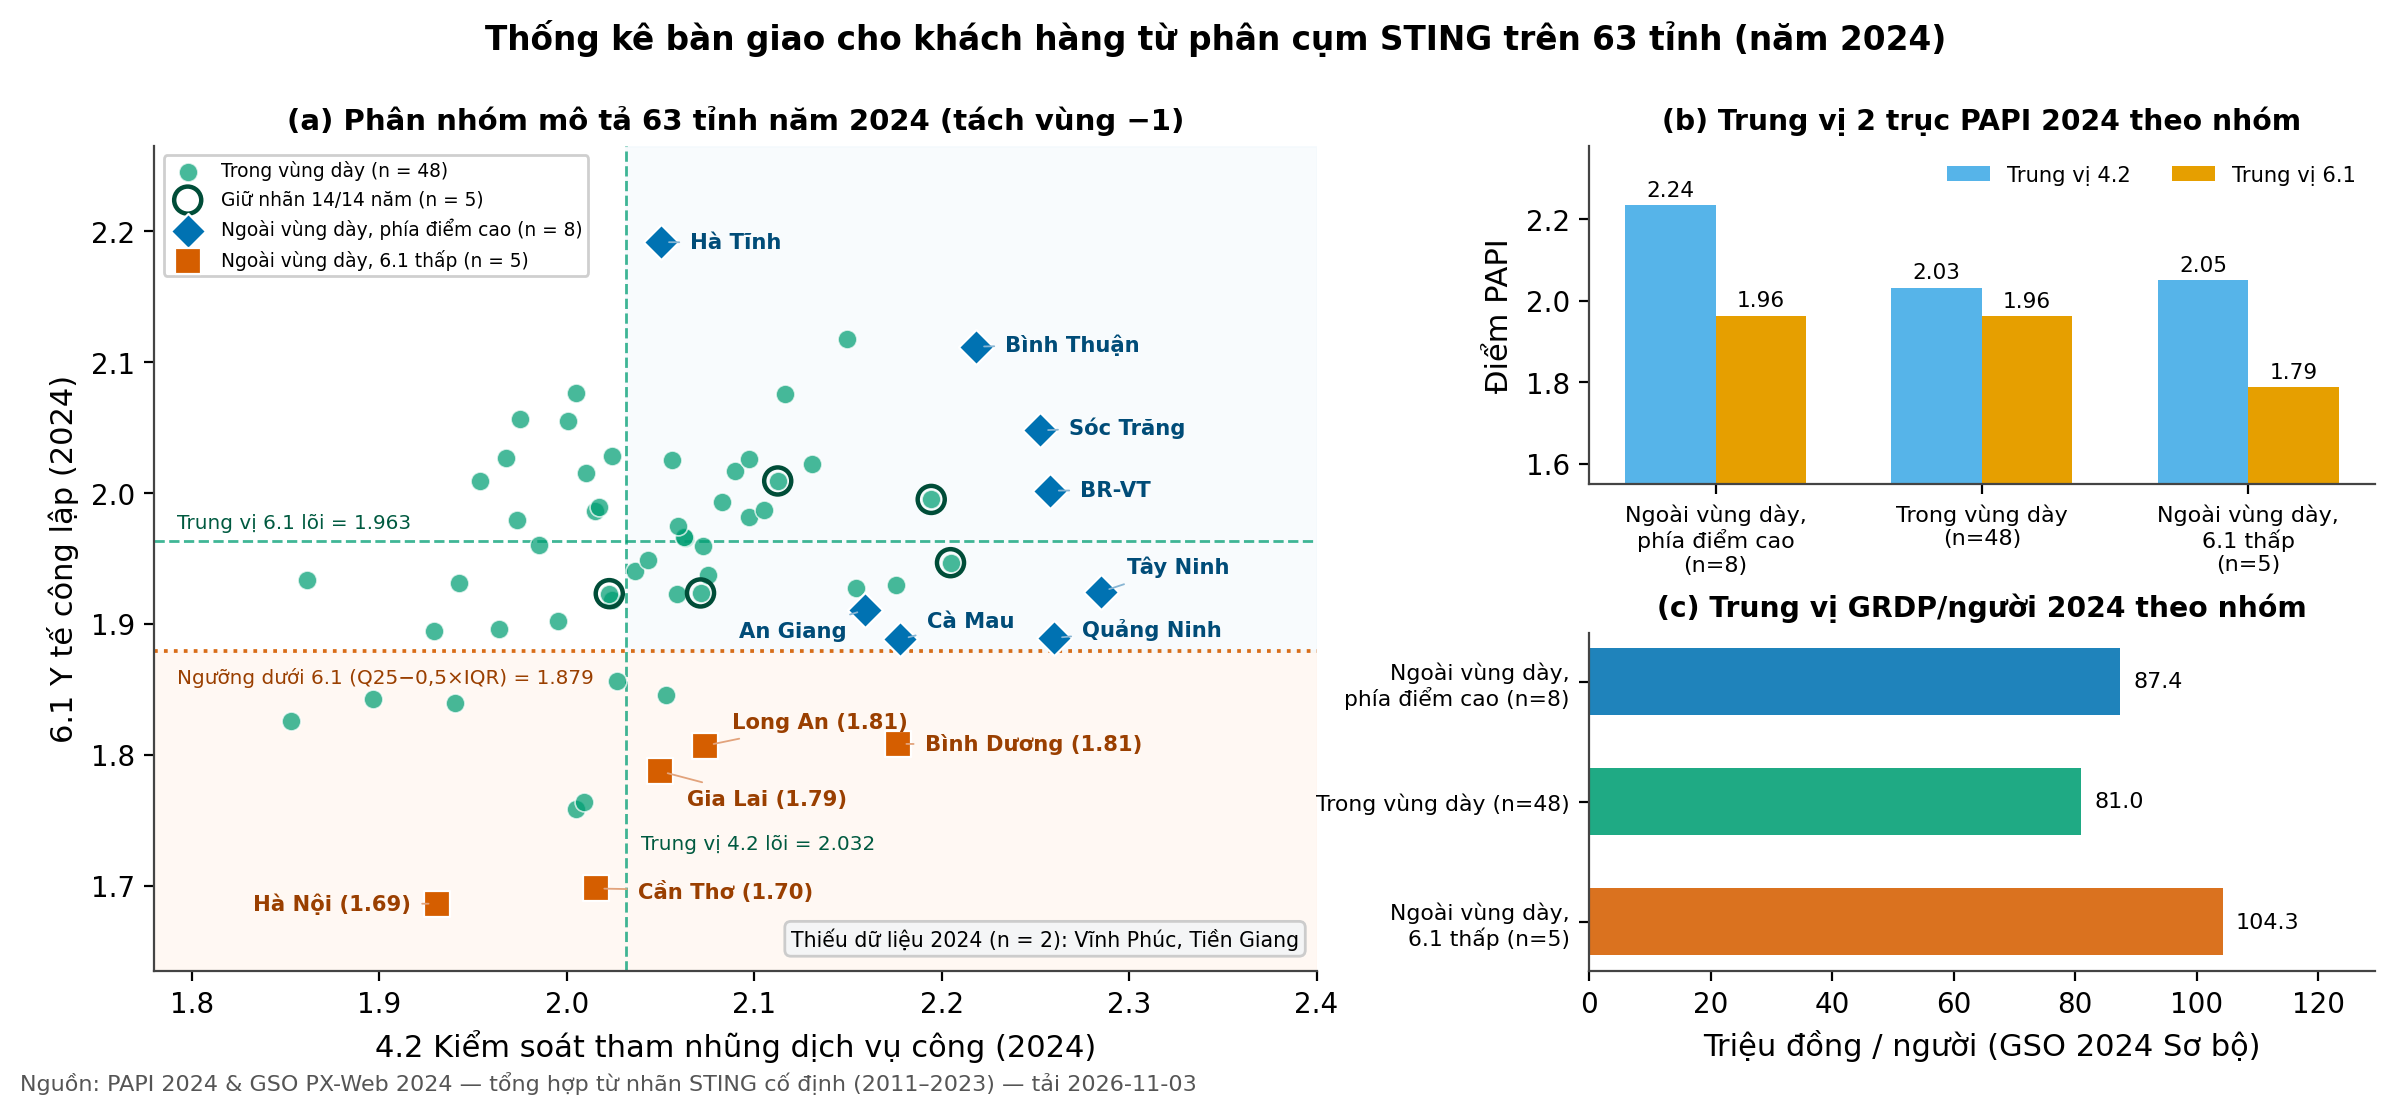

In [13]:
from scripts.analysis.stakeholder_summary import build_stakeholder_tables

stake = build_stakeholder_tables(ROOT)
s_df = stake["summary"]
g_df = stake["group_stats"]
bench = stake["bench"]
transitions_df = stake["transitions"]
benchmarks_14y = stake["benchmarks_14y"]
watchlist_df = stake["watchlist"]

DISPLAY_LABELS = {
    "Vùng lõi ổn định (Cụm 2)": "Trong vùng dày (Cụm 2)",
    "Biên bứt phá vượt chuẩn": "Ngoài vùng dày, phía điểm cao",
    "Ưu tiên cải thiện Y tế 6.1": "Ngoài vùng dày, điểm 6.1 thấp",
    "Giữ vững Cụm 2": "Giữ nhãn Cụm 2",
    "Rời Cụm 2 lên biên bứt phá": "Rời vùng dày, phía điểm cao",
    "Rời Cụm 2 xuống rìa Y tế 6.1": "Rời vùng dày, điểm 6.1 thấp",
}


def descriptive_table(frame):
    view = frame.copy()
    for column in ("action_group", "transition_2023_2024"):
        if column in view:
            view[column] = view[column].replace(DISPLAY_LABELS)
    return view


print(
    f"Tổng hợp 63 tỉnh năm 2024 | Trung vị Cụm 2: 4.2 = {bench['med_42']:.4f}, "
    f"6.1 = {bench['med_61']:.4f} | Ngưỡng tách dưới 6.1 = {bench['lower_61_fence']:.4f}."
)
show_md(descriptive_table(g_df[[
    "action_group", "n_provinces", "share_63_pct", "median_sd_4_2", "median_sd_6_1",
    "median_years_c2", "median_risk_outside_pct", "median_grdp_2024_mil", "median_pci_2022",
]]).to_markdown(index=False))

print("5 tỉnh giữ nhãn Cụm 2 ở 14/14 năm:", ", ".join(benchmarks_14y["province_vi"].tolist()))
display(descriptive_table(s_df.loc[
    s_df["action_group"].isin(["Biên bứt phá vượt chuẩn", "Ưu tiên cải thiện Y tế 6.1", "Thiếu dữ liệu 2024"]),
    ["province_vi", "action_group", "sd_4_2", "sd_6_1", "grid_cell", "grdp_2024_mil_vnd"],
]).round(4).reset_index(drop=True))
show_md(descriptive_table(transitions_df).to_markdown(index=False))
show_md(descriptive_table(watchlist_df).round(4).to_markdown(index=False))
display(Image(filename=str(ROOT / "results/figs/stakeholder_quadrants_2024.png")))

## Phần 6. Thí nghiệm dự báo 2024 (thăm dò) & Đối chiếu nguồn ngoài PAPI

### 6.1 Dự báo hai chỉ tiêu 2024 bằng Ridge & xếp hạng kịch bản rời vùng dày

- Ridge giảm MAE nhẹ hơn giữ nguyên điểm 2023 trên 59 tỉnh (`4.2`: `0,0736` vs `0,0763`; `6.1`: `0,0641` vs `0,0683`), nhưng RMSE của `4.2` cao hơn (`0,0972` vs `0,0953`). Tất cả dự báo điểm vào vùng dày, nên chỉ nhận ra **`0/11` tỉnh ngoài vùng dày** trong mẫu đối chiếu.
- Nhóm ghép `364` cặp phần dư CV lịch sử vào dự báo điểm để đo tỉ lệ kịch bản rời vùng (`outside_scenario_share`). `AUC = 0,816` là kết quả hồi cứu thăm dò, chưa phải xác suất hiệu chỉnh hay kiểm chứng tiền cứu; không dùng năm 2024 để chọn cấu hình trong mã nguồn không chứng minh rằng năm này chưa từng được xem trong quá trình làm đồ án.

,target,method,n,mae,rmse,bias
0,sd_4_2,forecast,59,0.0736,0.0972,-0.0581
1,sd_4_2,carry,59,0.0763,0.0953,-0.0245
2,sd_6_1,forecast,59,0.0641,0.0770,-0.0308
3,sd_6_1,carry,59,0.0683,0.0875,-0.0333


,method,n,out_correct,missed_out,exact_label_agreement,out_recall,balanced_zone_accuracy
0,forecast,59,0,11,0.8136,0.0000,0.5000
1,carry,59,4,7,0.7966,0.3636,0.6297
2,majority,59,0,11,0.8136,0.0000,0.5000


Kịch bản sai số lịch sử (364 kịch bản/tỉnh): AUC = 0.8163.


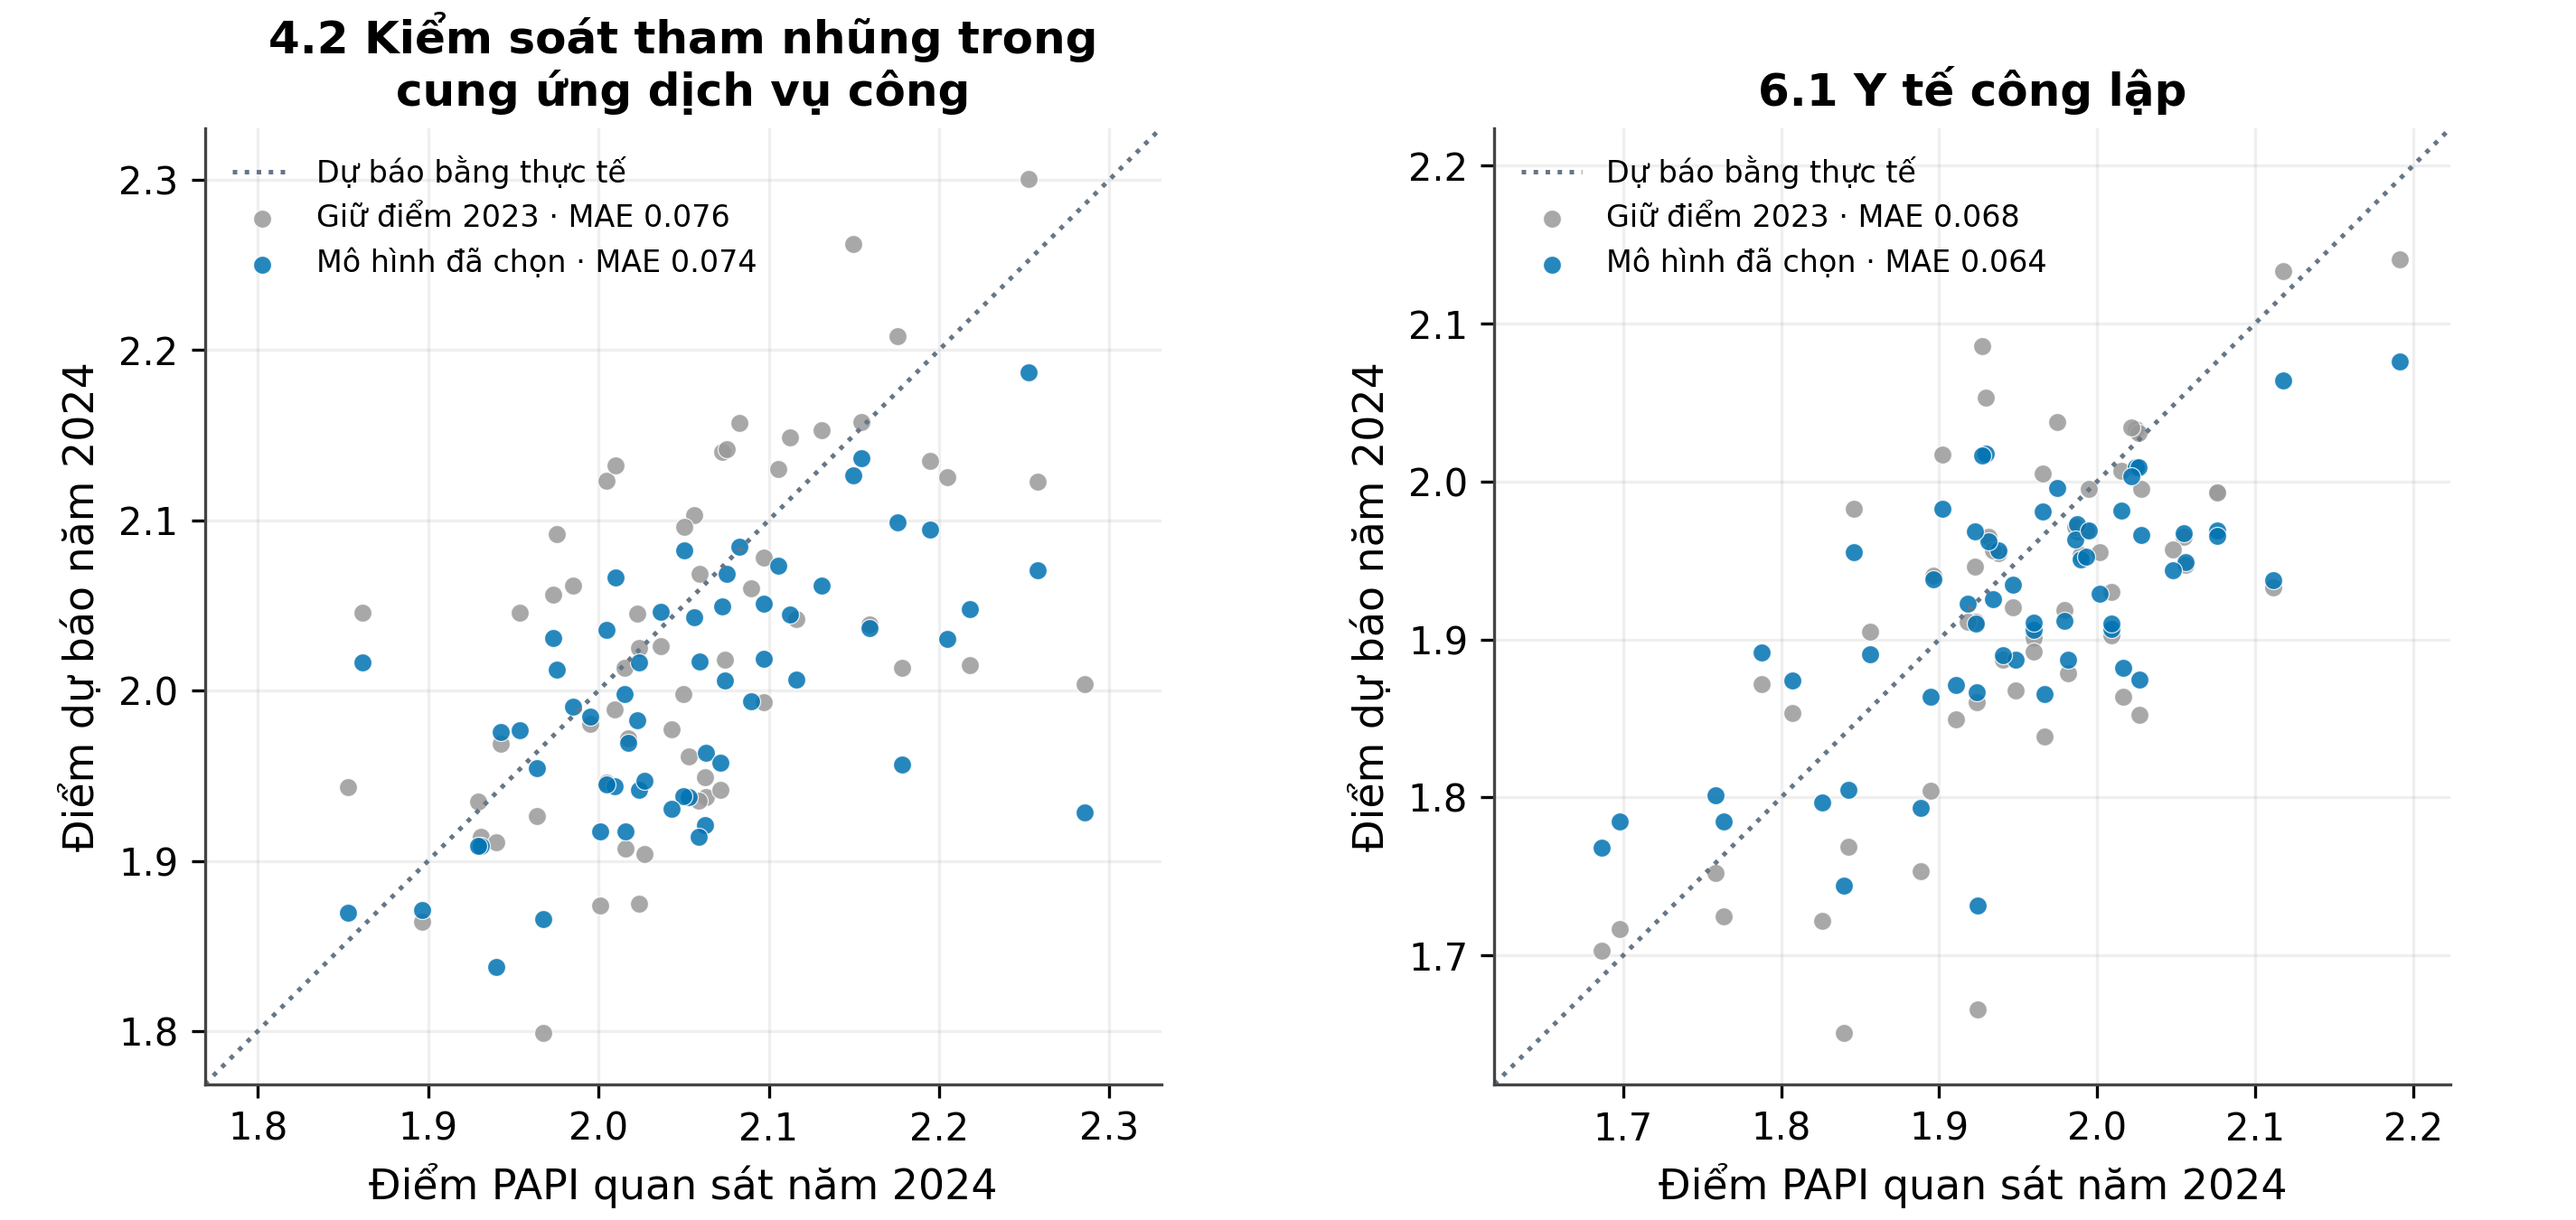

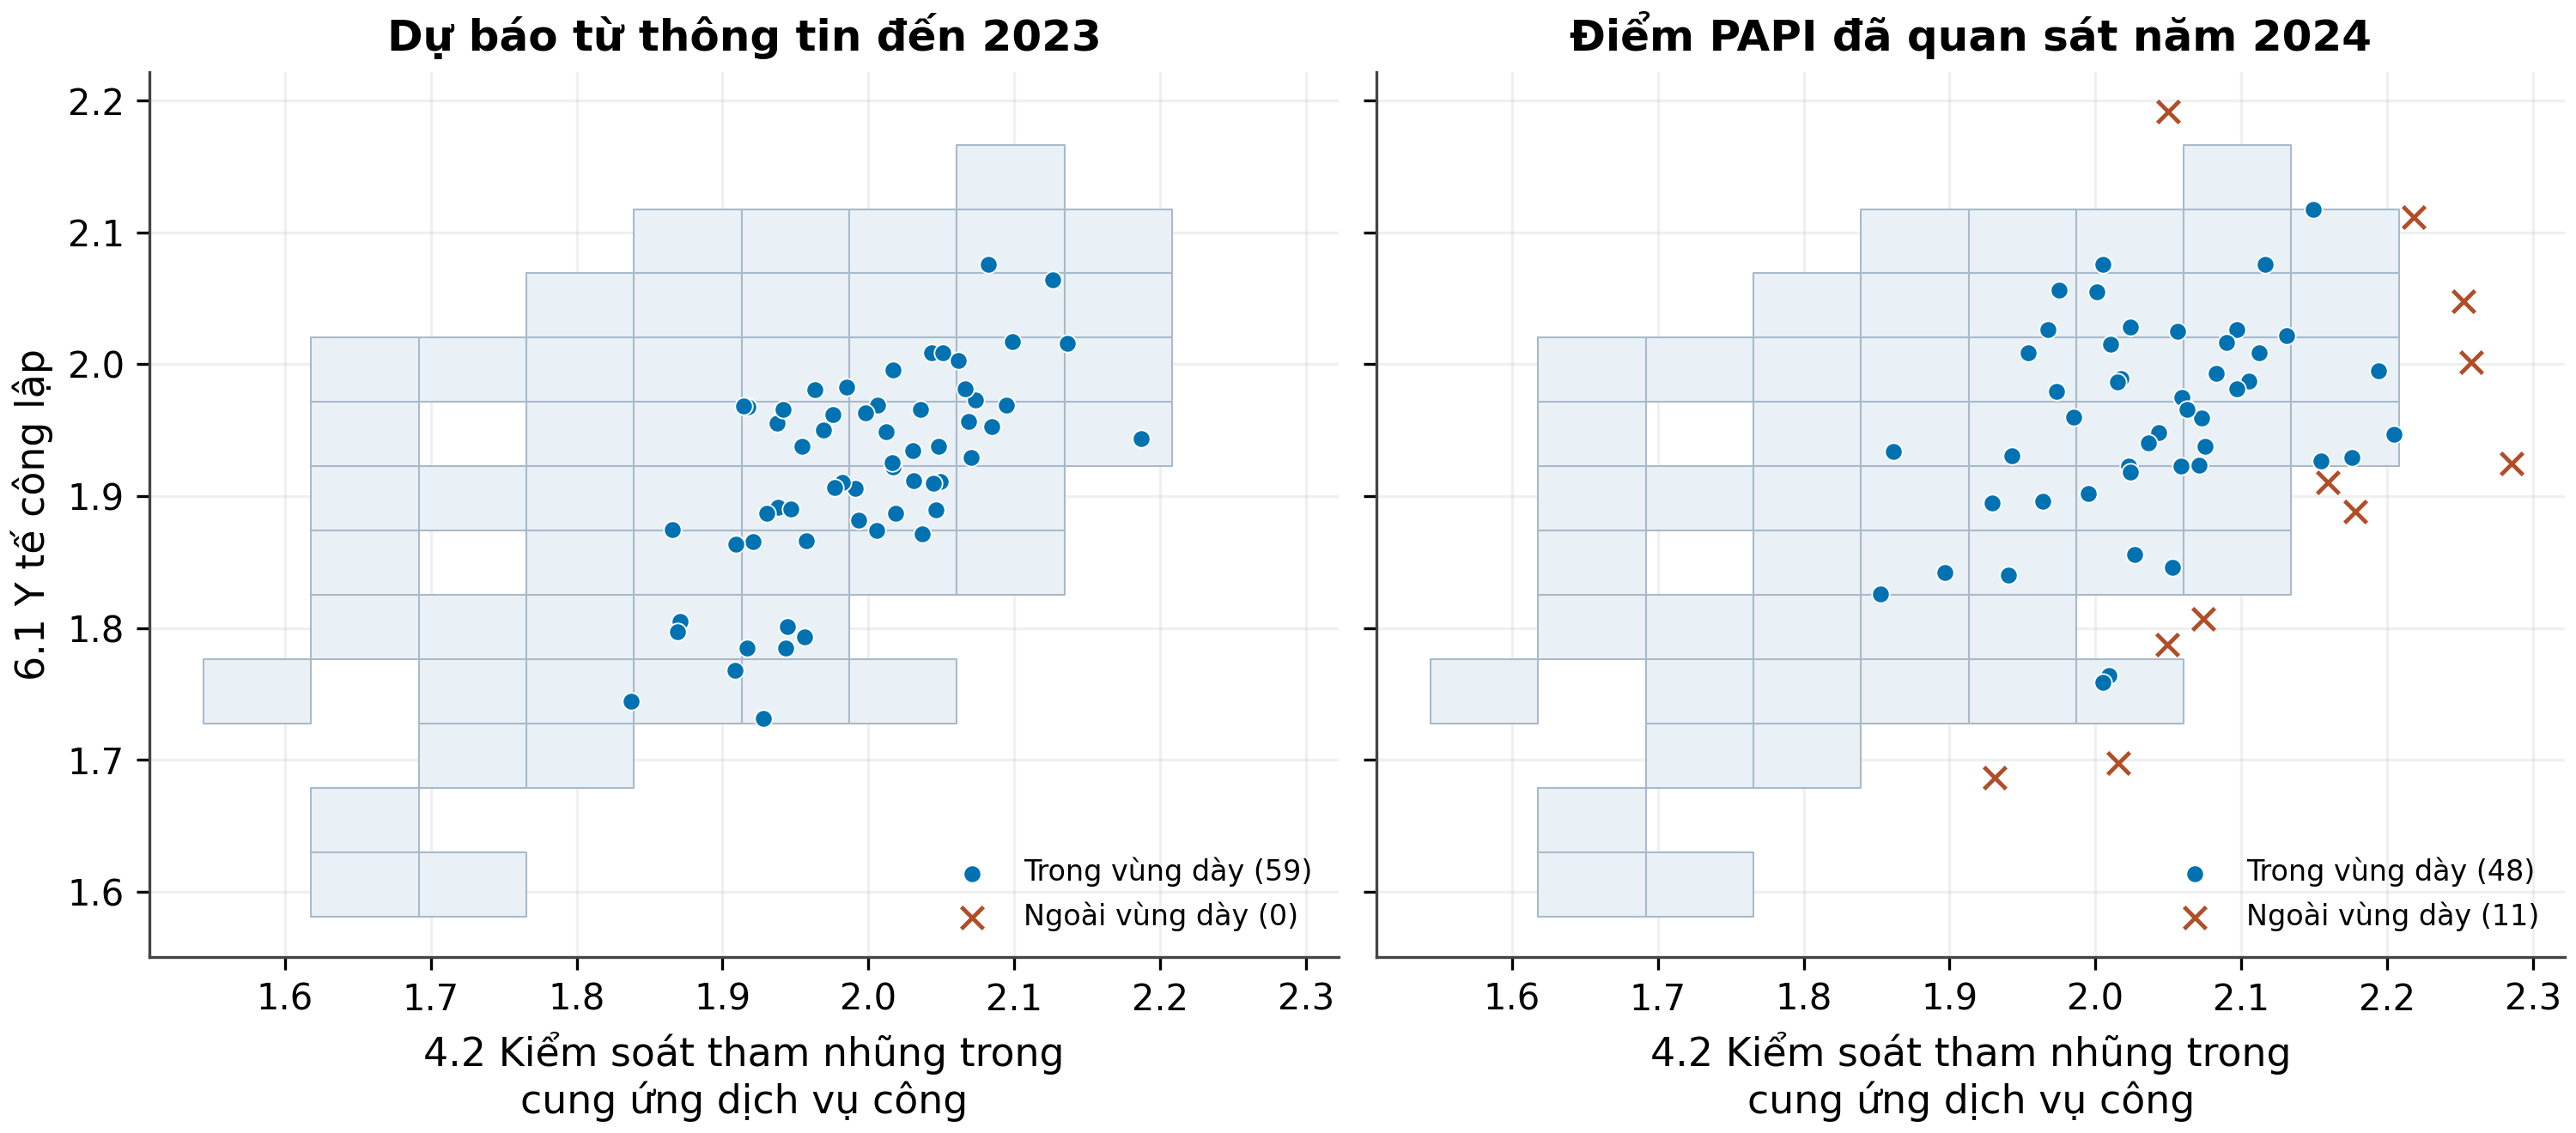

In [14]:
from scripts.common.papi_forecast import (
    ORIGIN_YEAR, TARGETS, forecast_from_history, scenario_auc, score_forecast,
)

history = panel.loc[panel.year <= ORIGIN_YEAR].copy()
run_fc = forecast_from_history(history, params)
observed_2024 = panel.loc[panel.year == ORIGIN_YEAR + 1].copy()
scored_fc, errors_fc, zones_fc = score_forecast(run_fc, observed_2024)
archive_fc = pd.read_csv(ROOT / "results/papi_forecast_provinces_2024.csv")
pd.testing.assert_frame_equal(
    scored_fc.astype({"actual_cluster": "float64"}), archive_fc,
    check_dtype=False, check_exact=False, atol=1e-9, rtol=1e-9,
)
display(errors_fc.round(4))
display(zones_fc[[
    "method", "n", "out_correct", "missed_out", "exact_label_agreement", "out_recall", "balanced_zone_accuracy",
]].round(4))
print(f"Kịch bản sai số lịch sử ({run_fc.scenario_count} kịch bản/tỉnh): AUC = {scenario_auc(scored_fc):.4f}.")
display(Image(filename=str(ROOT / "results/figs/papi_forecast_values.png")))
display(Image(filename=str(ROOT / "results/figs/papi_forecast_grid.png")))

### 6.2 Đối chiếu nguồn ngoài PAPI (PCI, Y tế ODM 2020, GRDP & WDI)

Đối chiếu nhãn STING đóng băng với nguồn thu thập bên ngoài PAPI để mô tả đặc trưng kinh tế–xã hội. Nguồn ngoài không cung cấp nhãn đúng cho các cụm. Quan sát lặp theo tỉnh, khác biệt năm và nhiều phép thử hạn chế ý nghĩa suy luận của p-value gộp. Số điểm cơ sở y tế ODM bằng 0 là nguồn không ghi nhận điểm, không chứng minh địa phương không có cơ sở y tế.

| section             | group             |   n |      median |        mean | note                                                                             |
|:--------------------|:------------------|----:|------------:|------------:|:---------------------------------------------------------------------------------|
| pci_2011_2022       | nhiễu (–1)        | 149 |   59.16     |   59.798    |                                                                                  |
| pci_2011_2022       | cụm 0             |   5 |   58.47     |   58.996    |                                                                                  |
| pci_2011_2022       | cụm 1             |  16 |   58.19     |   58.78     |                                                                                  |
| pci_2011_2022       | cụm 2             | 577 |   62.16     |   61.66     |                                                                                  |
| pci_2011_2022       | ANOVA F(3,743)    | 747 |             |             | F = 9.0426; p = 6.93e-06                                                         |
| pci_2011_2022       | Kruskal–Wallis    | 747 |             |             | H = 31.7751; p = 5.84e-07                                                        |
| pci_2011_2022       | eta squared       | 747 |             |             | eta² = 0.0352 (SS giữa / SS tổng)                                                |
| pci_top30_2023_2024 | nhiễu (–1)        |  13 |   68.916    |   69.472    |                                                                                  |
| pci_top30_2023_2024 | cụm 2             |  45 |   68.996    |   69.016    |                                                                                  |
| pci_top30_2023_2024 | ANOVA F(1,56)     |  58 |             |             | F = 0.8880; p = 0.35                                                             |
| pci_top30_2023_2024 | Kruskal–Wallis    |  58 |             |             | H = 0.2261; p = 0.634                                                            |
| pci_top30_2023_2024 | eta squared       |  58 |             |             | eta² = 0.0156 (SS giữa / SS tổng)                                                |
| odm_health_2020     | nhiễu (–1)        |   6 |    0.000748 |    0.00174  | tổng 16 cơ sở / 6.19 triệu người → 0.002585 cơ sở/1.000 dân (theo quy mô nhóm)   |
| odm_health_2020     | cụm 2             |  57 |    0.002203 |    0.003924 | tổng 407 cơ sở / 91.39 triệu người → 0.004453 cơ sở/1.000 dân (theo quy mô nhóm) |
| grdp_2018_2024      | nhiễu (–1)        |   2 |   61.08     |   61.08     |                                                                                  |
| grdp_2018_2024      | nhiễu (–1)        |   7 |   58.85     |   63.54     |                                                                                  |
| grdp_2018_2024      | nhiễu (–1)        |   6 |   53.12     |   68.64     |                                                                                  |
| grdp_2018_2024      | nhiễu (–1)        |   7 |   68.9      |   78.07     |                                                                                  |
| grdp_2018_2024      | nhiễu (–1)        |   4 |  129.11     |  171.4      |                                                                                  |
| grdp_2018_2024      | nhiễu (–1)        |   9 |   93.17     |   92.16     |                                                                                  |
| grdp_2018_2024      | nhiễu (–1)        |  13 |  103.52     |  128.38     |                                                                                  |
| grdp_2018_2024      | cụm 1             |   1 |  104.42     |  104.42     |                                                                                  |
| grdp_2018_2024      | cụm 2             |  58 |   48.14     |   60.36     |                                                                                  |
| grdp_2018_2024      | cụm 2             |  56 |   53.75     |   67.21     |                                                                                  |
| grdp_2018_2024      | cụm 2             |  57 |   57.72     |   68.83     |                                                                                  |
| grdp_2018_2024      | cụm 2             |  53 |   57.5      |   69.57     |                                                                                  |
| grdp_2018_2024      | cụm 2             |  57 |   67.67     |   75.56     |                                                                                  |
| grdp_2018_2024      | cụm 2             |  52 |   71.75     |   83.05     |                                                                                  |
| grdp_2018_2024      | cụm 2             |  48 |   80.97     |   87.23     |                                                                                  |
| wdi_2010_2024       | NY.GDP.PCAP.CD    |  15 | 2956.11     | 3072.16     | cửa sổ thật 2010–2024 (15/15 năm); phần thiếu là phía nguồn — không nội suy      |
| wdi_2010_2024       | SH.MED.BEDS.ZS    |   8 |    2.36     |    2.34     | cửa sổ thật 2010–2017 (8/15 năm); phần thiếu là phía nguồn — không nội suy       |
| wdi_2010_2024       | SH.XPD.CHEX.GD.ZS |  14 |    4.791    |    4.764    | cửa sổ thật 2010–2023 (14/15 năm); phần thiếu là phía nguồn — không nội suy      |
| wdi_2010_2024       | SP.URB.TOTL.IN.ZS |  15 |   33.363    |   33.94     | cửa sổ thật 2010–2024 (15/15 năm); phần thiếu là phía nguồn — không nội suy      |

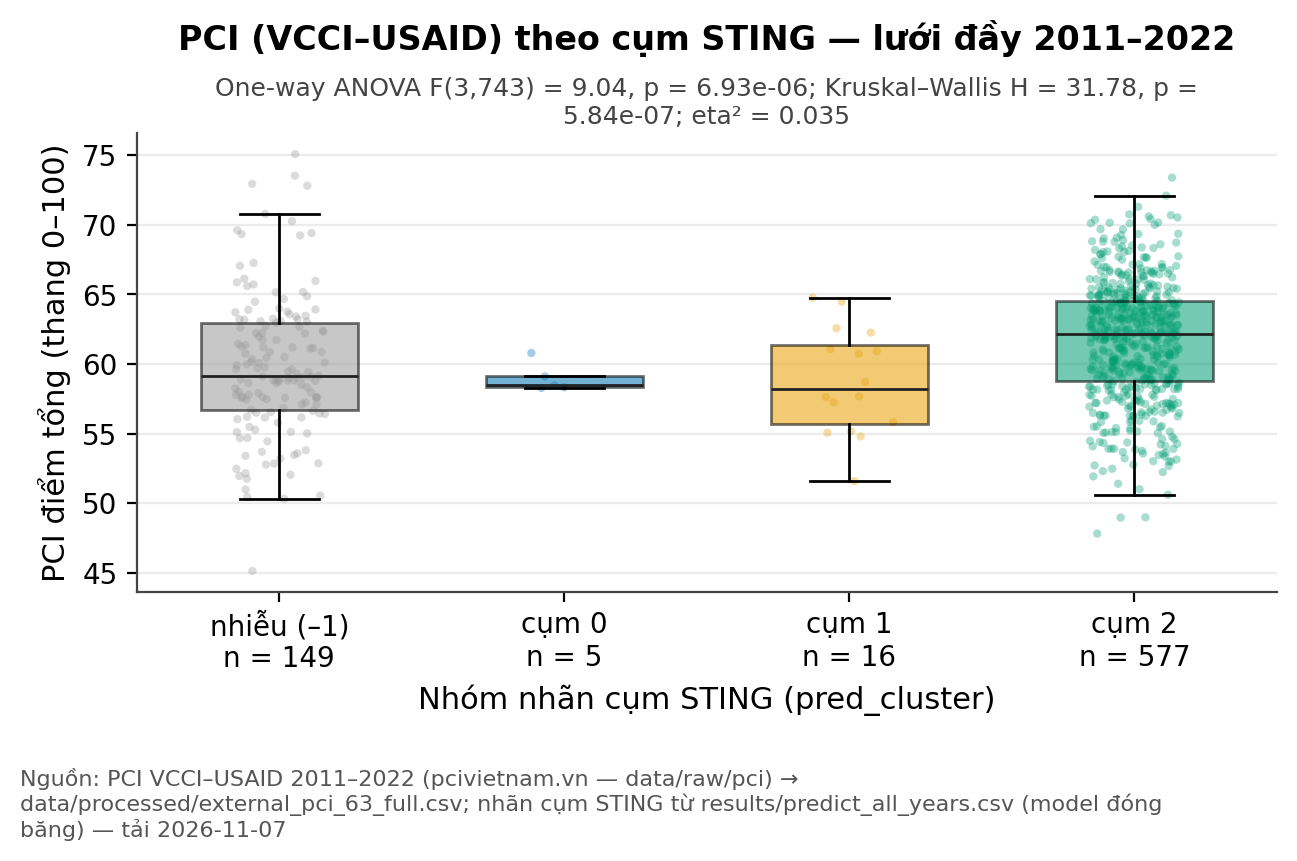

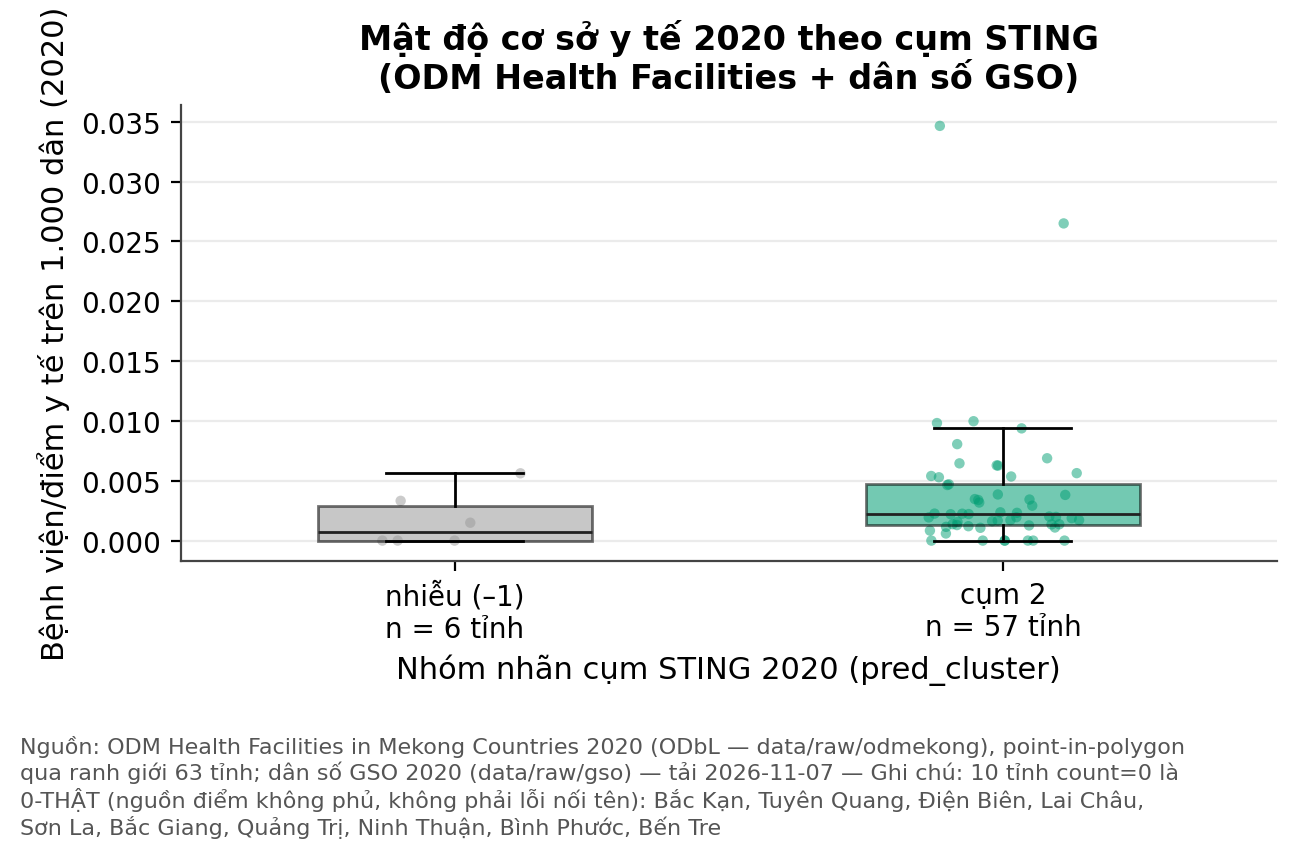

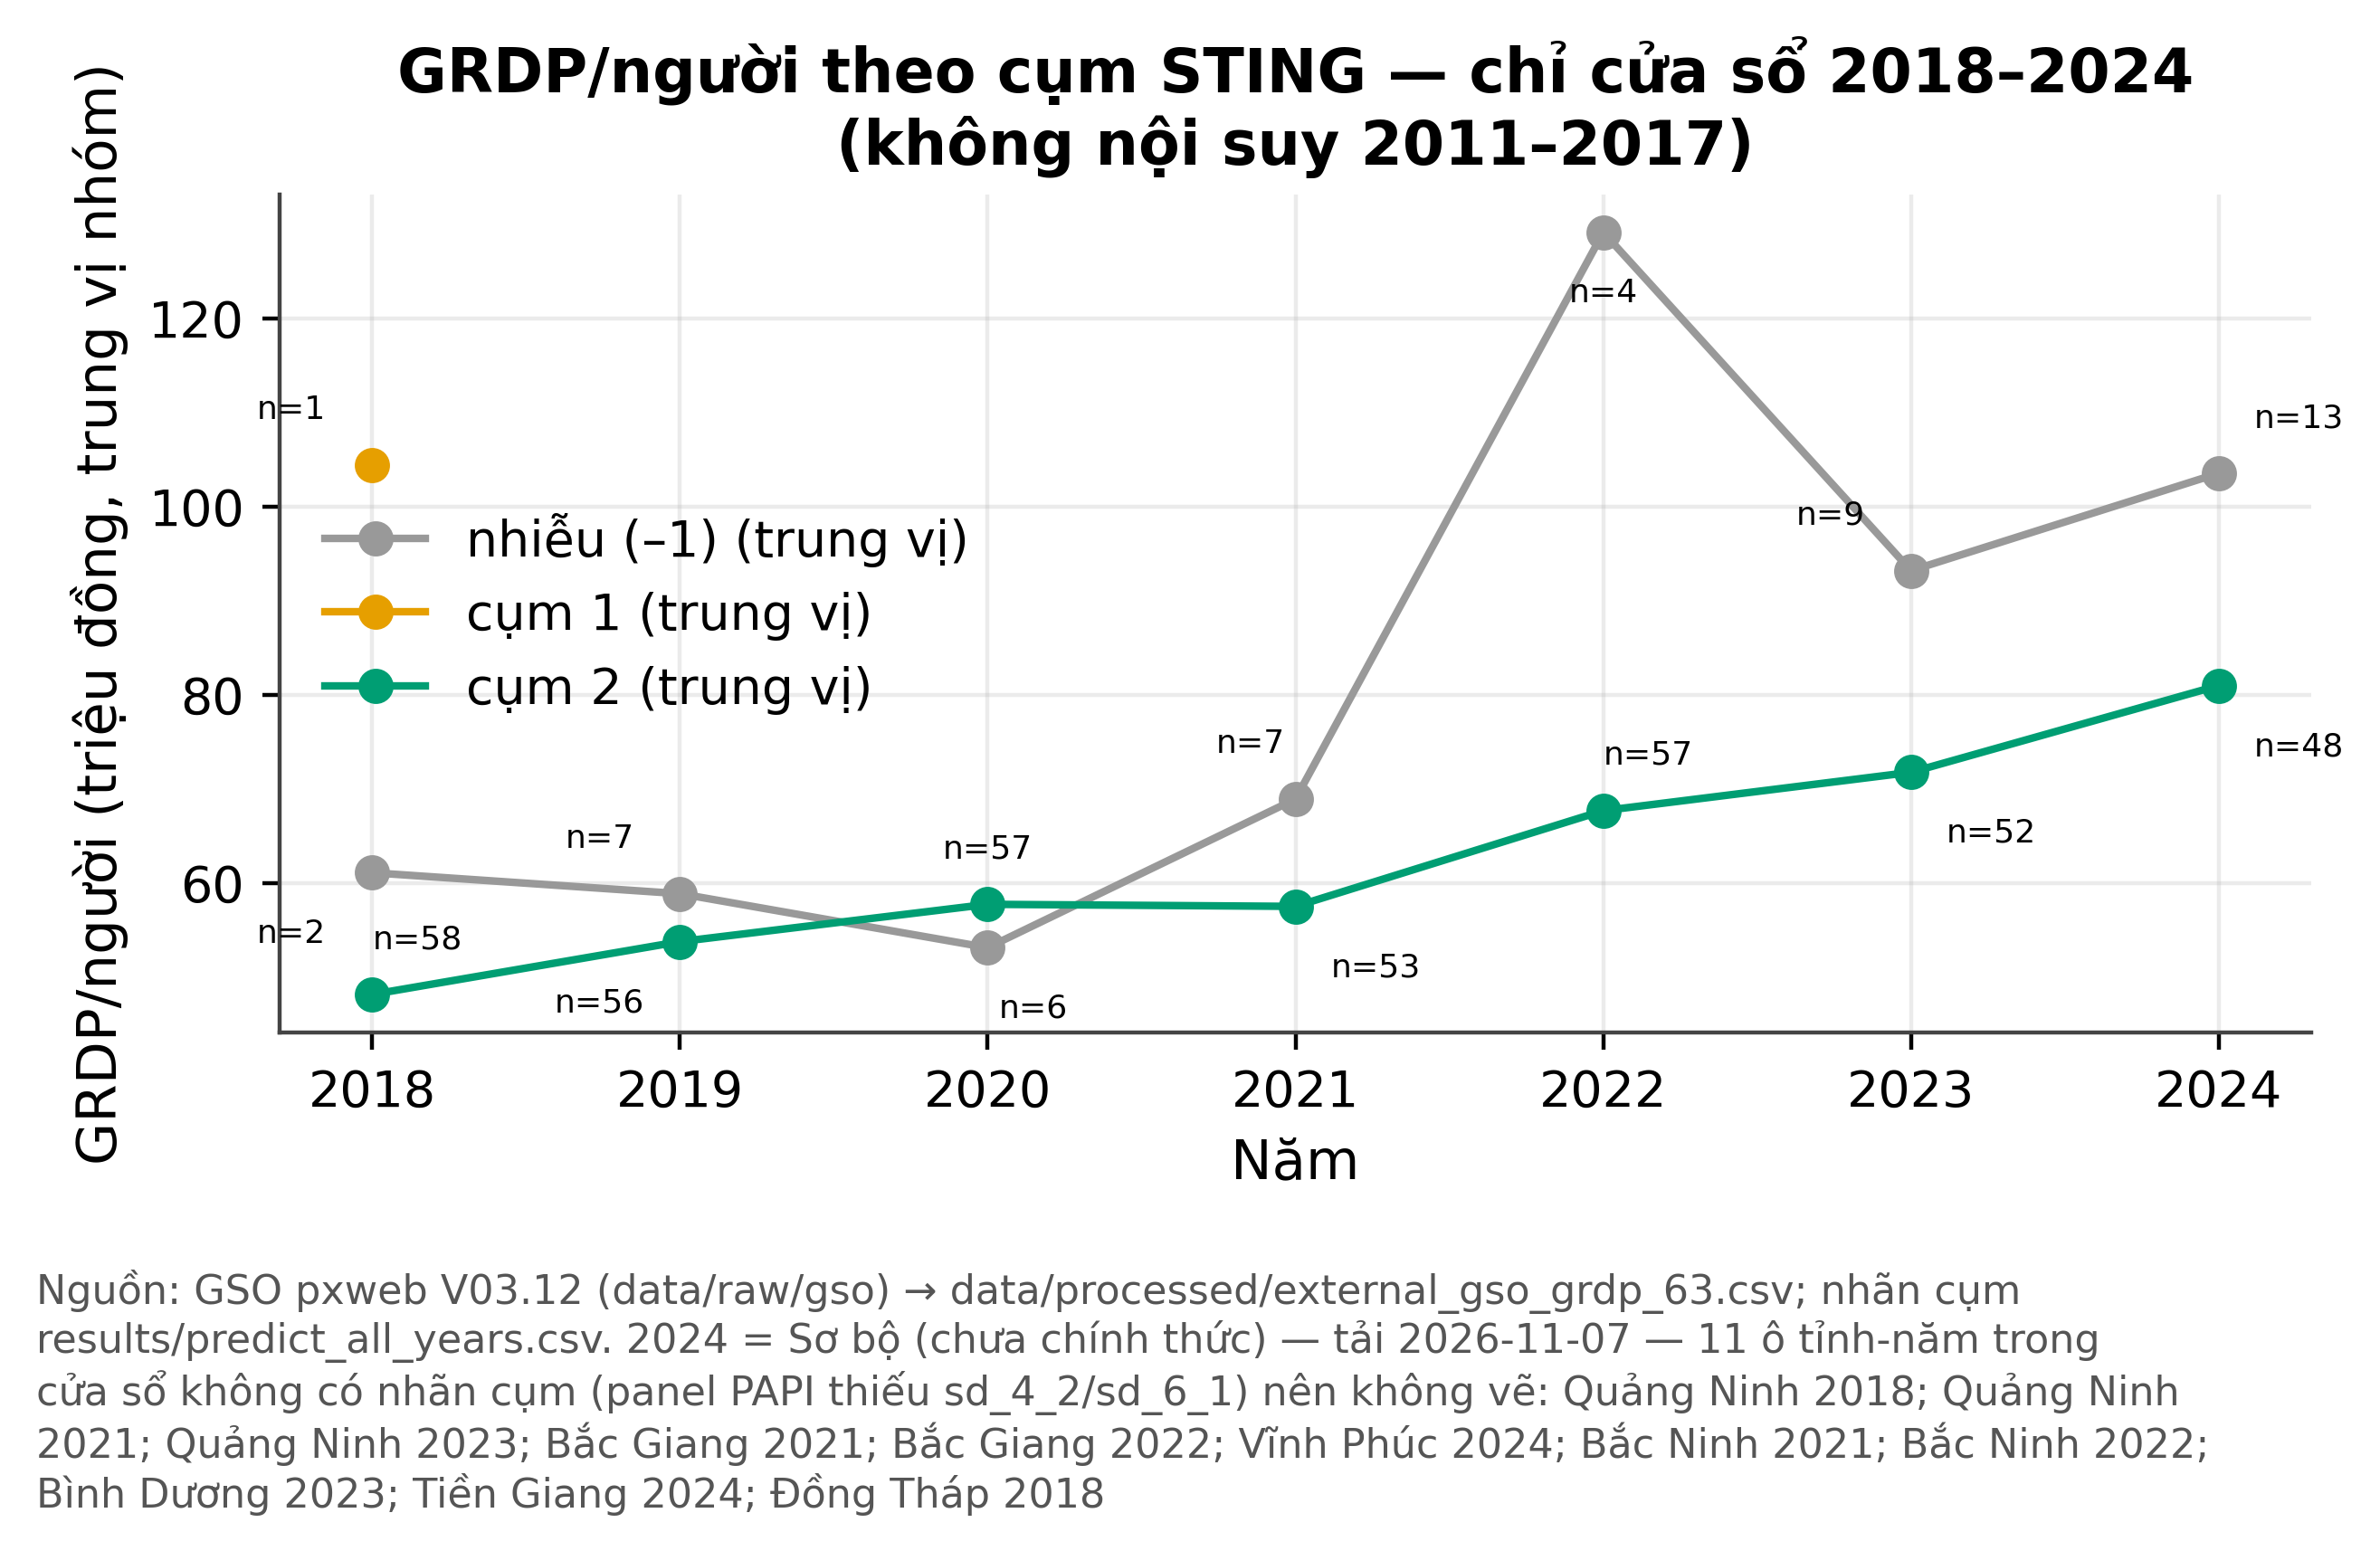

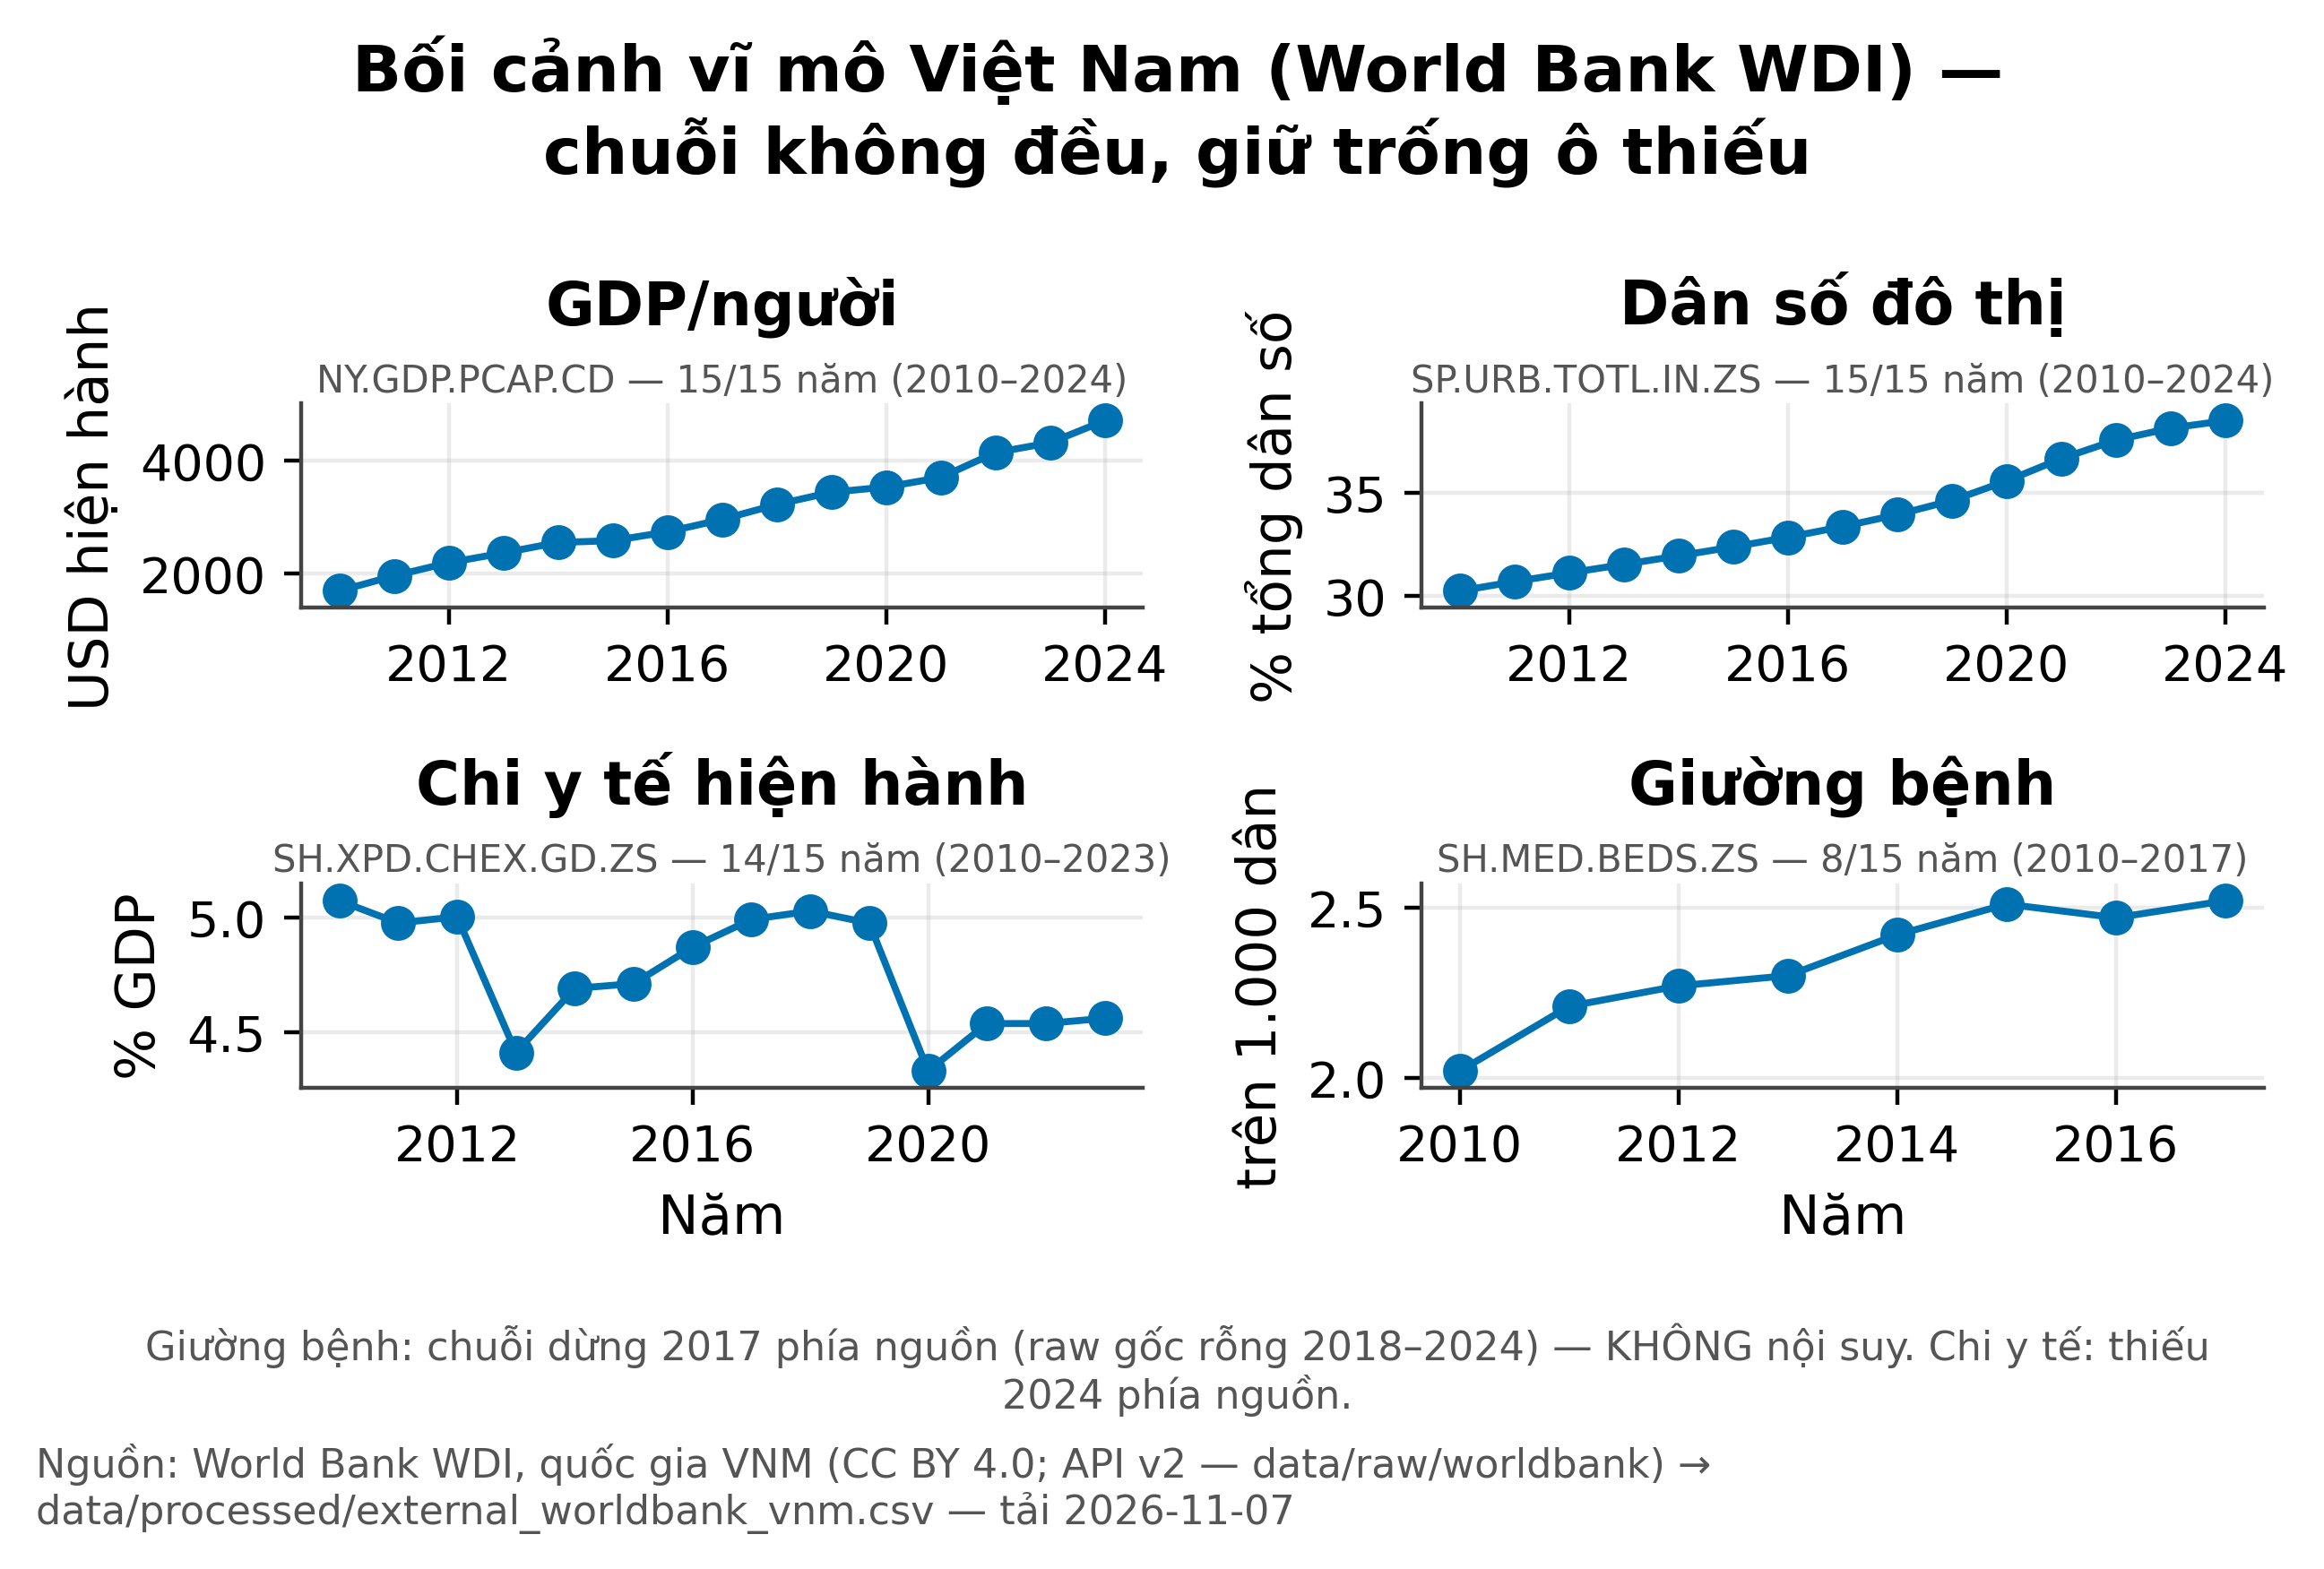

In [15]:
ext_val = pd.read_csv(ROOT / "results/external_validation.csv")
show_md(ext_val[["section", "group", "n", "median", "mean", "note"]].fillna("").to_markdown(index=False))
for fig_name in (
    "external_pci_by_cluster.png",
    "external_health_density_2020.png",
    "external_grdp_by_cluster.png",
    "external_wdi_panel.png",
):
    display(Image(filename=str(ROOT / "results/figs" / fig_name)))

## Phần 7. Kết luận tổng hợp và giới hạn diễn giải

1. **Ý nghĩa thuật toán:** Biến thể STING (`16 × 16`, `min_count = 5`, kề 4 hướng) mô tả vùng dày chiếm ưu thế và các ô thưa. Khi dựng lại lưới đều trên cùng mẫu toàn kỳ, `869/869` điểm giữ nguyên chỉ số ô sau z-score; kết quả này không áp dụng cho mọi phép biến đổi hoặc mọi thuật toán.
2. **Giá trị bàn giao:** Bảng mô tả 63 tỉnh gồm **48 trong vùng dày, 8 ngoài vùng dày về phía điểm cao, 5 ngoài vùng dày có điểm 6.1 thấp và 2 thiếu dữ liệu**. Bảng đi kèm dịch chuyển 2023→2024, chỉ số kịch bản hồi cứu và đối chiếu GRDP/PCI để gợi ý rà soát; chưa xếp hạng chất lượng hoặc xác định nguyên nhân.
3. **Giới hạn:** Trên 808 quan sát lịch sử, 629/650 điểm đã vào cụm thuộc Cụm 2; các cụm 0 (`n=5`) và 1 (`n=16`) nhỏ. Kết quả nhạy với tham số và biểu diễn, còn một giai đoạn đối chiếu `2023→2024` chưa xác lập khả năng dự báo dài hạn. Cần dữ liệu độc lập và đánh giá cuốn chiếu trước khi dùng để ra quyết định.

**Nguồn:** Wang, Yang & Muntz (VLDB 1997), PAPI (CECODES/VFF-CRT/RTA/UNDP), Mendeley DOI `10.17632/wbk42j9wc8.1`, VCCI–USAID PCI, GSO PX-Web & OD Mekong.

## Phụ lục A. Kiểm tra bổ sung trên nhiều chỉ tiêu (PCA & 8D OFAT)

- Hai thành phần PCA từ 6 chiều 2011–2024 giữ `63.2%` phương sai và chỉ cho `1` cụm.
- Không gian 8 chiều giai đoạn 2018–2024 tại cấu hình gốc cho `3` cụm với `60.5%` nhiễu.
- Nhãn verdict trong bảng là quy tắc lọc theo số cụm và nhiễu, chưa xác nhận chất lượng phân cụm. Ví dụ `min_count = 2` giảm nhiễu nhưng silhouette âm (`−0,089`), cho thấy độ tách yếu.

In [16]:
rob_tbl = pd.read_csv(ROOT / "results/robustness.csv")
show_md(rob_tbl.to_markdown(index=False))

| branch                                                                   |   n |   explained_var_total |   k |   noise_ratio |   silhouette |        db |        ch |   ari_vs_2d | verdict         |
|:-------------------------------------------------------------------------|----:|----------------------:|----:|--------------:|-------------:|----------:|----------:|------------:|:----------------|
| PCA(2) d1–d6, within-year z, pooled                                      | 869 |                 0.632 |   1 |         0.062 |  nan         | nan       | nan       |       0.008 | không nhận diện |
| 8 chiều 2018–2024, within-year z, L=3 f=2 mc=10 lv=1 (gốc OFAT)          | 430 |               nan     |   3 |         0.605 |    0.297194  |   1.13107 |  83.8316  |     nan     | không nhận diện |
| 8 chiều 2018–2024, within-year z, OFAT f=3 (còn như gốc: L=3 mc=10 lv=1) | 430 |               nan     |   1 |         0.919 |  nan         | nan       | nan       |     nan     | không nhận diện |
| 8 chiều 2018–2024, within-year z, OFAT mc=2 (còn như gốc: L=3 f=2 lv=1)  | 430 |               nan     |   2 |         0.109 |   -0.0886574 |   1.49983 |   1.14207 |     nan     | có cấu trúc     |
| 8 chiều 2018–2024, within-year z, OFAT lv=2 (còn như gốc: L=3 f=2 mc=10) | 430 |               nan     |   0 |         1     |  nan         | nan       | nan       |     nan     | không nhận diện |

## Phụ lục B. Thí nghiệm học phần có giám sát trên 6.1, nhãn lưới và cân bằng lớp

Thí nghiệm đơn chỉ tiêu chọn mô hình hồi quy `6.1` theo CV R², bài toán phân loại đo mức khớp pseudo-label vùng dày STING (kèm `class_weight='balanced'` trên 6 fold expanding-origin 2017–2022) và đối chiếu 6 bộ phân loại chuẩn của học phần. Đây không phải nhãn chất lượng quản trị do chuyên gia cung cấp. Việc chọn tham số và báo cáo điểm trên cùng các fold có thể lạc quan; thông tin 2021–2022 từng dùng để chọn cấu hình STING còn chồng lấn các fold sau. Chưa định lượng độ lớn thiên lệch này.

| task           | model                               | metric_cv                             |   value_cv |   holdout_mae |   holdout_rmse |   holdout_r2 |   holdout_acc |   holdout_macro_f1 |
|:---------------|:------------------------------------|:--------------------------------------|-----------:|--------------:|---------------:|-------------:|--------------:|-------------------:|
| regression     | carry-forward (giữ giá trị năm nay) | r2 (expanding origin 2017–2022)       |      0.145 |        0.0683 |         0.0875 |        0.198 |       nan     |            nan     |
| regression     | trung bình train                    | r2 (expanding origin 2017–2022)       |     -0.77  |        0.0814 |         0.1027 |       -0.105 |       nan     |            nan     |
| regression     | ridge                               | r2 (expanding origin 2017–2022)       |      0.265 |        0.064  |         0.0769 |        0.381 |       nan     |            nan     |
| regression     | random forest                       | r2 (expanding origin 2017–2022)       |      0.197 |        0.0616 |         0.0742 |        0.423 |       nan     |            nan     |
| classification | majority (lớp đa số)                | f1_macro (expanding origin 2017–2022) |      0.228 |      nan      |       nan      |      nan     |         0.186 |              0.157 |
| classification | logistic regression                 | f1_macro (expanding origin 2017–2022) |      0.434 |      nan      |       nan      |      nan     |         0.644 |              0.541 |
| classification | random forest                       | f1_macro (expanding origin 2017–2022) |      0.397 |      nan      |       nan      |      nan     |         0.678 |              0.6   |
| classification | logistic regression (balanced)      | f1_macro (expanding origin 2017–2022) |      0.486 |      nan      |       nan      |      nan     |         0.746 |              0.595 |
| classification | random forest (balanced)            | f1_macro (expanding origin 2017–2022) |      0.524 |      nan      |       nan      |      nan     |         0.712 |              0.569 |

Ridge holdout 2023→2024 (59 cặp): MAE = 0.0640, R² = 0.3814.


Classifier chính (random forest (balanced)) holdout 2023→2024 (59 cặp): LogLoss = 0.5640, Acc = 0.712, Macro-F1 = 0.569.


| Mô hình                       |   Macro-F1 CV (6 fold) |   Acc holdout |   Macro-F1 holdout |   Recall lớp 0 |
|:------------------------------|-----------------------:|--------------:|-------------------:|---------------:|
| LR gốc                        |                 0.4342 |        0.6441 |             0.5406 |         0.4545 |
| LR balanced (C=0,3)           |                 0.4861 |        0.7458 |             0.595  |         0.3636 |
| RF balanced (depth=6, leaf=2) |                 0.5238 |        0.7119 |             0.5686 |         0.3636 |

| model                | metric_cv                             |   value_cv |   holdout_acc |   holdout_macro_f1 |   cv_std |   cv_folds |
|:---------------------|:--------------------------------------|-----------:|--------------:|-------------------:|---------:|-----------:|
| majority (lớp đa số) | f1_macro (expanding origin 2017–2022) |      0.228 |         0.186 |              0.157 |    0.107 |          6 |
| gaussian naive bayes | f1_macro (expanding origin 2017–2022) |      0.514 |         0.746 |              0.566 |    0.12  |          6 |
| knn                  | f1_macro (expanding origin 2017–2022) |      0.486 |         0.593 |              0.534 |    0.066 |          6 |
| svm (linear)         | f1_macro (expanding origin 2017–2022) |      0.343 |         0.695 |              0.556 |    0.127 |          6 |
| svm (rbf)            | f1_macro (expanding origin 2017–2022) |      0.437 |         0.678 |              0.566 |    0.126 |          6 |
| decision tree        | f1_macro (expanding origin 2017–2022) |      0.426 |         0.559 |              0.508 |    0.091 |          6 |
| random forest        | f1_macro (expanding origin 2017–2022) |      0.394 |         0.627 |              0.56  |    0.07  |          6 |
| logistic regression  | f1_macro (expanding origin 2017–2022) |      0.434 |         0.644 |              0.541 |    0.056 |          6 |

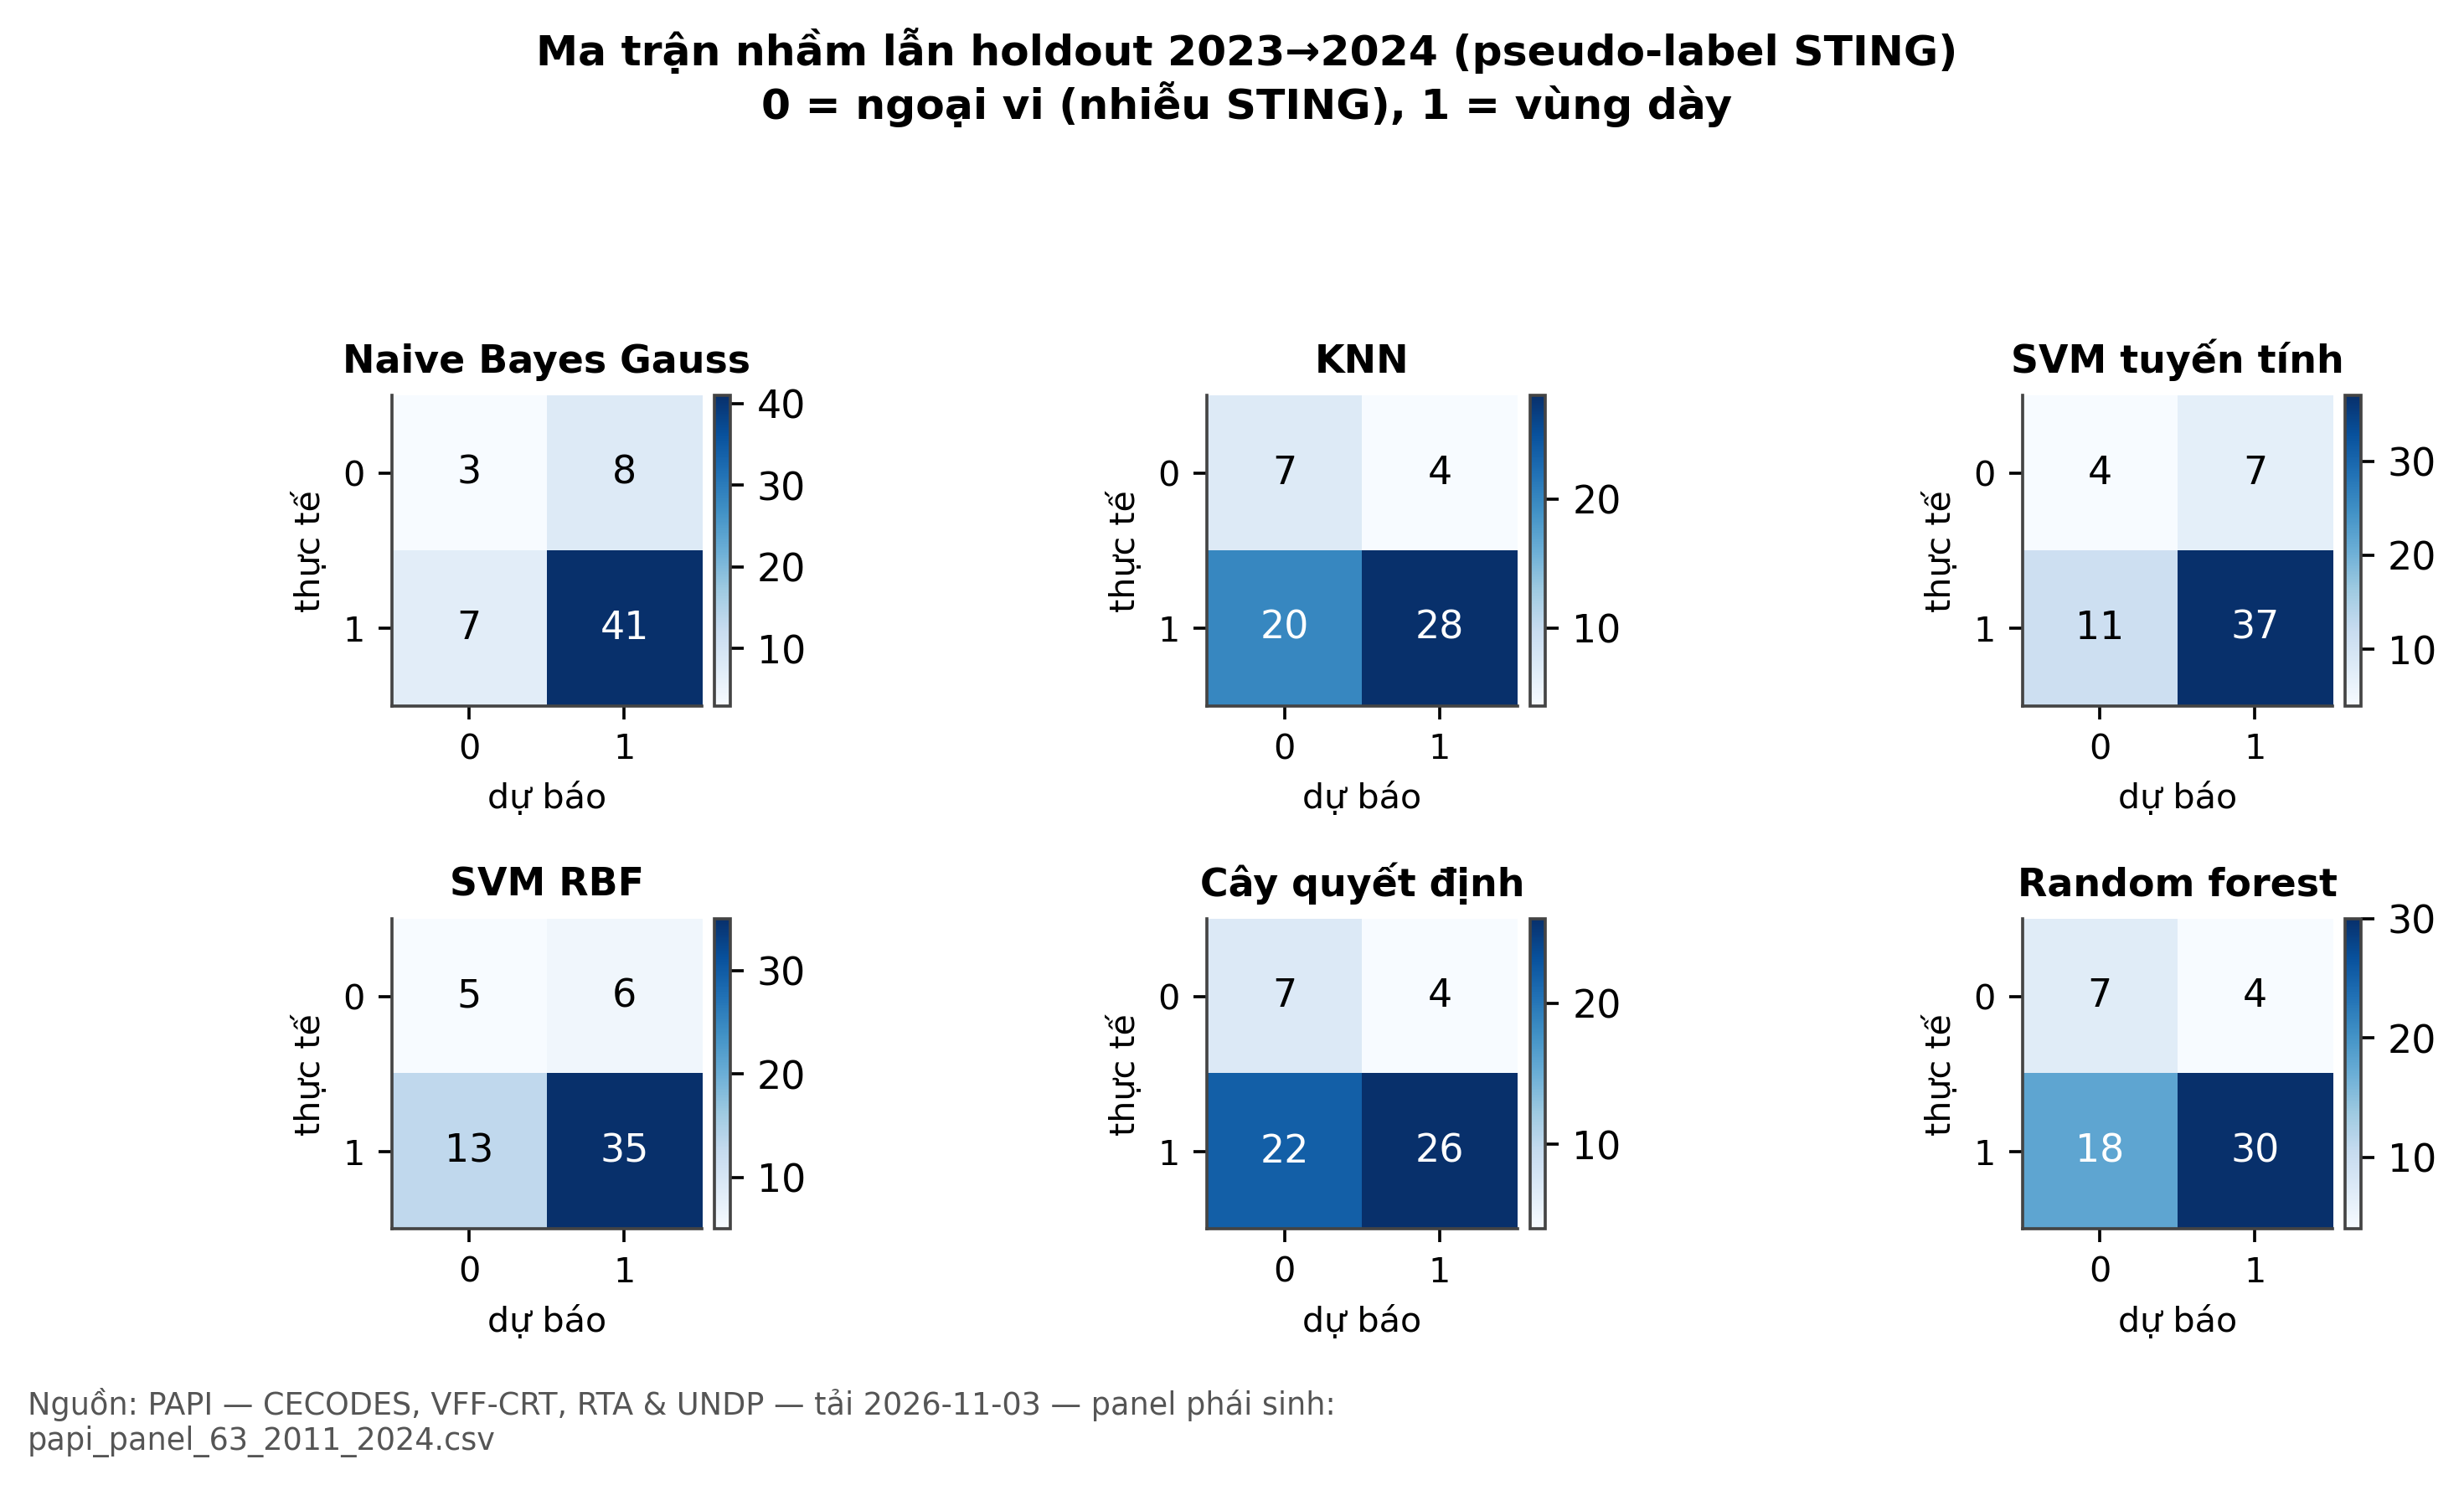

In [17]:
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, log_loss, mean_absolute_error, r2_score, recall_score
from sklearn.pipeline import Pipeline
from scripts.common.papi_pred_common import REGRESSION_FEATURES
from scripts.supervised.predict_supervised import (
    build_classification_pairs,
    build_regression_pairs,
    expanding_year_splits,
)

sup_tbl = pd.read_csv(ROOT / "results/supervised_metrics.csv")
show_md(sup_tbl.to_markdown(index=False))

reg_pairs = build_regression_pairs(panel)
ridge_m = joblib.load(ROOT / "models/sup_ridge.joblib")
holdout_reg = reg_pairs[reg_pairs.year_t == 2023]
y_true_r = holdout_reg.y.to_numpy()
y_pred_r = ridge_m.predict(holdout_reg[REGRESSION_FEATURES].to_numpy())
print(
    f"Ridge holdout 2023→2024 ({len(holdout_reg)} cặp): MAE = {mean_absolute_error(y_true_r, y_pred_r):.4f}, "
    f"R² = {r2_score(y_true_r, y_pred_r):.4f}."
)

clf_m = joblib.load(ROOT / "models/sup_classifier.joblib")
from scripts.analysis.dashboard_data import select_classification_model
clf_name = select_classification_model(sup_tbl)
clf_pairs = build_classification_pairs(panel, feats, params)
clf_hold = clf_pairs[clf_pairs.year_t == 2023]
Xc_te, yc_te = clf_hold[REGRESSION_FEATURES].to_numpy(), clf_hold["y"].to_numpy()
print(
    f"Classifier chính ({clf_name}) holdout 2023→2024 ({len(yc_te)} cặp): "
    f"LogLoss = {log_loss(yc_te, clf_m.predict_proba(Xc_te)[:, 1]):.4f}, "
    f"Acc = {accuracy_score(yc_te, clf_m.predict(Xc_te)):.3f}, "
    f"Macro-F1 = {f1_score(yc_te, clf_m.predict(Xc_te), average='macro', labels=[0, 1], zero_division=0):.3f}."
)

clf_tr = clf_pairs[clf_pairs.year_t < 2023].reset_index(drop=True)
X_ctr, y_ctr = clf_tr[REGRESSION_FEATURES].to_numpy(), clf_tr["y"].to_numpy()
splits_cv = expanding_year_splits(clf_tr["year_t"].to_numpy(), y_ctr)
bal_rows = []
for bname, bfactory in (
    ("LR gốc", lambda: Pipeline([("sc", StandardScaler()), ("m", LogisticRegression(C=1.0, max_iter=3000, random_state=42))])),
    ("LR balanced (C=0,3)", lambda: Pipeline([("sc", StandardScaler()), ("m", LogisticRegression(C=0.3, class_weight="balanced", max_iter=3000, random_state=42))])),
    ("RF balanced (depth=6, leaf=2)", lambda: RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=2, class_weight="balanced", random_state=42, n_jobs=1)),
):
    cv_mf1 = [
        f1_score(y_ctr[vi], bfactory().fit(X_ctr[ti], y_ctr[ti]).predict(X_ctr[vi]), average="macro", labels=[0, 1], zero_division=0)
        for ti, vi in splits_cv
    ]
    bfit = bfactory().fit(X_ctr, y_ctr)
    bpred = bfit.predict(Xc_te)
    bal_rows.append((bname, float(np.mean(cv_mf1)), accuracy_score(yc_te, bpred),
                     f1_score(yc_te, bpred, average="macro", labels=[0, 1], zero_division=0),
                     recall_score(yc_te, bpred, pos_label=0)))
show_md(pd.DataFrame(bal_rows, columns=["Mô hình", "Macro-F1 CV (6 fold)", "Acc holdout", "Macro-F1 holdout", "Recall lớp 0"]).round(4).to_markdown(index=False))

course_tbl = pd.read_csv(ROOT / "results/course_supervised_baselines.csv")
show_md(course_tbl.to_markdown(index=False))
display(Image(filename=str(ROOT / "results/figs/course_confusion_matrix.png")))

## Phụ lục C. Đối chiếu tỷ lệ hộ nghèo cấp tỉnh GSO (2012–2024)

Đối chiếu cả dữ liệu gộp thô và dữ liệu đã trừ trung vị theo năm. Phép trừ chỉ loại vị trí trung tâm chung của từng năm; không bảo đảm khử thay đổi chuẩn nghèo, phụ thuộc theo tỉnh hay các yếu tố gây nhiễu. Các kiểm định gộp mang tính thăm dò và không cung cấp nhãn đúng cho STING.

| section                 | group      |   year |   n |   mean |   median |   std |   min |   max |   note |
|:------------------------|:-----------|-------:|----:|-------:|---------:|------:|------:|------:|-------:|
| poverty_pooled_raw      | nhiễu (–1) |    nan | 144 |  9.872 |     6.6  | 9.937 |   0   |  42.3 |    nan |
| poverty_pooled_raw      | cụm 0      |    nan |   2 | 14.95  |    14.95 | 3.748 |  12.3 |  17.6 |    nan |
| poverty_pooled_raw      | cụm 1      |    nan |  10 |  4.55  |     3.25 | 3.641 |   1.2 |  12.1 |    nan |
| poverty_pooled_raw      | cụm 2      |    nan | 649 |  9.008 |     6.2  | 8.729 |   0   |  50.2 |    nan |
| poverty_pooled_demeaned | nhiễu (–1) |    nan | 144 |  2.124 |    -1.05 | 9.071 | -12.8 |  33.7 |    nan |
| poverty_pooled_demeaned | cụm 0      |    nan |   2 |  4.5   |     4.5  | 0.283 |   4.3 |   4.7 |    nan |
| poverty_pooled_demeaned | cụm 1      |    nan |  10 | -6.035 |    -6.2  | 2.848 |  -9   |   0.2 |    nan |
| poverty_pooled_demeaned | cụm 2      |    nan | 649 |  2.444 |     0    | 8.378 | -12.8 |  42.3 |    nan |

Mann–Whitney nhiễu vs cụm 2 (thô): U = 47464; p = 0.767
Mann–Whitney nhiễu vs cụm 2 (đã trừ median năm): U = 43978; p = 0.269


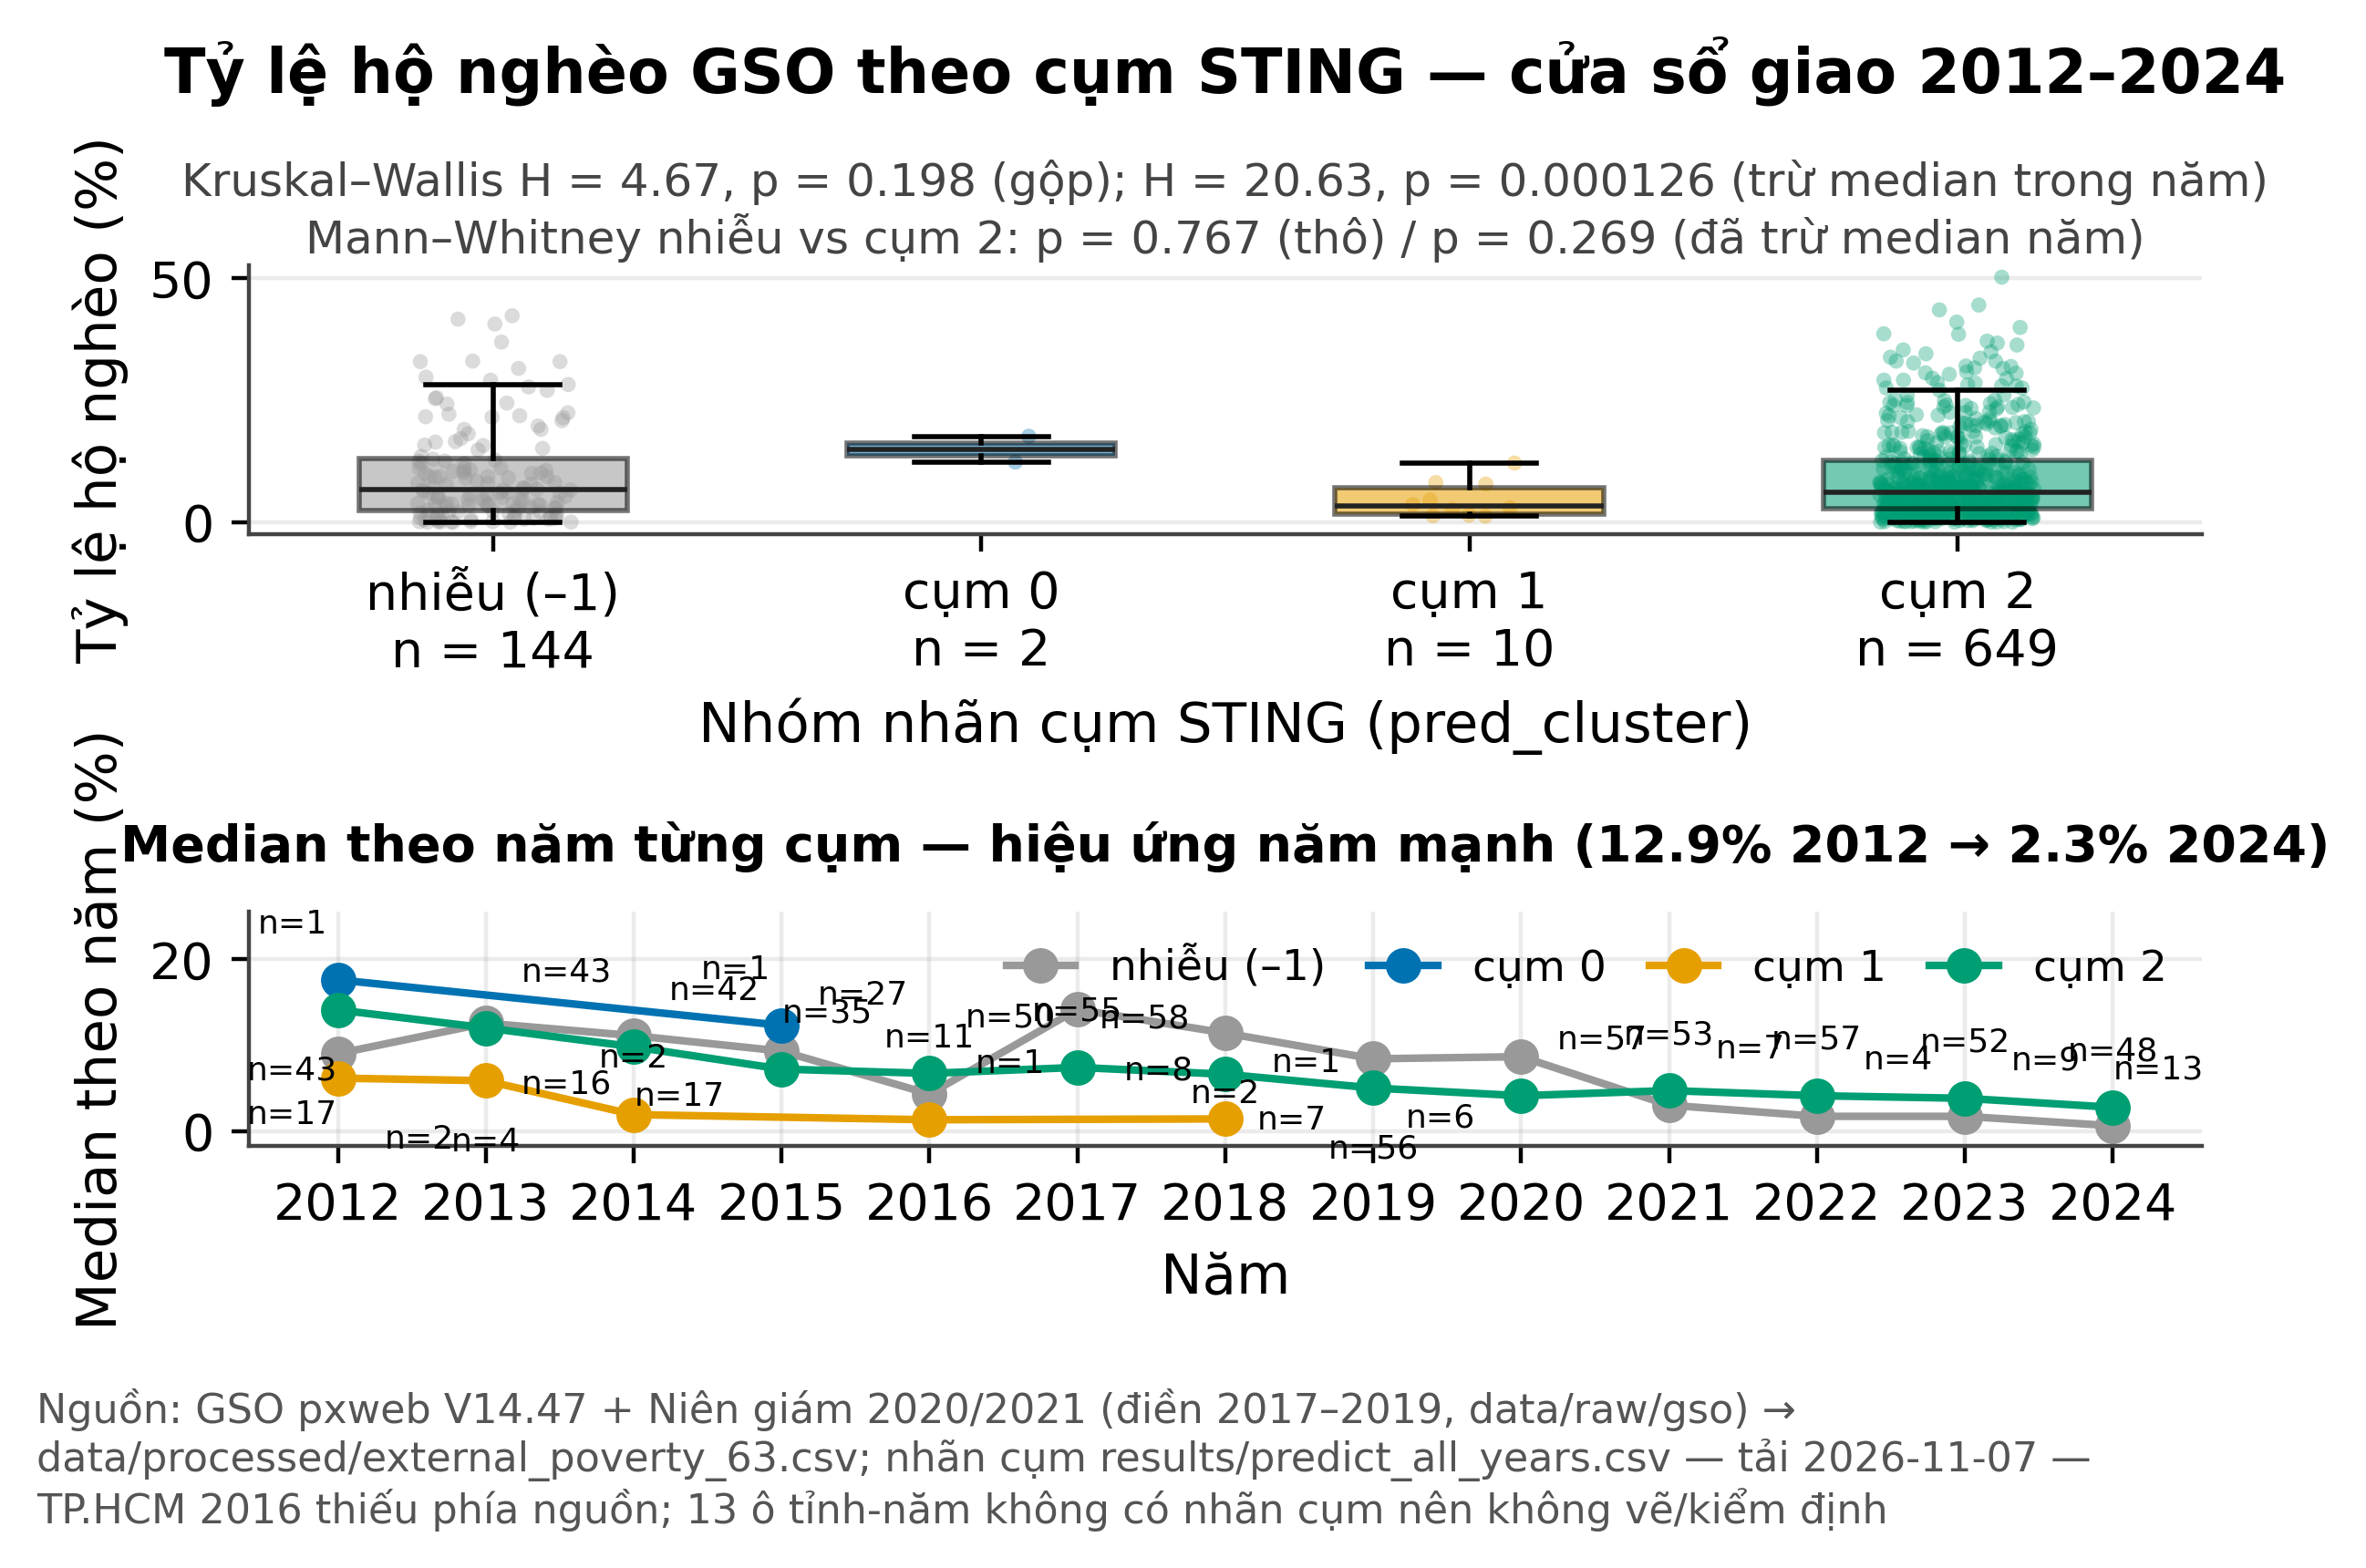

In [18]:
pov = pd.read_csv(ROOT / "results/poverty_validation.csv")
pov_pool = pov[pov.section.isin(["poverty_pooled_raw", "poverty_pooled_demeaned", "test_mw_noise_vs_c2"])].copy()
has_stats = pov_pool["mean"].notna() & pov_pool["mean"].astype(str).str.strip().ne("")
show_md(pov_pool[has_stats].to_markdown(index=False))
for _, r in pov[pov.section == "test_mw_noise_vs_c2"].iterrows():
    print(f"{r['group']}: {r['note']}")
display(Image(filename=str(ROOT / "results/figs/external_poverty_by_cluster.png")))

## Phụ lục D. Thực nghiệm mở rộng tích hợp (E2–E4 & Hướng 5)

Tổng hợp các nhánh mở rộng định lượng đã được tích hợp từ `scripts/analysis/future_work.py`: (i) phân cụm quỹ đạo tuyến tính OLS 63 tỉnh 2011–2024 (`E2`); (ii) backtest cuốn chiếu 6 mốc `2018→2023` (`E3`); và (iii) tự tương quan không gian Queen năm 2024 (`E4`, Moran's I). Nhánh `E1` (chuẩn hóa hạng trong năm) được giữ làm đối chiếu tham khảo do phân mảnh thành `25` cụm với `54,1%` nhiễu.

|   origin_year |   target_year | target   | selected_method   |   mae_forecast |   mae_carry |   mae_gain |   out_recall_forecast |   out_recall_carry |
|--------------:|--------------:|:---------|:------------------|---------------:|------------:|-----------:|----------------------:|-------------------:|
|          2018 |          2019 | sd_4_2   | ridge             |         0.1279 |      0.106  |    -0.022  |                0.2647 |             0.2941 |
|          2018 |          2019 | sd_6_1   | ridge             |         0.0693 |      0.0623 |    -0.0071 |                0.2647 |             0.2941 |
|          2019 |          2020 | sd_4_2   | ridge             |         0.0871 |      0.0845 |    -0.0025 |                0.1154 |             0.5    |
|          2019 |          2020 | sd_6_1   | ridge             |         0.0616 |      0.0666 |     0.0049 |                0.1154 |             0.5    |
|          2020 |          2021 | sd_4_2   | ridge             |         0.109  |      0.1272 |     0.0182 |                0      |             0.0909 |
|          2020 |          2021 | sd_6_1   | ridge             |         0.0816 |      0.0895 |     0.0079 |                0      |             0.0909 |
|          2021 |          2022 | sd_4_2   | ridge             |         0.0705 |      0.0942 |     0.0237 |                0      |             0      |
|          2021 |          2022 | sd_6_1   | ridge             |         0.0522 |      0.0644 |     0.0122 |                0      |             0      |
|          2022 |          2023 | sd_4_2   | ridge             |         0.0876 |      0.0943 |     0.0067 |                0      |             0.2308 |
|          2022 |          2023 | sd_6_1   | ridge             |         0.0728 |      0.0728 |    -0      |                0      |             0.2308 |
|          2023 |          2024 | sd_4_2   | ridge             |         0.0736 |      0.0763 |     0.0026 |                0      |             0.3636 |
|          2023 |          2024 | sd_6_1   | ridge             |         0.0641 |      0.0683 |     0.0042 |                0      |             0.3636 |

| variable   |   n |   moran_I |   expected_I |   p_perm |   n_islands |
|:-----------|----:|----------:|-------------:|---------:|------------:|
| sd_4_2     |  61 |   -0.0537 |      -0.0167 |    0.668 |           0 |
| sd_6_1     |  61 |    0.1834 |      -0.0167 |    0.024 |           0 |
| in_cluster |  61 |   -0.0324 |      -0.0167 |    0.86  |           0 |

| province_vi   |   n_years |   slope_4_2 |   slope_6_1 |   sting_label |   kmeans_label |
|:--------------|----------:|------------:|------------:|--------------:|---------------:|
| Ninh Bình     |        14 |      0.0302 |      0.035  |             0 |              1 |
| Vĩnh Phúc     |        13 |      0.0341 |      0.0336 |             0 |              1 |
| Bắc Ninh      |        12 |      0.0454 |      0.0332 |             0 |              1 |
| Lào Cai       |        14 |      0.032  |     -0.0133 |             0 |              2 |
| Quảng Nam     |        14 |      0.0143 |     -0.0114 |            -1 |              0 |
| Trà Vinh      |        14 |      0.019  |     -0.0058 |             0 |              0 |

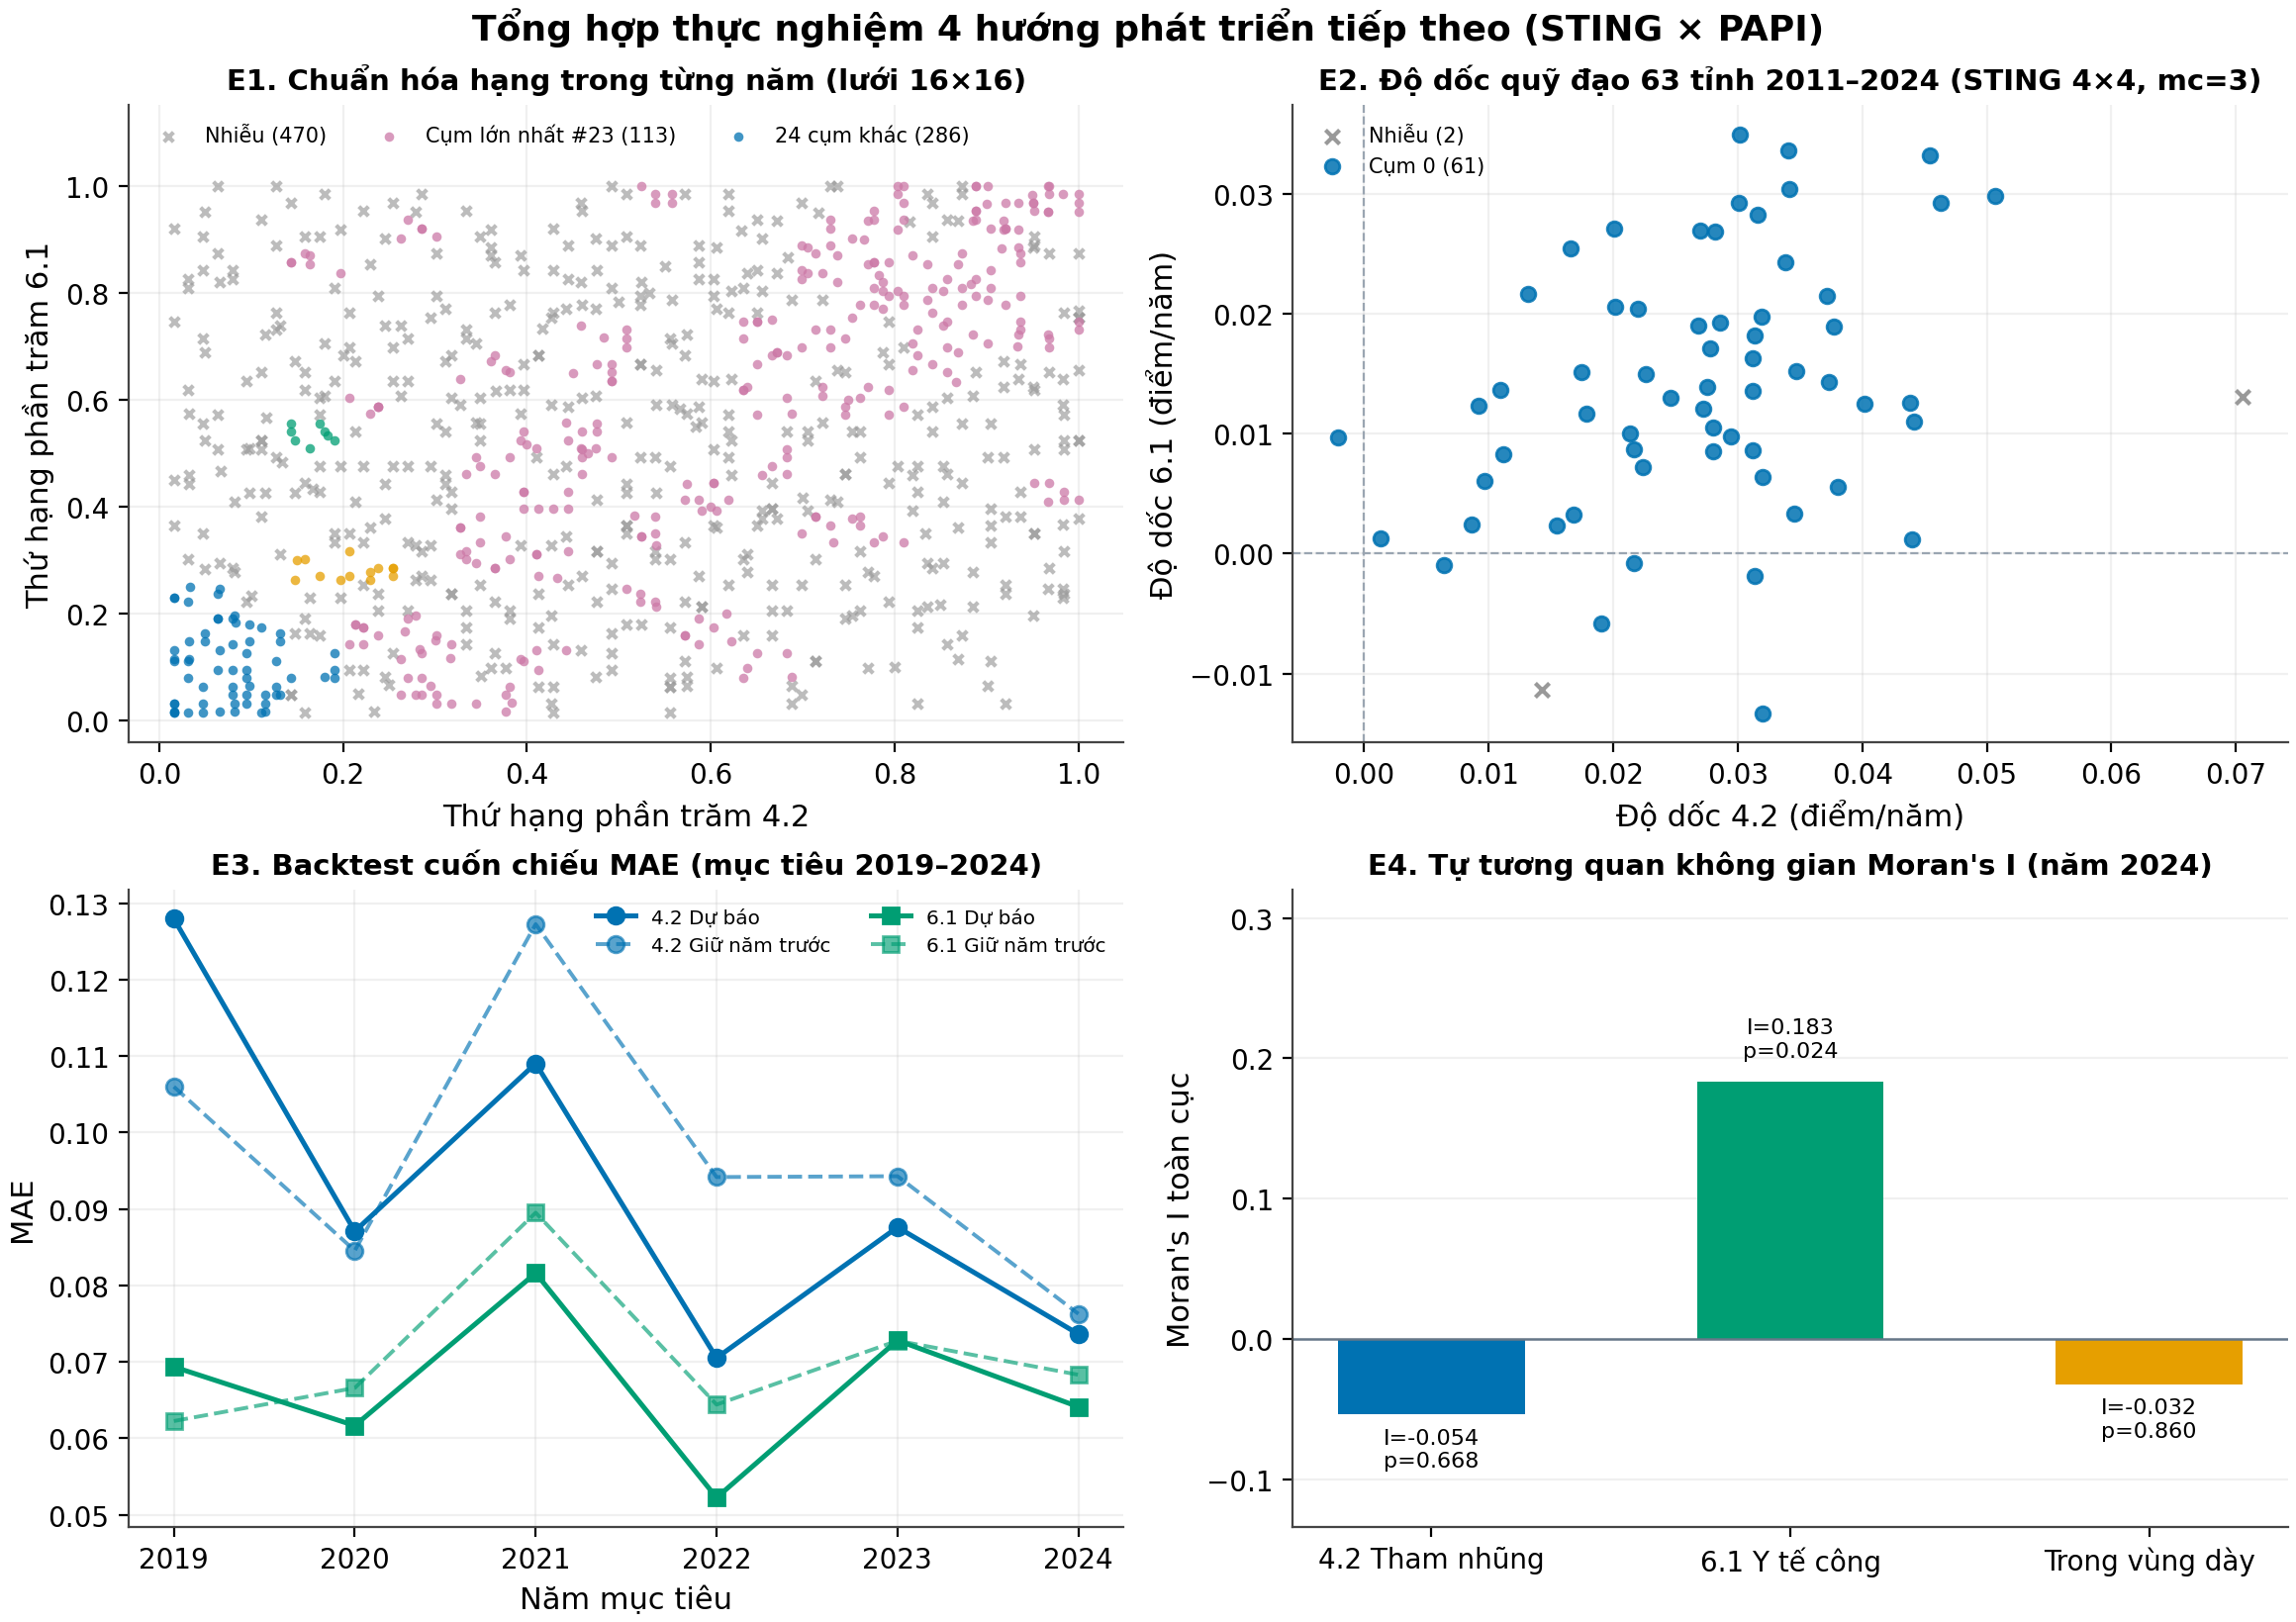

In [19]:
fw_bt = pd.read_csv(ROOT / "results/future_work_backtest.csv")
fw_sp = pd.read_csv(ROOT / "results/future_work_spatial.csv")
fw_tr = pd.read_csv(ROOT / "results/future_work_trajectory.csv")
show_md(fw_bt[["origin_year", "target_year", "target", "selected_method", "mae_forecast", "mae_carry", "mae_gain", "out_recall_forecast", "out_recall_carry"]].round(4).to_markdown(index=False))
show_md(fw_sp.round(4).to_markdown(index=False))
top_bot = pd.concat([fw_tr.nlargest(3, "slope_6_1"), fw_tr.nsmallest(3, "slope_6_1")])
show_md(top_bot[["province_vi", "n_years", "slope_4_2", "slope_6_1", "sting_label", "kmeans_label"]].round(4).to_markdown(index=False))
display(Image(filename=str(ROOT / "results/figs/future_work_overview.png")))

## Phụ lục E. Phân tích hồi quy chuyên sâu (17 cấu hình, AR(1) vs Δ6.1, VIF & Conformal 90%)

Tổng hợp nghiên cứu mở rộng nhánh hồi quy `6.1` trên cùng `740` cặp train (`2011–2022`), `6` fold expanding origin (`2017–2022`) và `59` tỉnh holdout (`2023→2024`) từ `scripts/supervised/regression_deep_analysis.py`: (i) đối chiếu OLS, Ridge, Lasso, ElasticNet, Decision Tree, RF, KNN, SVR, HistGB, Panel FE (`OneHot 63 tỉnh`) và cơ chế `AR(1)` vs mô hình sai phân `Δ6.1 = y_{t+1} - y_t`; (ii) hệ số chuẩn hóa Z-score & đa cộng tuyến VIF; (iii) kiểm định cặp Wilcoxon & Bootstrap CI 95%; và (iv) khoảng dự báo Conformal 80%/90% hiệu chỉnh thuần trên CV `≤ 2022`.

So sánh các cấu hình hồi quy (CV R2, CV MAE, Holdout MAE/RMSE/R2):


| item                                             |   metric_primary |   metric_secondary |   holdout_mae |   holdout_rmse |   holdout_r2 | note                                                                                        |
|:-------------------------------------------------|-----------------:|-------------------:|--------------:|---------------:|-------------:|:--------------------------------------------------------------------------------------------|
| Giữ nguyên năm trước (carry-forward)             |           0.1453 |             0.0719 |        0.0683 |         0.0875 |        0.198 | params=mặc định; beats_ridge=2/6; beats_carry=0/6; bias=+0.0333                             |
| Trung bình tập huấn luyện                        |          -0.7703 |             0.1076 |        0.0814 |         0.1027 |       -0.105 | params=mặc định; beats_ridge=0/6; beats_carry=0/6; bias=+0.0317                             |
| AR(1) OLS (chỉ 6.1)                              |           0.2679 |             0.0675 |        0.0621 |         0.0745 |        0.419 | params=mặc định; beats_ridge=4/6; beats_carry=5/6; bias=+0.0246                             |
| AR(1) Ridge (chỉ 6.1)                            |           0.2678 |             0.0675 |        0.0621 |         0.0745 |        0.419 | params=alpha=0.1; beats_ridge=4/6; beats_carry=5/6; bias=+0.0246                            |
| OLS LinearRegression (8 đặc trưng)               |           0.2652 |             0.0671 |        0.064  |         0.0769 |        0.381 | params=mặc định; beats_ridge=2/6; beats_carry=4/6; bias=+0.0304                             |
| Ridge (8 đặc trưng, chính thức)                  |           0.2652 |             0.0671 |        0.064  |         0.0769 |        0.381 | params=alpha=0.1; beats_ridge=0/6; beats_carry=4/6; bias=+0.0304                            |
| Lasso L1 (8 đặc trưng)                           |           0.2692 |             0.0671 |        0.0637 |         0.0762 |        0.391 | params=alpha=0.001; beats_ridge=4/6; beats_carry=4/6; bias=+0.0298                          |
| ElasticNet L1+L2 (8 đặc trưng)                   |           0.2689 |             0.0671 |        0.0637 |         0.0762 |        0.393 | params=alpha=0.005, l1_ratio=0.2; beats_ridge=4/6; beats_carry=4/6; bias=+0.0297            |
| Decision Tree (8 đặc trưng)                      |           0.2028 |             0.0709 |        0.0631 |         0.0783 |        0.359 | params=max_depth=2, min_samples_leaf=5; beats_ridge=0/6; beats_carry=4/6; bias=+0.0170      |
| Random Forest (8 đặc trưng, chính thức)          |           0.1966 |             0.0706 |        0.0616 |         0.0742 |        0.423 | params=max_depth=4, min_samples_leaf=2; beats_ridge=1/6; beats_carry=4/6; bias=+0.0225      |
| KNN Regressor (8 đặc trưng)                      |           0.1677 |             0.0713 |        0.0586 |         0.076  |        0.396 | params=n_neighbors=20, weights=distance; beats_ridge=0/6; beats_carry=4/6; bias=+0.0144     |
| SVR RBF (8 đặc trưng)                            |           0.1846 |             0.0699 |        0.0643 |         0.0809 |        0.314 | params=C=0.1, epsilon=0.05; beats_ridge=1/6; beats_carry=3/6; bias=+0.0264                  |
| HistGradientBoosting (8 đặc trưng)               |           0.1811 |             0.0712 |        0.0646 |         0.0783 |        0.358 | params=learning_rate=0.03, max_leaf_nodes=8; beats_ridge=1/6; beats_carry=4/6; bias=+0.0303 |
| Ablation Ridge (7 đặc trưng, bỏ 6.1)             |          -0.2637 |             0.0881 |        0.0658 |         0.0824 |        0.289 | params=alpha=0.1; beats_ridge=1/6; beats_carry=1/6; bias=+0.0136                            |
| Mô hình sai phân Δ6.1 = y(t+1)-y(t) (Ridge)      |           0.2732 |             0.0667 |        0.0645 |         0.0774 |        0.372 | params=alpha=50.0; beats_ridge=3/6; beats_carry=5/6; bias=+0.0312                           |
| Mô hình sai phân Δ6.1 = y(t+1)-y(t) (ElasticNet) |           0.2715 |             0.067  |        0.064  |         0.0765 |        0.388 | params=alpha=0.01, l1_ratio=0.2; beats_ridge=3/6; beats_carry=5/6; bias=+0.0299             |
| Panel FE: Ridge + OneHot 63 tỉnh                 |           0.2686 |             0.0674 |        0.0605 |         0.0743 |        0.422 | params=alpha=10.0; beats_ridge=4/6; beats_carry=5/6; bias=+0.0285                           |

Hệ số chuẩn hóa (beta_ridge, beta_elasticnet, beta_lasso, beta_ols) & VIF:


| Chỉ tiêu                                                           |   β Ridge |   β ElasticNet |   β Lasso |   β OLS |   VIF |
|:-------------------------------------------------------------------|----------:|---------------:|----------:|--------:|------:|
| sd_1_3 (1.3 Chất lượng bầu cử)                                     |    0.003  |         0.0035 |    0.0035 |  0.003  | 1.417 |
| sd_1_4 (1.4 Đóng góp tự nguyện)                                    |    0.0115 |         0.0106 |    0.0106 |  0.0115 | 1.408 |
| sd_4_1 (4.1 Kiểm soát tham nhũng trong chính quyền địa phương)     |    0.0051 |         0.0035 |    0.0035 |  0.0051 | 4.209 |
| sd_4_2 (4.2 Kiểm soát tham nhũng trong cung ứng dịch vụ công)      |    0.0092 |         0.0046 |    0.0045 |  0.0092 | 5.005 |
| sd_4_3 (4.3 Công bằng trong tuyển dụng vào khu vực công)           |   -0.0126 |        -0.0069 |   -0.007  | -0.0126 | 3.757 |
| sd_4_4 (4.4 Quyết tâm chống tham nhũng của chính quyền địa phương) |   -0.008  |        -0.006  |   -0.0061 | -0.008  | 1.616 |
| sd_6_1 (6.1 Y tế công lập)                                         |    0.0891 |         0.0885 |    0.089  |  0.0891 | 1.482 |
| sd_6_3 (6.3 Cơ sở hạ tầng căn bản)                                 |   -0.003  |        -0.0029 |   -0.0028 | -0.003  | 1.338 |

Kiểm định cặp Wilcoxon + Bootstrap CI95 và hiệu chỉnh Conformal 80%/90%:


| section     | item                                           |   metric_primary |   metric_secondary |   holdout_mae |   holdout_rmse |   holdout_r2 | note                                                  |
|:------------|:-----------------------------------------------|-----------------:|-------------------:|--------------:|---------------:|-------------:|:------------------------------------------------------|
| paired_test | OOF CV 2017–2022: Ridge vs Carry-Forward       |         -0.00476 |            0.01939 |        0.0671 |         0.0719 |        0.549 | n=366; CI95=[-0.00800, -0.00148]; improved=201/366    |
| paired_test | Holdout 2023→2024: Ridge vs Carry-Forward      |         -0.0043  |            0.3937  |        0.064  |         0.0683 |        0.576 | n=59; CI95=[-0.01285, +0.00356]; improved=34/59       |
| paired_test | OOF CV 2017–2022: AR(1) Ridge vs Carry-Forward |         -0.00436 |            0.01893 |        0.0675 |         0.0719 |        0.527 | n=366; CI95=[-0.00743, -0.00144]; improved=193/366    |
| paired_test | OOF CV 2017–2022: ElasticNet vs Ridge          |         -1e-05   |            0.89454 |        0.0671 |         0.0671 |        0.484 | n=366; CI95=[-0.00045, +0.00043]; improved=177/366    |
| paired_test | Holdout 2023→2024: ElasticNet vs Ridge         |         -0.00033 |            0.42366 |        0.0637 |         0.064  |        0.525 | n=59; CI95=[-0.00110, +0.00039]; improved=31/59       |
| conformal   | Conformal 80% (OOF 2017–2022)                  |          0.8814  |            0.1063  |        0.2125 |       nan      |        0.8   | nominal=0.80; calibrated on OOF |y-pred| <=2022       |
| conformal   | Conformal 90% (OOF 2017–2022)                  |          0.9492  |            0.1403  |        0.2806 |       nan      |        0.9   | nominal=0.90; lo90<1.7848 alerts=28 (low61 catch=4/4) |
| conformal   | Conformal 90% (Gần nhất 2021–2022)             |          0.9322  |            0.1219  |        0.2437 |       nan      |        0.9   | nominal=0.90; recent 2 folds calibration              |
| conformal   | Quantile GBR [q10, q90] (80%)                  |          0.8305  |            0.0978  |        0.1955 |       nan      |        0.8   | asymmetric GradientBoosting quantile regression       |

Độ phủ Conformal 90% trên 59 tỉnh holdout 2024: 94.9%


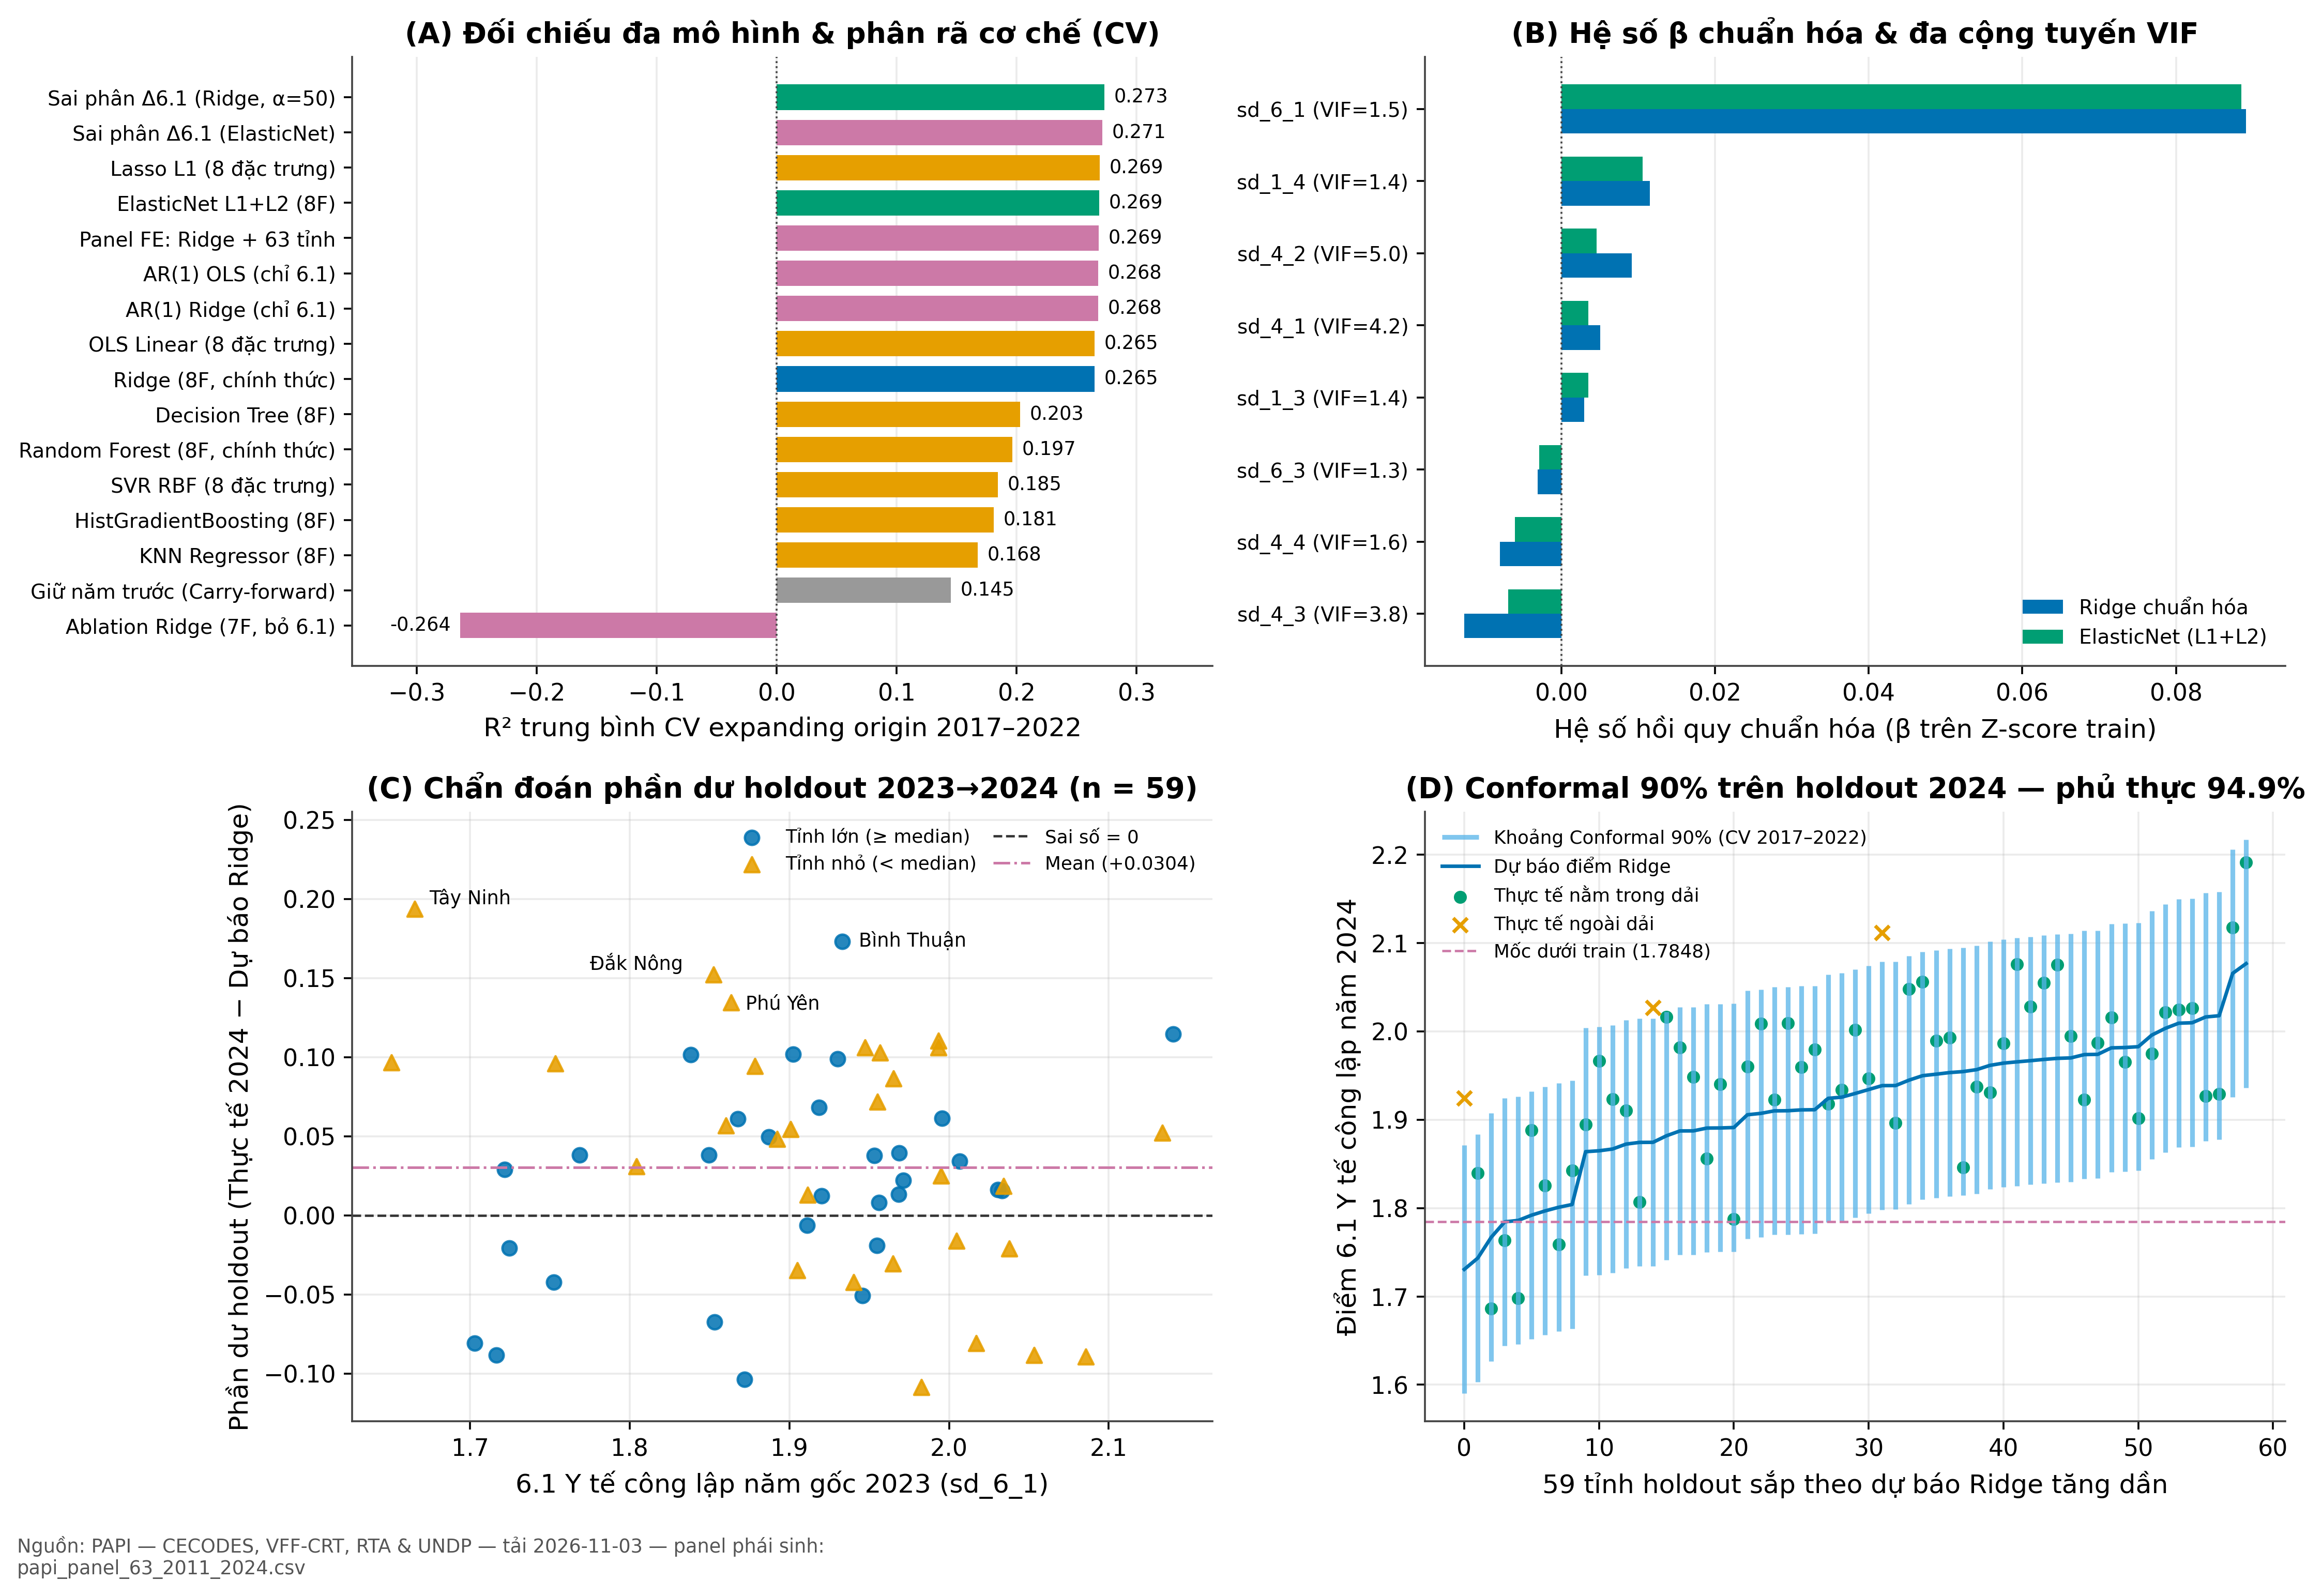

In [20]:
reg_deep = pd.read_csv(ROOT / "results/regression_deep_analysis.csv")
reg_conf = pd.read_csv(ROOT / "results/regression_conformal_2024.csv")
print("So sánh các cấu hình hồi quy (CV R2, CV MAE, Holdout MAE/RMSE/R2):")
show_md(reg_deep[reg_deep["section"].str.startswith("model_")].drop(columns=["section"]).to_markdown(index=False))
print("Hệ số chuẩn hóa (beta_ridge, beta_elasticnet, beta_lasso, beta_ols) & VIF:")
show_md(reg_deep[reg_deep["section"] == "coef_and_vif"][["item", "metric_primary", "metric_secondary", "holdout_mae", "holdout_rmse", "holdout_r2"]].rename(columns={
    "item": "Chỉ tiêu", "metric_primary": "β Ridge", "metric_secondary": "β ElasticNet",
    "holdout_mae": "β Lasso", "holdout_rmse": "β OLS", "holdout_r2": "VIF"
}).to_markdown(index=False))
print("Kiểm định cặp Wilcoxon + Bootstrap CI95 và hiệu chỉnh Conformal 80%/90%:")
show_md(reg_deep[reg_deep["section"].isin(["paired_test", "conformal"])].to_markdown(index=False))
print(f"Độ phủ Conformal 90% trên 59 tỉnh holdout 2024: {reg_conf['covered_conformal_90'].mean():.1%}")
display(Image(filename=str(ROOT / "results/figs/regression_diagnostics_deep.png")))